# Cushion capability forecasting — executed research notebook

This notebook contains the saved industrial analysis for the accompanying case study. The industrial input data are proprietary and are not included. Reading the saved outputs does not require rerunning any cells; executing the full pipeline requires the original input schema, data and environment.

The analysis covers data preparation, TCN/GRU/LSTM comparison, residual calibration, stationary simulation, conditional forecasting, cycle-level coverage diagnostics, input sensitivity and timing.

**How to read this version.** Comments and explanatory text have been revised without executing the notebook. Code calculations, cell order and saved outputs are unchanged. Some saved print messages and plot labels retain earlier interpretations. In particular, Wilson bounds do not account for dependent origins, correlation does not establish causality, and cycle-level coverage does not establish coverage of capability-index intervals.

The embedded synthetic generator is illustrative. It does not reproduce the industrial results. Future-input deterministic diagnostics and frozen-recipe conditional forecasts are different evaluation modes.

Figures, tables and summaries are exported by the asset-bundle cell. The admissibility diagnostic follows that export.

**Public-copy note.** The saved raw-record table preview from the data-loading cell has been removed. Calculation code, aggregate results and research figures are retained. The code still contains the preview command, which should only be run with data authorised for the intended audience. No cells were executed when preparing this copy.


In [ ]:
# Install notebook dependencies in Colab. This does not supply the industrial dataset.

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Import the libraries used below.

import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import RobustScaler


In [ ]:
# Dataset, model and simulation settings.
# The internal process limits are specific to this production cell.
# MAD-based thresholds are estimated from the available data.

DATA_PATH = "Samples.csv"   # update if needed
DELIMITER = ";"                                   # input delimiter
TIMESTAMP_COL = "timestamp"
TARGET_COL = "Material_Cushion"                   # measured cushion column
CUSHION_INPUT_COL = "Cushion_in"   # name used in FEATURES for cushion history
MAX_GAP_SECONDS = 180  # start a new segment above this timestamp gap

H = 1  # one-step-ahead delta target (the model predicts ΔCushion(t) only)
HISTORY = 25            # past cycles given to the model (sequence length)
SEQ_LEN = HISTORY
FORECAST_STEPS = 20     # how many future cushions to predict in the forecast plot
HIST_PLOT = 20          # how many history points to show on the plot

TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15      # test is the rest

EPOCHS = 80
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
PATIENCE = 10           # early stopping patience
GRAD_CLIP = 1.0

HIDDEN_SIZE = 64
NUM_LAYERS = 2
DROPOUT = 0.1

RANDOM_SEED = 42

TARGET_CUSHION = 10.33
LSL_DEV, USL_DEV = -0.3, +0.3
LSL = TARGET_CUSHION + LSL_DEV
USL = TARGET_CUSHION + USL_DEV

ROBUST_K = 5.0
def mad_sigma(x):
    """Robust sigma estimate (MAD scaled to be sigma-consistent for Gaussians)."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    return float(1.4826 * np.median(np.abs(x - np.median(x))))


### Figure export

Save figures as PDF and PNG and record their filenames in a manifest.


In [ ]:
# Save figures and mirror them to ARTICLE_ASSETS/figures as PDF and PNG.
# The manifest records the export order and filenames.

import os
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.figure import Figure

ASSETS     = Path("ARTICLE_ASSETS")
ASSETS_FIG = ASSETS / "figures"
ASSETS_TAB = ASSETS / "tables"
for _d in (ASSETS_FIG, ASSETS_TAB):
    _d.mkdir(parents=True, exist_ok=True)

FIGURE_MANIFEST = []
_ASSET_GUARD = {"busy": False}

matplotlib.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.grid": False,
})

_orig_savefig = Figure.savefig


def _asset_savefig(self, fname, *args, **kwargs):
    """Save as requested, then mirror into ARTICLE_ASSETS as PDF + 600 dpi PNG."""
    out = _orig_savefig(self, fname, *args, **kwargs)
    if _ASSET_GUARD["busy"]:
        return out
    try:
        stem = Path(str(fname)).stem
        if not stem:
            return out
        _ASSET_GUARD["busy"] = True
        n = len(FIGURE_MANIFEST) + 1
        base = f"F{n:02d}_{stem}"
        pdf_path = ASSETS_FIG / f"{base}.pdf"
        png_path = ASSETS_FIG / f"{base}.png"
        _orig_savefig(self, pdf_path, bbox_inches="tight")
        _orig_savefig(self, png_path, dpi=600, bbox_inches="tight")
        FIGURE_MANIFEST.append({
            "order": n,
            "source_name": stem,
            "pdf": str(pdf_path),
            "png": str(png_path),
            "size_in": tuple(round(float(v), 2) for v in self.get_size_inches()),
        })
    except Exception as _e:
        print(f"[assets] could not mirror '{fname}': {_e}")
    finally:
        _ASSET_GUARD["busy"] = False
    return out


Figure.savefig = _asset_savefig
print(f"[assets] capture active -> {ASSETS_FIG}/")
print("[assets] every figure will be written as vector PDF + 600 dpi PNG, numbered in order")


[assets] capture active -> ARTICLE_ASSETS/figures/
[assets] every figure will be written as vector PDF + 600 dpi PNG, numbered in order


In [ ]:
# Set random seeds and select the available device.

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

assert HIST_PLOT <= HISTORY, "HIST_PLOT must be <= HISTORY"


Using device: cuda


In [ ]:
# Load the cycle records, parse timestamps and identify production segments.

df = pd.read_csv(DATA_PATH, delimiter=DELIMITER)

df[TIMESTAMP_COL] = pd.to_datetime(df[TIMESTAMP_COL], dayfirst=True, errors="coerce")
df = df.dropna(subset=[TIMESTAMP_COL]).sort_values(TIMESTAMP_COL).reset_index(drop=True)

df["dt_sec"] = df[TIMESTAMP_COL].diff().dt.total_seconds()
df["segment"] = (df["dt_sec"] > MAX_GAP_SECONDS).cumsum()
df.drop(columns=["dt_sec"], inplace=True)

print("Rows:", len(df), "| Segments:", df["segment"].nunique())
df.head()


Rows: 25788 | Segments: 19


In [ ]:
# Select recorded process variables and add same-cycle cushion history.
# Several inputs are achieved values, not independently adjustable setpoints.

RECIPE_FEATURES = [
    "Maximum_Injection_Pressure",
    "Switch_Over_Pressure",
    "Injection_Time",
    "Dosing_Time",

    "Back_pressure_ActValue",
    "SwitchOver_volume_ActValue",
    "Dosing_Volume_ActValue",
]

CUSHION_IN_COL = "Cushion_in"

df[CUSHION_IN_COL] = df[TARGET_COL].astype(float)

FEATURES = RECIPE_FEATURES + [CUSHION_IN_COL]

needed = [TIMESTAMP_COL, "segment"] + FEATURES + [TARGET_COL]
df = df[needed].copy()
df = df.dropna().reset_index(drop=True)

print("Kept rows after dropna:", len(df))
print("FEATURES:", FEATURES)


Kept rows after dropna: 25788
FEATURES: ['Maximum_Injection_Pressure', 'Switch_Over_Pressure', 'Injection_Time', 'Dosing_Time', 'Back_pressure_ActValue', 'SwitchOver_volume_ActValue', 'Dosing_Volume_ActValue', 'Cushion_in']


In [ ]:
# Split the records chronologically and retain unscaled copies.

n = len(df)
train_end = int(TRAIN_RATIO * n)
val_end = int((TRAIN_RATIO + VAL_RATIO) * n)

df_train = df.iloc[:train_end].copy()
df_val   = df.iloc[train_end:val_end].copy()
df_test  = df.iloc[val_end:].copy()

df_train_raw = df_train.copy()
df_val_raw   = df_val.copy()
df_test_raw  = df_test.copy()

print("Train/Val/Test:", len(df_train), len(df_val), len(df_test))


Train/Val/Test: 18051 3868 3869


In [ ]:
# Calculate cushion increments within each segment and split.
# Drop rows without a preceding cycle and keep raw/scaled frames aligned.

def add_delta_and_filter(df_scaled, df_raw, target_col, seg_col="segment"):
    df_scaled = df_scaled.copy()
    df_raw = df_raw.copy()

    prev = df_raw.groupby(seg_col)[target_col].shift(1)
    df_raw["Cushion_prev"] = prev
    df_raw["Delta_Cushion"] = df_raw[target_col] - df_raw["Cushion_prev"]

    valid_mask = prev.notna().values

    df_raw = df_raw.loc[valid_mask].reset_index(drop=True)
    df_scaled = df_scaled.loc[valid_mask].reset_index(drop=True)

    return df_scaled, df_raw

df_train, df_train_raw = add_delta_and_filter(df_train, df_train_raw, TARGET_COL, "segment")
df_val,   df_val_raw   = add_delta_and_filter(df_val,   df_val_raw,   TARGET_COL, "segment")
df_test,  df_test_raw  = add_delta_and_filter(df_test,  df_test_raw,  TARGET_COL, "segment")

print("After delta filtering:")
print("Train/Val/Test:", len(df_train), len(df_val), len(df_test))
print("Delta stats (train): mean=", float(df_train_raw["Delta_Cushion"].mean()),
      "std=", float(df_train_raw["Delta_Cushion"].std(ddof=1)))


After delta filtering:
Train/Val/Test: 18033 3867 3867
Delta stats (train): mean= -1.6636271834966951e-06 std= 0.13352628632324895


In [ ]:
# Summarise the modelling frame and the screened comparison frame.
# The dosing-time calculation is a model-sensitivity check, not a physical intervention.

import numpy as np
import pandas as pd

try:
    frame = pd.concat([df_train_raw, df_val_raw, df_test_raw], ignore_index=True)
except NameError as e:
    raise NameError(
        "Run the cells above first, up to and including the delta-target cell. "
        f"Missing: {e}"
    )
print(f"Preprocessed modelling frame: {len(frame):,} cycles "
      f"(expected 25,767), {frame['segment'].nunique()} segments\n")

ROWS = [
    ("Maximum injection pressure", "p_max",  "bar", "Maximum_Injection_Pressure"),
    ("Switch-over pressure",       "p_SO",   "bar", "Switch_Over_Pressure"),
    ("Injection time",             "t_inj",  "s",   "Injection_Time"),
    ("Dosing time",                "t_dos",  "s",   "Dosing_Time"),
    ("Back pressure",              "p_back", "bar", "Back_pressure_ActValue"),
    ("Switch-over volume",         "V_SO",   "cm3", "SwitchOver_volume_ActValue"),
    ("Dosing volume",              "V_dos",  "cm3", "Dosing_Volume_ActValue"),
    ("Material cushion",           "C",      "mm",  TARGET_COL),
]
missing = [c for *_, c in ROWS if c not in frame.columns]
if missing:
    raise KeyError(f"Not in the frame: {missing}\nAvailable: {list(frame.columns)}")

def _smad(x, floor):
    return max(1.4826 * float(np.median(np.abs(x - np.median(x)))), floor)

_c = frame[TARGET_COL].astype(float).to_numpy()
_d = np.diff(_c, prepend=_c[0])
_keep = ~((np.abs(_d - np.median(_d)) > 5.0 * _smad(_d, 0.01)) |
          (np.abs(_c - np.median(_c)) > 5.0 * _smad(_c, 0.01)))
screened = frame.loc[_keep].reset_index(drop=True)
print(f"Screens remove {len(frame) - len(screened)} cycles "
      f"(expected 119) -> {len(screened):,} remain\n")

def _stats(d, col):
    x = pd.to_numeric(d[col], errors="coerce").dropna().to_numpy()
    m, s = x.mean(), x.std(ddof=1)
    return m, s, (100.0 * s / abs(m) if m else np.nan), x.min(), x.max(), len(x)

recs = []
for label, sym, unit, col in ROWS:
    m, s, cov, lo, hi, n = _stats(frame, col)
    _, _, cov_s, _, _, _ = _stats(screened, col)
    recs.append({"Variable": label, "Symbol": sym, "Unit": unit, "Mean": m,
                 "SD": s, "CoV %": cov, "CoV % screened": cov_s,
                 "Min": lo, "Max": hi, "n": n})
t1 = pd.DataFrame(recs)
print(t1.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

def _f(v, u):
    return f"{v:.1f}" if u == "bar" else (f"{v:.4f}" if u == "mm" else f"{v:.3f}")

print("\n\n--- paste into the manuscript ---\n")
print("| Variable | Symbol | Unit | Mean | SD | CoV (%) | Min | Max |")
print("|---|---|---|---|---|---|---|---|")
for r in recs:
    u = r["Unit"]
    print(f"| {r['Variable']} | *{r['Symbol']}* | {u} | {_f(r['Mean'],u)} | "
          f"{_f(r['SD'],u)} | {r['CoV %']:.1f} | {_f(r['Min'],u)} | {_f(r['Max'],u)} |")

dos  = float(t1.loc[t1.Symbol == "t_dos", "CoV %"].iloc[0])
dosS = float(t1.loc[t1.Symbol == "t_dos", "CoV % screened"].iloc[0])
sig  = float(t1.loc[t1.Symbol == "C", "SD"].iloc[0])

print("\n\n--- review point 17: Dosing_Time coefficient of variation ---")
print(f"  JESA draft, raw export        : 17.4 %")
print(f"  Preprocessed frame (25,767)   : {dos:.1f} %")
print(f"  After the Section 3.3 screens : {dosS:.1f} %")

GAIN = 0.007427 / 4.0          # mm of cushion per 1 % of dosing time
implied = GAIN * dosS
print(f"\n--- cross-check against the Section 5.5 sweep ---")
print(f"  Sweep gain                        : {GAIN:.6f} mm per 1 %")
print(f"  Implied cushion dispersion at {dosS:.1f} %: {implied:.4f} mm")
print(f"  Measured cushion SD               : {sig:.4f} mm")
if implied > sig:
    print(f"\n  *** CONTRADICTION: dosing time alone would explain "
          f"{100*implied/sig:.0f} % of the")
    print( "      total cushion variation. Two of the paper's own numbers "
           "disagree.")
    print( "      Do not submit until this is resolved.")
else:
    print(f"\n  OK: {100*implied/sig:.0f} % of the total cushion variation. "
          "Consistent.")

t1.to_csv("Table1_preprocessed.csv", index=False)
print("\nsaved: Table1_preprocessed.csv")

Preprocessed modelling frame: 25,767 cycles (expected 25,767), 17 segments

Screens remove 119 cycles (expected 119) -> 25,648 remain

                  Variable Symbol Unit      Mean      SD   CoV %  CoV % screened      Min       Max     n
Maximum injection pressure  p_max  bar 1531.1461 68.3209  4.4621          4.3781 932.9000 2138.6001 25767
      Switch-over pressure   p_SO  bar 1530.0619 68.2413  4.4600          4.3734 932.8000 2136.3000 25767
            Injection time  t_inj    s    1.0181  0.0108  1.0640          0.6228   1.0099    2.1620 25767
               Dosing time  t_dos    s    2.4113  0.3950 16.3794          1.8997   0.0000   48.2396 25767
             Back pressure p_back  bar   67.6564  1.8569  2.7446          2.7213  23.3000   81.0000 25767
        Switch-over volume   V_SO  cm3   12.9960  0.0194  0.1489          0.0376   9.9900   13.0000 25767
             Dosing volume  V_dos  cm3   90.4484  0.9377  1.0367          0.5480  89.9400  199.8900 25767
          Materia

In [ ]:
# Compare the two pressure channels and report screened descriptive statistics.

import numpy as np, pandas as pd

a = frame["Maximum_Injection_Pressure"].astype(float)
b = frame["Switch_Over_Pressure"].astype(float)
print("correlation      :", round(a.corr(b), 6))
print("identical rows   :", int((a == b).sum()), "/", len(a))
print("max difference   :", round(float((a - b).abs().max()), 4))

COLS = [("Maximum injection pressure","p_max","bar","Maximum_Injection_Pressure"),
        ("Switch-over pressure","p_SO","bar","Switch_Over_Pressure"),
        ("Injection time","t_inj","s","Injection_Time"),
        ("Dosing time","t_dos","s","Dosing_Time"),
        ("Back pressure","p_back","bar","Back_pressure_ActValue"),
        ("Switch-over volume","V_SO","cm3","SwitchOver_volume_ActValue"),
        ("Dosing volume","V_dos","cm3","Dosing_Volume_ActValue"),
        ("Material cushion","C","mm",TARGET_COL)]

print("\n| Variable | Symbol | Unit | Mean | SD | CoV (%) | Min | Max |")
print("|---|---|---|---|---|---|---|---|")
for lab, sym, u, c in COLS:
    x = pd.to_numeric(screened[c], errors="coerce").dropna()
    m, s = x.mean(), x.std(ddof=1)
    f = (lambda v: f"{v:.1f}") if u=="bar" else ((lambda v: f"{v:.4f}") if u=="mm" else (lambda v: f"{v:.3f}"))
    print(f"| {lab} | *{sym}* | {u} | {f(m)} | {f(s)} | {100*s/abs(m):.1f} | {f(x.min())} | {f(x.max())} |")

correlation      : 0.997169
identical rows   : 1767 / 25767
max difference   : 386.4

| Variable | Symbol | Unit | Mean | SD | CoV (%) | Min | Max |
|---|---|---|---|---|---|---|---|
| Maximum injection pressure | *p_max* | bar | 1531.3 | 67.0 | 4.4 | 932.9 | 1984.6 |
| Switch-over pressure | *p_SO* | bar | 1530.3 | 66.9 | 4.4 | 932.8 | 1984.3 |
| Injection time | *t_inj* | s | 1.018 | 0.006 | 0.6 | 1.010 | 1.025 |
| Dosing time | *t_dos* | s | 2.408 | 0.046 | 1.9 | 0.000 | 2.778 |
| Back pressure | *p_back* | bar | 67.7 | 1.8 | 2.7 | 23.3 | 73.2 |
| Switch-over volume | *V_SO* | cm3 | 12.996 | 0.005 | 0.0 | 12.990 | 13.000 |
| Dosing volume | *V_dos* | cm3 | 90.439 | 0.496 | 0.5 | 89.940 | 90.970 |
| Material cushion | *C* | mm | 10.3563 | 0.0249 | 0.2 | 10.2300 | 10.5000 |


[anomaly rule] |ΔC| > 5.0 × MAD-σ(0.0148) = 0.0741  (derived from TRAIN)

=== Anomaly census per split (classical σ is inflated by rare events; bulk σ is the true process noise) ===


,split,n_cycles,anomalous_cycles,anomaly_rate_%,out_of_spec_cycles,sigma_dC_classical,sigma_dC_bulk
0,train,18033,80,0.444,34,0.1335,0.0201
1,val,3867,21,0.543,12,0.1871,0.0233
2,test,3867,3,0.078,0,0.0911,0.0236


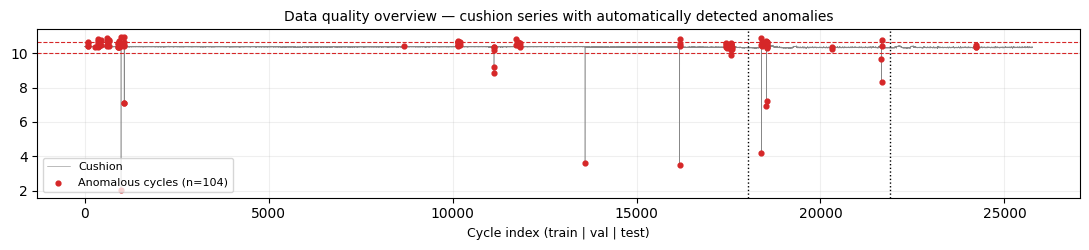

In [ ]:
# Count large increments using a training-derived MAD threshold.
# These flags identify process excursions; they are not measured part defects.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_dc_ref = df_train_raw["Delta_Cushion"].astype(float)
DC_MAD_SIGMA = mad_sigma(_dc_ref)
DC_ANOM_THR  = ROBUST_K * DC_MAD_SIGMA
print(f"[anomaly rule] |ΔC| > {ROBUST_K:.1f} × MAD-σ({DC_MAD_SIGMA:.4f}) = {DC_ANOM_THR:.4f}  (derived from TRAIN)")

anomaly_census = {"threshold": DC_ANOM_THR, "mad_sigma": DC_MAD_SIGMA, "splits": {}}
rows = []
for name, d_raw in [("train", df_train_raw), ("val", df_val_raw), ("test", df_test_raw)]:
    dc = d_raw["Delta_Cushion"].astype(float)
    c  = d_raw[TARGET_COL].astype(float)
    is_anom = dc.abs() > DC_ANOM_THR
    bulk = dc[~is_anom]
    oos = ((c < LSL) | (c > USL))
    rec = {
        "split": name, "n_cycles": int(len(d_raw)),
        "anomalous_cycles": int(is_anom.sum()),
        "anomaly_rate_%": round(100*is_anom.mean(), 3),
        "out_of_spec_cycles": int(oos.sum()),
        "sigma_dC_classical": round(float(dc.std(ddof=1)), 4),
        "sigma_dC_bulk": round(float(bulk.std(ddof=1)), 4),
    }
    rows.append(rec)
    anomaly_census["splits"][name] = rec

df_anomaly_census = pd.DataFrame(rows)
print("\n=== Anomaly census per split (classical σ is inflated by rare events; bulk σ is the true process noise) ===")
display(df_anomaly_census)

fig, ax = plt.subplots(figsize=(11, 2.6))
_all = pd.concat([df_train_raw.assign(_s="train"), df_val_raw.assign(_s="val"),
                  df_test_raw.assign(_s="test")], ignore_index=True)
x = np.arange(len(_all))
ax.plot(x, _all[TARGET_COL].values, lw=0.4, color="#888", label="Cushion")
_an = _all["Delta_Cushion"].abs() > DC_ANOM_THR
ax.scatter(x[_an], _all.loc[_an, TARGET_COL], s=12, color="#D62728", zorder=3,
           label=f"Anomalous cycles (n={int(_an.sum())})")
for b in [len(df_train_raw), len(df_train_raw)+len(df_val_raw)]:
    ax.axvline(b, color="k", ls=":", lw=1)
ax.axhline(LSL, color="#D62728", ls="--", lw=0.8); ax.axhline(USL, color="#D62728", ls="--", lw=0.8)
ax.set_title("Data quality overview — cushion series with automatically detected anomalies", fontsize=10)
ax.set_xlabel("Cycle index (train | val | test)", fontsize=9)
ax.legend(fontsize=8, loc="lower left"); ax.grid(alpha=0.2)
plt.tight_layout(); plt.savefig("data_quality_overview.png", dpi=600, bbox_inches="tight")
plt.show()


In [ ]:
# Fit robust scalers on training data only, then transform all partitions.

from sklearn.preprocessing import RobustScaler

x_scaler = RobustScaler(quantile_range=(5, 95))
delta_scaler = RobustScaler(quantile_range=(5, 95))

x_scaler.fit(df_train_raw[FEATURES])
delta_scaler.fit(df_train_raw[["Delta_Cushion"]])

df_train[FEATURES] = x_scaler.transform(df_train_raw[FEATURES])
df_val[FEATURES]   = x_scaler.transform(df_val_raw[FEATURES])
df_test[FEATURES]  = x_scaler.transform(df_test_raw[FEATURES])

TARGET_SCALED_COL = "Delta_Cushion_scaled"
df_train[TARGET_SCALED_COL] = delta_scaler.transform(df_train_raw[["Delta_Cushion"]])
df_val[TARGET_SCALED_COL]   = delta_scaler.transform(df_val_raw[["Delta_Cushion"]])
df_test[TARGET_SCALED_COL]  = delta_scaler.transform(df_test_raw[["Delta_Cushion"]])

print("delta_scaler center (median):", float(delta_scaler.center_[0]))
print("delta_scaler scale (IQR):    ", float(delta_scaler.scale_[0]))


delta_scaler center (median): 0.0
delta_scaler scale (IQR):     0.060001360000001114


In [ ]:
# Build input histories ending at t-1 and scaled increment targets starting at t.
# Windows remain within one production segment; PRED_HORIZON is 1 in this run.

def build_sequences_multistep(df_scaled, features, target_scaled_col, seq_len, H):
    X, Y, seg_ids, pos_t = [], [], [], []

    for seg_id, seg in df_scaled.groupby("segment"):
        seg = seg.reset_index(drop=True)

        if len(seg) <= seq_len + H - 1:
            continue

        for i in range(len(seg) - seq_len - H + 1):
            t = i + seq_len

            x_seq = seg.loc[i:t-1, features].values.astype(np.float32)
            y_vec = seg.loc[t:t+H-1, target_scaled_col].values.astype(np.float32)  # length H

            X.append(x_seq)
            Y.append(y_vec)
            seg_ids.append(int(seg_id))
            pos_t.append(int(t))

    return (
        np.array(X, dtype=np.float32),
        np.array(Y, dtype=np.float32),   # (N, H)
        np.array(seg_ids, dtype=np.int64),
        np.array(pos_t, dtype=np.int64),
    )

X_train, Y_train, seg_train, pos_train = build_sequences_multistep(df_train, FEATURES, TARGET_SCALED_COL, SEQ_LEN, H)
X_val,   Y_val,   seg_val,   pos_val   = build_sequences_multistep(df_val,   FEATURES, TARGET_SCALED_COL, SEQ_LEN, H)
X_test,  Y_test,  seg_test,  pos_test  = build_sequences_multistep(df_test,  FEATURES, TARGET_SCALED_COL, SEQ_LEN, H)

print("X_train:", X_train.shape, "Y_train:", Y_train.shape)
print("X_val  :", X_val.shape,   "Y_val  :", Y_val.shape)
print("X_test :", X_test.shape,  "Y_test :", Y_test.shape)


X_train: (17737, 25, 8) Y_train: (17737, 1)
X_val  : (3842, 25, 8) Y_val  : (3842, 1)
X_test : (3817, 25, 8) Y_test : (3817, 1)


In [ ]:
# Wrap the sequence arrays in PyTorch datasets and data loaders.

from torch.utils.data import Dataset, DataLoader

class TimeSeriesDataset(Dataset):
    def __init__(self, X, Y):
        self.X = torch.tensor(X, dtype=torch.float32)  # (N, SEQ_LEN, n_features)
        self.Y = torch.tensor(Y, dtype=torch.float32)  # (N, H)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]

train_loader = DataLoader(
    TimeSeriesDataset(X_train, Y_train),
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False
)

val_loader = DataLoader(
    TimeSeriesDataset(X_val, Y_val),
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False
)

### One-step prediction intervals

Calibrate conformal and residual-bootstrap intervals on validation errors, then evaluate them on the test partition. These are one-step intervals, separate from the trajectory forecasts below.


In [ ]:
# Shared data, scaling, interval and evaluation helpers.

import copy
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

req = [
    "X_train", "Y_train", "X_val", "Y_val", "X_test", "Y_test",
    "FEATURES", "RECIPE_FEATURES", "SEQ_LEN", "TARGET_COL",
    "df_test", "df_test_raw", "df_train_raw", "delta_scaler", "x_scaler", "device"
]
missing = [r for r in req if r not in globals()]
if missing:
    raise RuntimeError(f"Missing required objects for experiment: {missing}")

EXP_RANDOM_SEED = 123
np.random.seed(EXP_RANDOM_SEED)
torch.manual_seed(EXP_RANDOM_SEED)

class ArrayDataset(Dataset):
    def __init__(self, X, Y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.Y = torch.tensor(Y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]


def make_loaders(Xtr, Ytr, Xv, Yv, batch_size=128):
    tr = DataLoader(ArrayDataset(Xtr, Ytr), batch_size=batch_size, shuffle=True, drop_last=False)
    va = DataLoader(ArrayDataset(Xv, Yv), batch_size=batch_size, shuffle=False, drop_last=False)
    return tr, va


def delta_scaled_to_real_vec(arr):
    arr = np.asarray(arr, dtype=np.float32).reshape(-1, 1)
    return delta_scaler.inverse_transform(arr).ravel()


def cushion_scaled_to_real(scaled_vals, feature_name="Cushion_in"):
    idx = FEATURES.index(feature_name)
    center = float(x_scaler.center_[idx])
    scale = float(x_scaler.scale_[idx])
    return np.asarray(scaled_vals, dtype=np.float32) * scale + center


def cushion_real_to_scaled(real_vals, feature_name="Cushion_in"):
    idx = FEATURES.index(feature_name)
    center = float(x_scaler.center_[idx])
    scale = float(x_scaler.scale_[idx])
    return (np.asarray(real_vals, dtype=np.float32) - center) / scale


def qhat_conformal(abs_errors, alpha=0.10):
    e = np.sort(np.asarray(abs_errors, dtype=float))
    n = len(e)
    if n == 0:
        return np.nan
    k = int(math.ceil((n + 1) * (1 - alpha)))
    k = min(max(k, 1), n)
    return float(e[k - 1])


def interval_metrics(y_true, lo, hi):
    y_true = np.asarray(y_true, dtype=float)
    lo = np.asarray(lo, dtype=float)
    hi = np.asarray(hi, dtype=float)
    cov = float(np.mean((y_true >= lo) & (y_true <= hi)))
    width = float(np.mean(hi - lo))
    return cov, width


In [ ]:
# Define TCN, GRU and LSTM predictors with a shared training routine.
# All models predict the next scaled cushion increment.

class GRUOneStep(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, dropout):
        super().__init__()
        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        out, _ = self.gru(x)
        return self.fc(out[:, -1, :]).squeeze(-1)


class LSTMOneStep(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, dropout):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :]).squeeze(-1)


class TCNBlock(nn.Module):
    def __init__(self, ch_in, ch_out, kernel=3, dilation=1, dropout=0.1):
        super().__init__()
        self.kernel = kernel
        self.dilation = dilation
        self.conv1 = nn.Conv1d(ch_in, ch_out, kernel_size=kernel, dilation=dilation)
        self.conv2 = nn.Conv1d(ch_out, ch_out, kernel_size=kernel, dilation=dilation)
        self.drop = nn.Dropout(dropout)
        self.down = nn.Conv1d(ch_in, ch_out, kernel_size=1) if ch_in != ch_out else nn.Identity()

    def _causal(self, x, conv):
        pad = (self.kernel - 1) * self.dilation
        x = F.pad(x, (pad, 0))
        return conv(x)

    def forward(self, x):
        y = torch.relu(self._causal(x, self.conv1))
        y = self.drop(y)
        y = torch.relu(self._causal(y, self.conv2))
        y = self.drop(y)
        return y + self.down(x)


class TCNOneStep(nn.Module):
    def __init__(self, input_dim, channels=(32, 32), kernel=3, dropout=0.1):
        super().__init__()
        blocks = []
        ch_prev = input_dim
        for i, ch in enumerate(channels):
            blocks.append(TCNBlock(ch_prev, ch, kernel=kernel, dilation=(2 ** i), dropout=dropout))
            ch_prev = ch
        self.blocks = nn.ModuleList(blocks)
        self.head = nn.Linear(ch_prev, 1)

    def forward(self, x):
        y = x.transpose(1, 2)
        for b in self.blocks:
            y = b(y)
        last = y[:, :, -1]
        return self.head(last).squeeze(-1)


def train_model(model, train_loader, val_loader, epochs=60, lr=1e-3, wd=1e-5, patience=8, clip=1.0):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=3)
    crit = nn.SmoothL1Loss(beta=0.2)

    best_val = float("inf")
    best_state = None
    wait = 0
    train_hist, val_hist = [], []

    for ep in range(epochs):
        model.train()
        tl = []
        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb[:, 0].to(device) if yb.ndim == 2 else yb.to(device)
            opt.zero_grad()
            pr = model(xb)
            loss = crit(pr, yb)
            loss.backward()
            if clip is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            tl.append(float(loss.item()))

        model.eval()
        vl = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                yb = yb[:, 0].to(device) if yb.ndim == 2 else yb.to(device)
                pr = model(xb)
                vl.append(float(crit(pr, yb).item()))

        trm = float(np.mean(tl))
        vam = float(np.mean(vl))
        train_hist.append(trm)
        val_hist.append(vam)
        sch.step(vam)

        if vam < best_val - 1e-5:
            best_val = vam
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1

        if wait >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, float(best_val), train_hist, val_hist


In [ ]:
# Train each architecture using the same input features and training protocol.

mask_full = np.arange(len(FEATURES))
Xtr_full, Xva_full, Xte_full = X_train[:, :, mask_full], X_val[:, :, mask_full], X_test[:, :, mask_full]
tr_full, va_full = make_loaders(Xtr_full, Y_train, Xva_full, Y_val, batch_size=128)

import time as _time
_train_t0 = _time.time()
experiment_models = {}

m_tcn = TCNOneStep(input_dim=Xtr_full.shape[-1], channels=(HIDDEN_SIZE, HIDDEN_SIZE), kernel=3, dropout=DROPOUT)
m_tcn, v_tcn, tr_tcn, va_tcn = train_model(m_tcn, tr_full, va_full)
experiment_models["TCN"] = {
    "model": m_tcn,
    "mask": mask_full,
    "feature_names": [FEATURES[i] for i in mask_full],
    "val_loss": float(v_tcn),
    "train_loss_hist": tr_tcn,
    "val_loss_hist": va_tcn,
}

m_gru = GRUOneStep(input_dim=Xtr_full.shape[-1], hidden_dim=HIDDEN_SIZE, num_layers=NUM_LAYERS, dropout=DROPOUT)
m_gru, v_gru, tr_gru, va_gru = train_model(m_gru, tr_full, va_full)
experiment_models["GRU"] = {
    "model": m_gru,
    "mask": mask_full,
    "feature_names": [FEATURES[i] for i in mask_full],
    "val_loss": float(v_gru),
    "train_loss_hist": tr_gru,
    "val_loss_hist": va_gru,
}

m_lstm = LSTMOneStep(input_dim=Xtr_full.shape[-1], hidden_dim=HIDDEN_SIZE, num_layers=NUM_LAYERS, dropout=DROPOUT)
m_lstm, v_lstm, tr_lstm, va_lstm = train_model(m_lstm, tr_full, va_full)
experiment_models["LSTM"] = {
    "model": m_lstm,
    "mask": mask_full,
    "feature_names": [FEATURES[i] for i in mask_full],
    "val_loss": float(v_lstm),
    "train_loss_hist": tr_lstm,
    "val_loss_hist": va_lstm,
}

tcn_model = m_tcn
gru_model = m_gru
lstm_model = m_lstm

print("Trained models (best validation loss):")
for k, v in experiment_models.items():
    print(f"- {k}: {v['val_loss']:.5f}")

TRAINING_SECONDS = float(_time.time() - _train_t0)
print(f"Total training time: {TRAINING_SECONDS:.1f} s")


Trained models (best validation loss):
- TCN: 0.20129
- GRU: 0.24471
- LSTM: 0.24426
Total training time: 49.8 s


In [ ]:
# Evaluate deterministic rollouts and model sensitivity to altered inputs.
# The rollout uses recorded future exogenous inputs; it is not the frozen-recipe
# on-demand forecast. Input perturbations do not identify physical causal effects.

from collections import defaultdict


def predict_delta_scaled(model, X, batch=512):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            xb = torch.tensor(X[i:i+batch], dtype=torch.float32, device=device)
            pr = model(xb).detach().cpu().numpy().reshape(-1)
            out.append(pr)
    return np.concatenate(out) if out else np.array([], dtype=np.float32)


def rollout_rmse_on_test(model, feature_names, horizon=20, max_windows=300):
    model.eval()
    err2 = []
    sampled = 0

    by_seg_scaled = {int(s): g.reset_index(drop=True) for s, g in df_test.groupby("segment")}
    by_seg_raw = {int(s): g.reset_index(drop=True) for s, g in df_test_raw.groupby("segment")}

    has_cush = "Cushion_in" in feature_names

    for seg_id, seg_s in by_seg_scaled.items():
        if seg_id not in by_seg_raw:
            continue
        seg_r = by_seg_raw[seg_id]
        n = len(seg_s)
        if n <= SEQ_LEN + horizon:
            continue

        start_candidates = list(range(SEQ_LEN, n - horizon))
        if len(start_candidates) > 25:
            start_candidates = start_candidates[:25]

        for t0 in start_candidates:
            hist = seg_s.loc[t0-SEQ_LEN:t0-1, feature_names].values.astype(np.float32).copy()
            prev_real = float(seg_r.loc[t0-1, TARGET_COL])

            for h in range(horizon):
                x_in = torch.tensor(hist[None, :, :], dtype=torch.float32, device=device)
                with torch.no_grad():
                    d_scaled = float(model(x_in).detach().cpu().numpy().reshape(-1)[0])
                d_real = float(delta_scaled_to_real_vec([d_scaled])[0])
                pred_real = prev_real + d_real

                y_true = float(seg_r.loc[t0 + h, TARGET_COL])
                err2.append((pred_real - y_true) ** 2)

                next_row = seg_s.loc[t0 + h, feature_names].values.astype(np.float32).copy()
                if has_cush:
                    c_idx = feature_names.index("Cushion_in")
                    next_row[c_idx] = float(cushion_real_to_scaled([pred_real])[0])

                hist[:-1] = hist[1:]
                hist[-1] = next_row
                prev_real = pred_real

            sampled += 1
            if sampled >= max_windows:
                rmse = float(np.sqrt(np.mean(err2))) if err2 else np.nan
                return rmse

    rmse = float(np.sqrt(np.mean(err2))) if err2 else np.nan
    return rmse


def recipe_sensitivity_score(model, feature_names, pct=0.03, horizon=50, burn=20):
    model.eval()
    has_cush = "Cushion_in" in feature_names

    base_recipe = {}
    for f in RECIPE_FEATURES:
        if f in df_train_raw.columns:
            base_recipe[f] = float(df_train_raw[f].astype(float).mean())

    c0 = float(df_train_raw[TARGET_COL].astype(float).mean())

    def run_recipe(recipe_dict):
        n_feat = len(feature_names)
        seq = np.zeros((SEQ_LEN, n_feat), dtype=np.float32)
        for i, f in enumerate(feature_names):
            if f == "Cushion_in":
                seq[:, i] = float(cushion_real_to_scaled([c0])[0])
            elif f in recipe_dict:
                v = float(recipe_dict[f])
                j = FEATURES.index(f)
                seq[:, i] = (v - float(x_scaler.center_[j])) / float(x_scaler.scale_[j])
            elif f in df_train_raw.columns:
                v = float(df_train_raw[f].astype(float).mean())
                j = FEATURES.index(f)
                seq[:, i] = (v - float(x_scaler.center_[j])) / float(x_scaler.scale_[j])
            else:
                seq[:, i] = 0.0

        prev_real = c0
        traj = []
        hist = seq.copy()

        for _ in range(horizon):
            x_in = torch.tensor(hist[None, :, :], dtype=torch.float32, device=device)
            with torch.no_grad():
                d_scaled = float(model(x_in).detach().cpu().numpy().reshape(-1)[0])
            d_real = float(delta_scaled_to_real_vec([d_scaled])[0])
            c_next = prev_real + d_real
            traj.append(c_next)

            next_row = hist[-1].copy()
            if has_cush:
                c_idx = feature_names.index("Cushion_in")
                next_row[c_idx] = float(cushion_real_to_scaled([c_next])[0])

            hist[:-1] = hist[1:]
            hist[-1] = next_row
            prev_real = c_next

        traj = np.asarray(traj, dtype=float)
        return float(np.mean(traj[burn:])) if len(traj) > burn else float(np.mean(traj))

    base_mean = run_recipe(base_recipe)

    shifts = []
    for f in RECIPE_FEATURES:
        if f not in base_recipe:
            continue
        v = base_recipe[f]
        if abs(v) < 1e-9:
            continue

        up = dict(base_recipe)
        dn = dict(base_recipe)
        up[f] = v * (1.0 + pct)
        dn[f] = v * (1.0 - pct)

        m_up = run_recipe(up)
        m_dn = run_recipe(dn)

        slope = (m_up - m_dn) / (2.0 * pct * abs(v))
        shift_mag = abs((m_up - base_mean)) + abs((m_dn - base_mean))
        shifts.append((f, slope, shift_mag))

    if not shifts:
        return 0.0, pd.DataFrame(columns=["feature", "local_slope", "shift_magnitude"])

    df_sens = pd.DataFrame(shifts, columns=["feature", "local_slope", "shift_magnitude"])
    mean_shift = float(df_sens["shift_magnitude"].mean())

    realism = float(np.mean((df_sens["shift_magnitude"] >= 0.005) & (df_sens["shift_magnitude"] <= 0.30)))
    score = mean_shift * realism
    return score, df_sens


exp_results = {}

for name, info in experiment_models.items():
    mdl = info["model"]
    feat_names = info["feature_names"]
    mask = info["mask"]

    rollout_rmse = rollout_rmse_on_test(mdl, feat_names, horizon=20, max_windows=300)
    sens_score, sens_df = recipe_sensitivity_score(mdl, feat_names, pct=0.03, horizon=50, burn=20)

    exp_results[name] = {
        "rollout_rmse": float(rollout_rmse),
        "sensitivity_score": float(sens_score),
        "sensitivity_table": sens_df,
        "mask": mask,
        "feature_names": feat_names,
    }

print("Rollout + sensitivity summary:")
for k, v in exp_results.items():
    print(f"- {k}: rollout_rmse={v['rollout_rmse']:.5f}, sensitivity_score={v['sensitivity_score']:.5f}")


Rollout + sensitivity summary:
- TCN: rollout_rmse=0.01383, sensitivity_score=0.07730
- GRU: rollout_rmse=0.01487, sensitivity_score=0.05253
- LSTM: rollout_rmse=0.01448, sensitivity_score=0.07005


In [ ]:
# Compare one-step conformal and residual-bootstrap intervals.
# Calibrate on validation residuals and evaluate on test observations.

import os
import pandas as pd
import ipywidgets as widgets
from IPython.display import display
try:
    from google.colab import files  # Colab only; harmless elsewhere
except Exception:
    files = None

def one_step_cushion_preds(model, X_variant, X_full_ref, Y_true):
    d_pred_scaled = predict_delta_scaled(model, X_variant)
    d_pred_real = delta_scaled_to_real_vec(d_pred_scaled)

    y_true_1 = Y_true[:, 0] if Y_true.ndim == 2 else Y_true
    d_true_real = delta_scaled_to_real_vec(y_true_1)

    prev_scaled = X_full_ref[:, -1, FEATURES.index("Cushion_in")]
    prev_real = cushion_scaled_to_real(prev_scaled)

    pred_cush = prev_real + d_pred_real
    true_cush = prev_real + d_true_real
    return pred_cush, true_cush

uncertainty_results = {}
alpha = 0.10
mc_samples = 800

for name, info in experiment_models.items():
    mdl = info["model"]
    mask = info["mask"]

    pred_val, true_val = one_step_cushion_preds(mdl, X_val[:, :, mask], X_val, Y_val)
    resid_val = true_val - pred_val
    abs_resid_val = np.abs(resid_val)

    pred_test, true_test = one_step_cushion_preds(mdl, X_test[:, :, mask], X_test, Y_test)

    q = qhat_conformal(abs_resid_val, alpha=alpha)
    lo_c = pred_test - q
    hi_c = pred_test + q
    cov_c, wid_c = interval_metrics(true_test, lo_c, hi_c)

    rnd = np.random.default_rng(42)
    draw_idx = rnd.integers(0, len(resid_val), size=(len(pred_test), mc_samples))
    sampled_resid = resid_val[draw_idx]
    sim = pred_test[:, None] + sampled_resid
    lo_m = np.percentile(sim, 100 * (alpha / 2.0), axis=1)
    hi_m = np.percentile(sim, 100 * (1.0 - alpha / 2.0), axis=1)
    cov_m, wid_m = interval_metrics(true_test, lo_m, hi_m)

    uncertainty_results[name] = {
        "conformal": {
            "coverage": float(cov_c),
            "avg_width": float(wid_c),
            "qhat": float(q),
        },
        "monte_carlo_resid": {
            "coverage": float(cov_m),
            "avg_width": float(wid_m),
            "n_samples": int(mc_samples),
        }
    }

rows = []
for name, m in uncertainty_results.items():
    c = m["conformal"]
    r = m["monte_carlo_resid"]

    rows.append({
        "Model": name,
        "Method": "Conformal",
        "Coverage (%)": round(c["coverage"] * 100, 2),
        "Avg Width": round(c["avg_width"], 4),
        "qhat": round(c["qhat"], 4),
        "n_samples": ""
    })

    rows.append({
        "Model": name,
        "Method": "Monte Carlo Residual",
        "Coverage (%)": round(r["coverage"] * 100, 2),
        "Avg Width": round(r["avg_width"], 4),
        "qhat": "",
        "n_samples": r["n_samples"]
    })

uncertainty_table_df = pd.DataFrame(rows)

print("Uncertainty method comparison (target coverage ~ 90%):")
display(uncertainty_table_df)

output_dir = "uncertainty_outputs"
os.makedirs(output_dir, exist_ok=True)

csv_path = os.path.join(output_dir, "uncertainty_method_comparison.csv")
uncertainty_table_df.to_csv(csv_path, index=False)

download_button = widgets.Button(
    description="Download Uncertainty Table CSV",
    button_style="success",
    icon="download",
    layout=widgets.Layout(width="300px")
)

def download_csv(b):
    if files:
        files.download(csv_path)

download_button.on_click(download_csv)

display(download_button)

Uncertainty method comparison (target coverage ~ 90%):


,Model,Method,Coverage (%),Avg Width,qhat,n_samples
0,TCN,Conformal,90.91,0.0472,0.0236,
1,TCN,Monte Carlo Residual,91.12,0.0473,,800
2,GRU,Conformal,91.09,0.0470,0.0235,
3,GRU,Monte Carlo Residual,90.41,0.0464,,800
4,LSTM,Conformal,90.46,0.0473,0.0237,
5,LSTM,Monte Carlo Residual,90.67,0.0469,,800


Button(button_style='success', description='Download Uncertainty Table CSV', icon='download', layout=Layout(wi…

[selection] paired rollout test — 150 windows x 20 steps, identical windows for all models
  TCN: rollout RMSE = 0.01383
  LSTM: rollout RMSE = 0.01448
  GRU: rollout RMSE = 0.01487

===== PAIRED ROLLOUT COMPARISON BETWEEN ARCHITECTURES =====


,comparison,RMSE_1,RMSE_2,rel_diff_%,t_stat,p_value,significant_0.05
0,TCN vs LSTM,0.01383,0.01448,4.71,-7.118,4.357883e-09,True
1,TCN vs GRU,0.01383,0.01487,7.51,-11.812,6.025707e-16,True
2,LSTM vs GRU,0.01448,0.01487,2.67,-9.346,1.810993e-12,True


>>> 3 of 3 pairs differ significantly.
    Pairwise results and p-values are reported individually.

[composite diagnostic] rollout RMSE spread across models: 7.51%
[composite diagnostic] final_score spread:               0.799
  min-max normalisation over three models converts the former into the
  latter. final_score is reported as a descriptive summary only; it does
  not select the model.


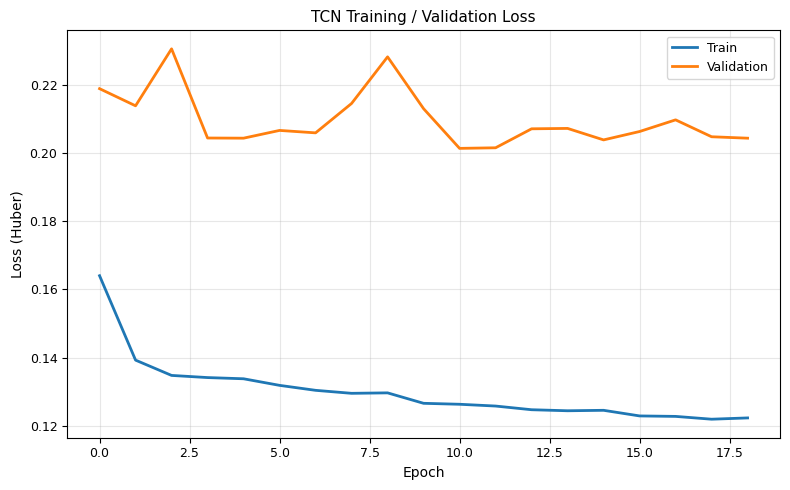

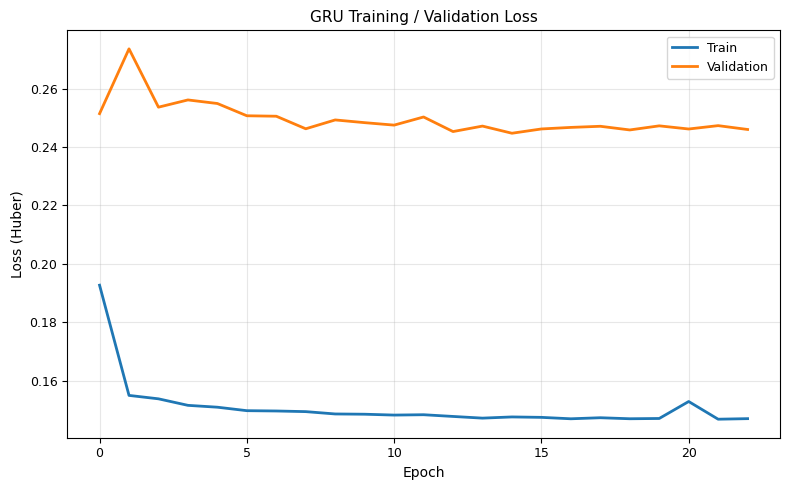

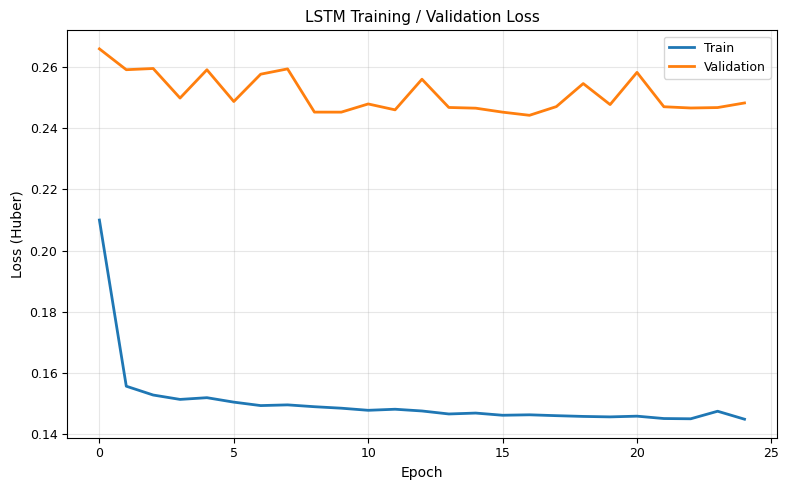


================ MODEL COMPARISON TABLE ================
(ranked by val_loss, ascending — pre-specified criterion)


,model,val_loss,rollout_rmse,sensitivity_score,conf_coverage,conf_width,mc_coverage,mc_width,best_uncertainty,final_score
0,TCN,0.201293,0.013828,0.077300,0.909091,0.047241,0.911187,0.047322,conformal,0.995879
1,LSTM,0.244257,0.014480,0.070049,0.904637,0.047314,0.906733,0.046941,conformal,0.594983
2,GRU,0.244710,0.014867,0.052533,0.910925,0.046989,0.904113,0.046403,monte_carlo_resid,0.196699



================ DOWNLOAD FILES ================


Button(button_style='success', description='Download TCN Loss PNG', icon='download', layout=Layout(width='250p…

Button(button_style='success', description='Download GRU Loss PNG', icon='download', layout=Layout(width='250p…

Button(button_style='success', description='Download LSTM Loss PNG', icon='download', layout=Layout(width='250…

Button(button_style='success', description='Download Comparison Table CSV', icon='download', layout=Layout(wid…


Best model selected: TCN   (criterion: val_loss)
Selected uncertainty method: conformal
Validation loss: 0.2013 vs LSTM 0.2443 -> 21.3% better
Interpretation:
- TCN is selected on one-step validation loss, the pre-specified
  criterion, where the margin is large and stable across runs.
- final_score is reported descriptively and does not drive this choice.
- Phase 3 and Phase 4 reuse this trained model without retraining.


In [ ]:
# Select the architecture using one-step validation loss.
# The composite score is descriptive and does not select the model.
# Paired rollout tests use shared windows; lack of significance is not equivalence.

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import ipywidgets as widgets
from scipy import stats as _st2
from IPython.display import display
try:
    from google.colab import files  # Colab only; harmless elsewhere
except Exception:
    files = None

SELECTION_CRITERION = "val_loss"   # pre-specified; see the note above
SEL_HORIZON     = 20               # rollout horizon for the paired test
SEL_MAX_WINDOWS = 150              # windows sampled for the paired test

rows = []


def uncertainty_method_score(cov, width, target=0.90):
    cov_term = max(0.0, 1.0 - abs(cov - target) / target)
    width_term = 1.0 / (1.0 + max(0.0, width))
    return 0.7 * cov_term + 0.3 * width_term


for name, res in exp_results.items():
    rmse = float(res["rollout_rmse"])
    sens = float(res["sensitivity_score"])

    uc = uncertainty_results[name]["conformal"]
    um = uncertainty_results[name]["monte_carlo_resid"]

    s_conf = uncertainty_method_score(uc["coverage"], uc["avg_width"], target=0.90)
    s_mc = uncertainty_method_score(um["coverage"], um["avg_width"], target=0.90)

    best_method = "conformal" if s_conf >= s_mc else "monte_carlo_resid"
    best_u_score = max(s_conf, s_mc)

    rows.append({
        "model": name,
        "rollout_rmse": rmse,
        "sensitivity_score": sens,
        "conf_coverage": uc["coverage"],
        "conf_width": uc["avg_width"],
        "mc_coverage": um["coverage"],
        "mc_width": um["avg_width"],
        "best_uncertainty": best_method,
        "best_u_score": best_u_score,
        "val_loss": float(experiment_models[name]["val_loss"]),
    })

score_df = pd.DataFrame(rows)

rmse_min, rmse_max = score_df["rollout_rmse"].min(), score_df["rollout_rmse"].max()
sens_min, sens_max = score_df["sensitivity_score"].min(), score_df["sensitivity_score"].max()
score_df["rmse_score"] = (
    (rmse_max - score_df["rollout_rmse"]) / (rmse_max - rmse_min)
    if rmse_max > rmse_min else 1.0
)
score_df["sens_score_norm"] = (
    (score_df["sensitivity_score"] - sens_min) / (sens_max - sens_min)
    if sens_max > sens_min else 1.0
)
score_df["final_score"] = (
    0.50 * score_df["rmse_score"] +
    0.30 * score_df["sens_score_norm"] +
    0.20 * score_df["best_u_score"]
)

score_df = score_df.sort_values(SELECTION_CRITERION, ascending=True).reset_index(drop=True)
model_comparison_df = score_df.copy()

def _batched_rollout_sq_errors(mdl, feat_names, horizon=SEL_HORIZON,
                               max_windows=SEL_MAX_WINDOWS):
    """Per-window squared errors over `horizon` steps. Returns (W, horizon)."""
    by_seg_s = {int(s): g.reset_index(drop=True) for s, g in df_test.groupby("segment")}
    by_seg_r = {int(s): g.reset_index(drop=True) for s, g in df_test_raw.groupby("segment")}
    has_c = "Cushion_in" in feat_names
    c_idx = feat_names.index("Cushion_in") if has_c else None

    hists, futs, trues, prevs = [], [], [], []
    for seg_id, seg_s in by_seg_s.items():
        if seg_id not in by_seg_r:
            continue
        seg_r = by_seg_r[seg_id]
        n = len(seg_s)
        if n <= SEQ_LEN + horizon:
            continue
        for t0 in list(range(SEQ_LEN, n - horizon))[:25]:
            hists.append(seg_s.loc[t0 - SEQ_LEN:t0 - 1, feat_names].values.astype(np.float32))
            futs.append(seg_s.loc[t0:t0 + horizon - 1, feat_names].values.astype(np.float32))
            trues.append(seg_r.loc[t0:t0 + horizon - 1, TARGET_COL].values.astype(np.float64))
            prevs.append(float(seg_r.loc[t0 - 1, TARGET_COL]))
            if len(hists) >= max_windows:
                break
        if len(hists) >= max_windows:
            break

    hist = torch.tensor(np.stack(hists), dtype=torch.float32, device=device)
    fut = np.stack(futs)
    y = np.stack(trues)
    prev = np.array(prevs, dtype=np.float64)
    W = hist.shape[0]
    err2 = np.empty((W, horizon), dtype=np.float64)

    mdl.eval()
    with torch.no_grad():
        for h in range(horizon):
            d_s = mdl(hist).detach().cpu().numpy().reshape(W, -1)[:, 0]
            pred = prev + delta_scaled_to_real_vec(d_s).astype(np.float64)
            err2[:, h] = (pred - y[:, h]) ** 2

            nxt = fut[:, h, :].copy()
            if has_c:
                nxt[:, c_idx] = cushion_real_to_scaled(pred).astype(np.float32)
            hist[:, :-1, :] = hist[:, 1:, :].clone()
            hist[:, -1, :] = torch.tensor(nxt, dtype=torch.float32, device=device)
            prev = pred
    return err2


print(f"[selection] paired rollout test — {SEL_MAX_WINDOWS} windows x "
      f"{SEL_HORIZON} steps, identical windows for all models")
_sq = {}
for _m in score_df["model"]:
    _sq[_m] = _batched_rollout_sq_errors(
        experiment_models[_m]["model"], experiment_models[_m]["feature_names"])
    print(f"  {_m}: rollout RMSE = {np.sqrt(_sq[_m].mean()):.5f}")

_names = list(score_df["model"])
_pair_rows = []
for _i in range(len(_names)):
    for _j in range(_i + 1, len(_names)):
        a, b = _names[_i], _names[_j]
        _w = min(len(_sq[a]), len(_sq[b]))
        ea, eb = _sq[a][:_w].mean(axis=1), _sq[b][:_w].mean(axis=1)
        _t, _p = _st2.ttest_rel(ea, eb)
        _rmse_a, _rmse_b = np.sqrt(ea.mean()), np.sqrt(eb.mean())
        _pair_rows.append({
            "comparison": f"{a} vs {b}",
            f"RMSE_1": round(float(_rmse_a), 5),
            f"RMSE_2": round(float(_rmse_b), 5),
            "rel_diff_%": round(float((_rmse_b - _rmse_a) / _rmse_a * 100), 2),
            "t_stat": round(float(_t), 3),
            "p_value": float(_p),
            "significant_0.05": bool(_p < 0.05),
        })

architecture_paired_df = pd.DataFrame(_pair_rows)
print("\n===== PAIRED ROLLOUT COMPARISON BETWEEN ARCHITECTURES =====")
display(architecture_paired_df)
architecture_paired_df.to_csv("architecture_paired_rollout.csv", index=False)

_n_sig = int(architecture_paired_df["significant_0.05"].sum())
if _n_sig == 0:
    print(">>> No pair differs significantly on closed-loop rollout (all p > 0.05).")
    print("    The three architectures are statistically INDISTINGUISHABLE at this")
    print("    horizon. Any claim of rollout superiority would be unsupported.")
else:
    print(f">>> {_n_sig} of {len(architecture_paired_df)} pairs differ significantly.")
    print("    Pairwise results and p-values are reported individually.")

_rmse_spread = float((rmse_max - rmse_min) / rmse_min * 100)
_score_spread = float(score_df["final_score"].max() - score_df["final_score"].min())
print(f"\n[composite diagnostic] rollout RMSE spread across models: {_rmse_spread:.2f}%")
print(f"[composite diagnostic] final_score spread:               {_score_spread:.3f}")
print("  min-max normalisation over three models converts the former into the")
print("  latter. final_score is reported as a descriptive summary only; it does")
print("  not select the model.")

output_dir = "exp_cell_6_outputs"
os.makedirs(output_dir, exist_ok=True)


def make_download_button(file_path, button_label):
    button = widgets.Button(
        description=button_label,
        button_style="success",
        icon="download",
        layout=widgets.Layout(width="250px")
    )

    def on_click(b):
        if files:
            files.download(file_path)

    button.on_click(on_click)
    return button


model_order = ["TCN", "GRU", "LSTM"]
download_buttons = []

for model_name in model_order:
    hist_m = experiment_models[model_name]

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(hist_m["train_loss_hist"], label="Train", linewidth=2)
    ax.plot(hist_m["val_loss_hist"], label="Validation", linewidth=2)
    ax.set_title(f"{model_name} Training / Validation Loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss (Huber)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")
    plt.tight_layout()

    png_path = os.path.join(output_dir, f"{model_name}_loss.png")
    fig.savefig(png_path, dpi=600, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    download_buttons.append(
        make_download_button(png_path, f"Download {model_name} Loss PNG")
    )

print("\n================ MODEL COMPARISON TABLE ================")
print(f"(ranked by {SELECTION_CRITERION}, ascending — pre-specified criterion)")

table_to_export = score_df[[
    "model", "val_loss", "rollout_rmse", "sensitivity_score",
    "conf_coverage", "conf_width", "mc_coverage", "mc_width",
    "best_uncertainty", "final_score"
]]

display(table_to_export)

csv_path = os.path.join(output_dir, "model_comparison_table.csv")
table_to_export.to_csv(csv_path, index=False)

table_button = make_download_button(csv_path, "Download Comparison Table CSV")

print("\n================ DOWNLOAD FILES ================")
for btn in download_buttons:
    display(btn)

display(table_button)

winner = score_df.iloc[0]
best_model_name = str(winner["model"])
best_uncertainty_method = str(winner["best_uncertainty"])
best_model_info = experiment_models[best_model_name]

_vl = score_df.set_index("model")["val_loss"]
_runner = score_df.iloc[1]["model"]
_margin = float((_vl[_runner] - _vl[best_model_name]) / _vl[best_model_name] * 100)

print(f"\nBest model selected: {best_model_name}   (criterion: {SELECTION_CRITERION})")
print(f"Selected uncertainty method: {best_uncertainty_method}")
print(f"Validation loss: {_vl[best_model_name]:.4f} vs {_runner} {_vl[_runner]:.4f} "
      f"-> {_margin:.1f}% better")
print("Interpretation:")
print(f"- {best_model_name} is selected on one-step validation loss, the pre-specified")
print("  criterion, where the margin is large and stable across runs.")
if _n_sig == 0:
    print("- On closed-loop rollout the three architectures are statistically")
    print("  indistinguishable (all paired p > 0.05); no rollout superiority is claimed.")
print("- final_score is reported descriptively and does not drive this choice.")
print("- Phase 3 and Phase 4 reuse this trained model without retraining.")
print("=======================================================")

model_selection_summary = {
    "criterion": SELECTION_CRITERION,
    "selected": best_model_name,
    "uncertainty_method": best_uncertainty_method,
    "val_loss": {k: float(v) for k, v in _vl.items()},
    "val_loss_margin_pct": _margin,
    "rollout_rmse": {r["model"]: float(r["rollout_rmse"]) for _, r in score_df.iterrows()},
    "rollout_rmse_spread_pct": _rmse_spread,
    "final_score_spread": _score_spread,
    "paired_rollout_tests": architecture_paired_df.to_dict(orient="records"),
    "n_significant_pairs": _n_sig,
}

## Baselines, input dependence and rollout error

Compare reference predictors, inspect input importance and measure RMSE by horizon. Interpret paired tests with care because rollout windows overlap.


In [ ]:
# Compare persistence, a moving average of recent increments and ARIMA(2,0,1).
# ARIMA is refitted to the history at each rollout origin.
# The neural rollout uses recorded future exogenous inputs.
# The reported loss comparison is a paired t-test, not a dependence-adjusted
# Diebold-Mariano test; overlapping windows limit inference from its p-values.

import numpy as np

try:
    from statsmodels.tsa.arima.model import ARIMA
    _HAS_ARIMA = True
except Exception:
    _HAS_ARIMA = False
    print("statsmodels not available -> ARIMA baseline skipped (persistence & moving-average still run).")

BASELINE_HORIZON = 20        # same horizon used for the neural rollout RMSE
BASELINE_MAX_WINDOWS = 300   # cap for runtime; matches the neural evaluation
MA_WINDOW = 5                # window length for the moving-average baseline

def _rollout_baseline(kind):
    """Closed-loop rollout of a baseline over test segments.
    Returns (rmse, per_step_squared_errors) aligned by (window, step)."""
    by_seg_raw = {int(s): g.reset_index(drop=True) for s, g in df_test_raw.groupby("segment")}
    all_err2, sampled = [], 0
    for seg_id, seg_r in by_seg_raw.items():
        n = len(seg_r)
        if n <= SEQ_LEN + BASELINE_HORIZON:
            continue
        starts = list(range(SEQ_LEN, n - BASELINE_HORIZON))[:25]
        for t0 in starts:
            hist = list(seg_r.loc[t0 - SEQ_LEN:t0 - 1, TARGET_COL].astype(float).values)
            errs = []
            if kind == "arima" and _HAS_ARIMA:
                try:
                    fit = ARIMA(hist, order=(2, 0, 1)).fit()
                    fc = fit.forecast(steps=BASELINE_HORIZON)
                except Exception:
                    fc = None
            for h in range(BASELINE_HORIZON):
                if kind == "persistence":
                    pred = hist[-1]
                elif kind == "moving_average":
                    pred = float(np.mean(hist[-MA_WINDOW:]))
                elif kind == "arima":
                    pred = float(fc[h]) if (_HAS_ARIMA and fc is not None) else hist[-1]
                y_true = float(seg_r.loc[t0 + h, TARGET_COL])
                errs.append((pred - y_true) ** 2)
                hist.append(pred)          # closed-loop: feed own prediction forward
            all_err2.append(errs)
            sampled += 1
            if sampled >= BASELINE_MAX_WINDOWS:
                break
        if sampled >= BASELINE_MAX_WINDOWS:
            break
    arr = np.array(all_err2, dtype=float)          # (windows, horizon)
    rmse = float(np.sqrt(arr.mean())) if arr.size else float("nan")
    return rmse, arr

baseline_results = {}
for _k in ["persistence", "moving_average"] + (["arima"] if _HAS_ARIMA else []):
    _rmse, _e2 = _rollout_baseline(_k)
    baseline_results[_k] = {"rollout_rmse": _rmse, "sq_errors": _e2}
    print(f"baseline {_k:14s}: rollout RMSE = {_rmse:.5f}")

from scipy import stats as _st

def _winner_sq_errors():
    """Per-window squared errors of the best neural model, same task."""
    best = model_comparison_df.iloc[0]["model"]
    mdl = experiment_models[best]["model"]
    names = experiment_models[best]["feature_names"]
    by_seg_scaled = {int(s): g.reset_index(drop=True) for s, g in df_test.groupby("segment")}
    by_seg_raw = {int(s): g.reset_index(drop=True) for s, g in df_test_raw.groupby("segment")}
    has_c = "Cushion_in" in names
    out, sampled = [], 0
    mdl.eval()
    for seg_id, seg_s in by_seg_scaled.items():
        if seg_id not in by_seg_raw:
            continue
        seg_r = by_seg_raw[seg_id]; n = len(seg_s)
        if n <= SEQ_LEN + BASELINE_HORIZON:
            continue
        for t0 in list(range(SEQ_LEN, n - BASELINE_HORIZON))[:25]:
            hist = seg_s.loc[t0 - SEQ_LEN:t0 - 1, names].values.astype(np.float32).copy()
            prev = float(seg_r.loc[t0 - 1, TARGET_COL]); errs = []
            for h in range(BASELINE_HORIZON):
                with torch.no_grad():
                    d_s = float(mdl(torch.tensor(hist[None], dtype=torch.float32, device=device)
                                    ).cpu().numpy().reshape(-1)[0])
                pred = prev + float(delta_scaled_to_real_vec([d_s])[0])
                errs.append((pred - float(seg_r.loc[t0 + h, TARGET_COL])) ** 2)
                nxt = seg_s.loc[t0 + h, names].values.astype(np.float32).copy()
                if has_c:
                    nxt[names.index("Cushion_in")] = float(cushion_real_to_scaled([pred])[0])
                hist[:-1] = hist[1:]; hist[-1] = nxt; prev = pred
            out.append(errs); sampled += 1
            if sampled >= BASELINE_MAX_WINDOWS:
                break
        if sampled >= BASELINE_MAX_WINDOWS:
            break
    return np.array(out, dtype=float)

_win_e2 = _winner_sq_errors()
_best_name = model_comparison_df.iloc[0]["model"]
dm_rows = []
for _k, _r in baseline_results.items():
    m = min(len(_win_e2), len(_r["sq_errors"]))
    diff = _r["sq_errors"][:m].mean(axis=1) - _win_e2[:m].mean(axis=1)  # baseline - model
    t, p = _st.ttest_rel(_r["sq_errors"][:m].mean(axis=1), _win_e2[:m].mean(axis=1))
    dm_rows.append({"baseline": _k, "baseline_rmse": _r["rollout_rmse"],
                    f"{_best_name}_better_by": float(diff.mean()),
                    "t_stat": float(t), "p_value": float(p),
                    "significant_0.05": bool(p < 0.05)})

import pandas as pd
baseline_comparison_df = pd.DataFrame(dm_rows)
print(f"\nDiebold-Mariano style paired test — is {_best_name} significantly better?")
display(baseline_comparison_df)
baseline_comparison_df.to_csv("baseline_comparison.csv", index=False)


baseline persistence   : rollout RMSE = 0.02258
baseline moving_average: rollout RMSE = 0.01793


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.12/dist-packages/statsmodels

baseline arima         : rollout RMSE = 0.01734

Diebold-Mariano style paired test — is TCN significantly better?


,baseline,baseline_rmse,TCN_better_by,t_stat,p_value,significant_0.05
0,persistence,0.022576,0.000318,8.225397,8.658248e-11,True
1,moving_average,0.017927,0.000130,8.995302,5.991526e-12,True
2,arima,0.017339,0.000109,10.000306,2.011119e-13,True


Permutation importance (TCN, validation set) — higher = more relied upon:


,feature,importance_%_loss_increase
7,Cushion_in,181.479311
6,Dosing_Volume_ActValue,1.265119
1,Switch_Over_Pressure,0.563924
2,Injection_Time,0.516458
0,Maximum_Injection_Pressure,0.435556
5,SwitchOver_volume_ActValue,-0.078156
4,Back_pressure_ActValue,-0.122933
3,Dosing_Time,-1.824399


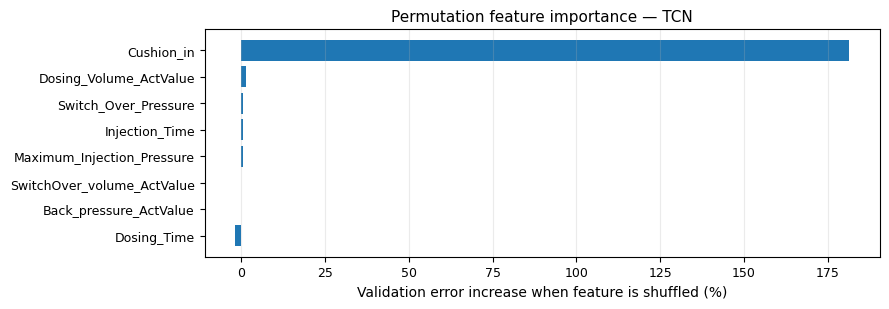

  0%|          | 0/100 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/shap/explainers/_kernel.py:765: UserWarning: Linear regression equation is singular, a least squares solutions is used instead.
To avoid this situation and get a regular matrix do one of the following:
1) turn up the number of samples,
2) turn up the L1 regularization with num_features(N) where N is less than the number of samples,
3) group features together to reduce the number of inputs that need to be explained.
  warnings.warn(



SHAP mean |value| per feature (validation sample):


,feature,mean_abs_shap
7,Cushion_in,0.010700
1,Switch_Over_Pressure,0.003843
0,Maximum_Injection_Pressure,0.003308
2,Injection_Time,0.000780
3,Dosing_Time,0.000744
6,Dosing_Volume_ActValue,0.000573
5,SwitchOver_volume_ActValue,0.000485
4,Back_pressure_ActValue,0.000471


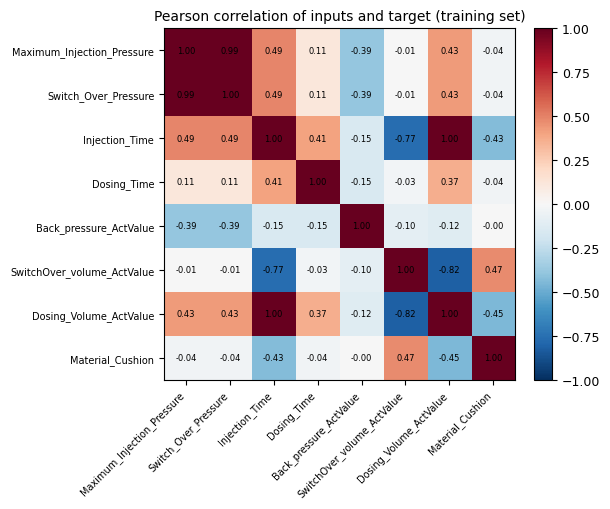

In [ ]:
# Compute one permutation per input, optional SHAP values and training correlations.
# A single permutation gives no uncertainty estimate. Correlated inputs can mask
# one another, and shuffling can create combinations absent from training.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_best = model_comparison_df.iloc[0]["model"]
_mdl = experiment_models[_best]["model"]
_names = experiment_models[_best]["feature_names"]
_mdl.eval()

def _val_loss_with(Xarr):
    with torch.no_grad():
        pr = []
        for i in range(0, len(Xarr), 512):
            xb = torch.tensor(Xarr[i:i+512], dtype=torch.float32, device=device)
            pr.append(_mdl(xb).cpu().numpy().reshape(-1))
        pred = np.concatenate(pr)
    y = Y_val.reshape(-1)[:len(pred)]
    return float(np.mean((pred - y) ** 2))

_base_loss = _val_loss_with(X_val)
_rng = np.random.default_rng(RANDOM_SEED if "RANDOM_SEED" in globals() else 42)

perm_rows = []
for _fi, _fname in enumerate(_names):
    Xp = X_val.copy()
    perm = _rng.permutation(len(Xp))
    Xp[:, :, _fi] = Xp[perm, :, _fi]
    _loss = _val_loss_with(Xp)
    perm_rows.append({"feature": _fname,
                      "importance_%_loss_increase": 100.0 * (_loss - _base_loss) / _base_loss})
perm_df = pd.DataFrame(perm_rows).sort_values("importance_%_loss_increase", ascending=False)
print(f"Permutation importance ({_best}, validation set) — higher = more relied upon:")
display(perm_df)
perm_df.to_csv("feature_importance_permutation.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(perm_df["feature"][::-1], perm_df["importance_%_loss_increase"][::-1], color="#1F77B4")
ax.set_xlabel("Validation error increase when feature is shuffled (%)")
ax.set_title(f"Permutation feature importance — {_best}")
ax.grid(alpha=0.25, axis="x")
plt.tight_layout(); plt.savefig("feature_importance_permutation.png", dpi=600, bbox_inches="tight"); plt.show()

try:
    import shap
    _bg = X_val[_rng.choice(len(X_val), size=min(50, len(X_val)), replace=False)]
    _sample = X_val[_rng.choice(len(X_val), size=min(100, len(X_val)), replace=False)]

    def _f(flat):
        arr = flat.reshape(-1, X_val.shape[1], X_val.shape[2]).astype(np.float32)
        with torch.no_grad():
            return _mdl(torch.tensor(arr, dtype=torch.float32, device=device)).cpu().numpy().reshape(-1)

    expl = shap.KernelExplainer(_f, _bg.reshape(len(_bg), -1))
    sv = expl.shap_values(_sample.reshape(len(_sample), -1), nsamples=100)
    sv = np.array(sv).reshape(len(_sample), X_val.shape[1], X_val.shape[2])
    shap_per_feature = np.abs(sv).mean(axis=(0, 1))   # mean |SHAP| per feature
    shap_df = pd.DataFrame({"feature": _names, "mean_abs_shap": shap_per_feature}) \
                .sort_values("mean_abs_shap", ascending=False)
    print("\nSHAP mean |value| per feature (validation sample):")
    display(shap_df)
    shap_df.to_csv("feature_importance_shap.csv", index=False)
except Exception as _e:
    print(f"\nSHAP not computed ({_e}). Permutation importance above is the primary ranking.")

_corr_cols = list(RECIPE_FEATURES) + [TARGET_COL]
_corr = df_train_raw[_corr_cols].astype(float).corr()
fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(_corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(_corr_cols))); ax.set_xticklabels(_corr_cols, rotation=45, ha="right", fontsize=7)
ax.set_yticks(range(len(_corr_cols))); ax.set_yticklabels(_corr_cols, fontsize=7)
for a in range(len(_corr_cols)):
    for b in range(len(_corr_cols)):
        ax.text(b, a, f"{_corr.values[a,b]:.2f}", ha="center", va="center",
                fontsize=6, color="black")
ax.set_title("Pearson correlation of inputs and target (training set)", fontsize=10)
fig.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout(); plt.savefig("feature_correlation_heatmap.png", dpi=600, bbox_inches="tight"); plt.show()


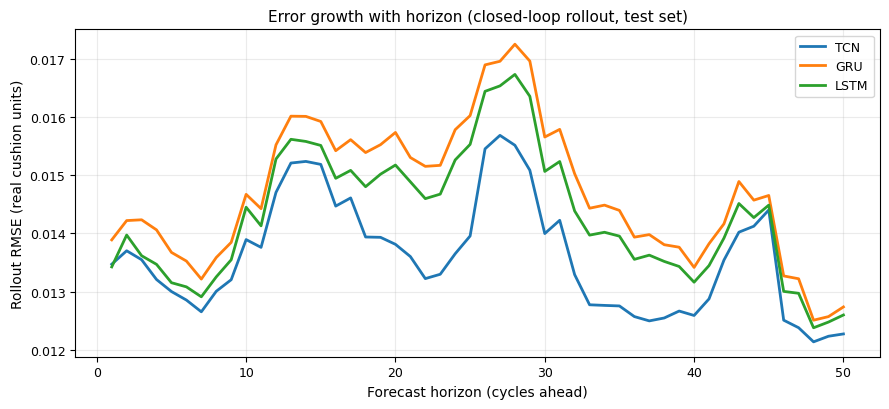

Rollout RMSE at selected horizons (real units):


,TCN,GRU,LSTM
horizon,,,
1,0.01347,0.01389,0.01342
10,0.01389,0.01467,0.01445
20,0.01381,0.01574,0.01518
30,0.01400,0.01566,0.01507
50,0.01227,0.01274,0.01260


In [ ]:
# Measure test RMSE at each forecast horizon for the neural models.
# Cushion predictions are fed back; other inputs follow the recorded trajectory.
# This is a deterministic rollout diagnostic, not the conditional Monte Carlo audit.

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

HORIZON_MAX = 50
HORIZON_MAX_WINDOWS = 200

def _rmse_by_horizon(model, feature_names, hmax=HORIZON_MAX):
    by_seg_scaled = {int(s): g.reset_index(drop=True) for s, g in df_test.groupby("segment")}
    by_seg_raw = {int(s): g.reset_index(drop=True) for s, g in df_test_raw.groupby("segment")}
    has_c = "Cushion_in" in feature_names
    sq = [[] for _ in range(hmax)]      # squared errors per horizon step
    sampled = 0
    model.eval()
    for seg_id, seg_s in by_seg_scaled.items():
        if seg_id not in by_seg_raw:
            continue
        seg_r = by_seg_raw[seg_id]; n = len(seg_s)
        if n <= SEQ_LEN + hmax:
            continue
        for t0 in list(range(SEQ_LEN, n - hmax))[:20]:
            hist = seg_s.loc[t0 - SEQ_LEN:t0 - 1, feature_names].values.astype(np.float32).copy()
            prev = float(seg_r.loc[t0 - 1, TARGET_COL])
            for h in range(hmax):
                with torch.no_grad():
                    d_s = float(model(torch.tensor(hist[None], dtype=torch.float32, device=device)
                                      ).cpu().numpy().reshape(-1)[0])
                pred = prev + float(delta_scaled_to_real_vec([d_s])[0])
                sq[h].append((pred - float(seg_r.loc[t0 + h, TARGET_COL])) ** 2)
                nxt = seg_s.loc[t0 + h, feature_names].values.astype(np.float32).copy()
                if has_c:
                    nxt[feature_names.index("Cushion_in")] = float(cushion_real_to_scaled([pred])[0])
                hist[:-1] = hist[1:]; hist[-1] = nxt; prev = pred
            sampled += 1
            if sampled >= HORIZON_MAX_WINDOWS:
                break
        if sampled >= HORIZON_MAX_WINDOWS:
            break
    return np.array([np.sqrt(np.mean(s)) if s else np.nan for s in sq])

fig, ax = plt.subplots(figsize=(9, 4.2))
horizon_curves = {}
for _name in experiment_models:
    _curve = _rmse_by_horizon(experiment_models[_name]["model"],
                              experiment_models[_name]["feature_names"])
    horizon_curves[_name] = _curve
    ax.plot(np.arange(1, HORIZON_MAX + 1), _curve, lw=2, label=_name)
ax.set_xlabel("Forecast horizon (cycles ahead)")
ax.set_ylabel("Rollout RMSE (real cushion units)")
ax.set_title("Error growth with horizon (closed-loop rollout, test set)")
ax.legend(); ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig("rmse_vs_horizon.png", dpi=600, bbox_inches="tight"); plt.show()

horizon_df = pd.DataFrame(horizon_curves, index=np.arange(1, HORIZON_MAX + 1))
horizon_df.index.name = "horizon"
horizon_df.to_csv("rmse_vs_horizon.csv")
print("Rollout RMSE at selected horizons (real units):")
display(horizon_df.loc[[1, 10, 20, 30, 50]].round(5))


### Hyperparameter sensitivity

Vary one setting at a time around the fixed configuration. The sweep does not establish an optimum; depth 1 and 2 build the same channel stack.


  sequence_length=10: val_loss=0.20057
  sequence_length=25: val_loss=0.20409
  sequence_length=50: val_loss=0.20797
  sequence_length=100: val_loss=0.21027
  hidden_size=32: val_loss=0.20298
  hidden_size=64: val_loss=0.20346
  hidden_size=128: val_loss=0.20187
  hidden_size=256: val_loss=0.20325
  depth_layers=1: val_loss=0.20472
  depth_layers=2: val_loss=0.19789
  depth_layers=3: val_loss=0.20971

Hyperparameter sensitivity (validation loss; lower is better):


,hyperparameter,value,val_loss,seconds
0,sequence_length,10,0.200567,24.6
1,sequence_length,25,0.204085,22.5
2,sequence_length,50,0.207973,18.4
3,sequence_length,100,0.210272,20.6
4,hidden_size,32,0.202981,21.8
5,hidden_size,64,0.203464,20.1
6,hidden_size,128,0.201870,18.8
7,hidden_size,256,0.203249,23.7
8,depth_layers,1,0.204724,19.2
9,depth_layers,2,0.197886,31.5


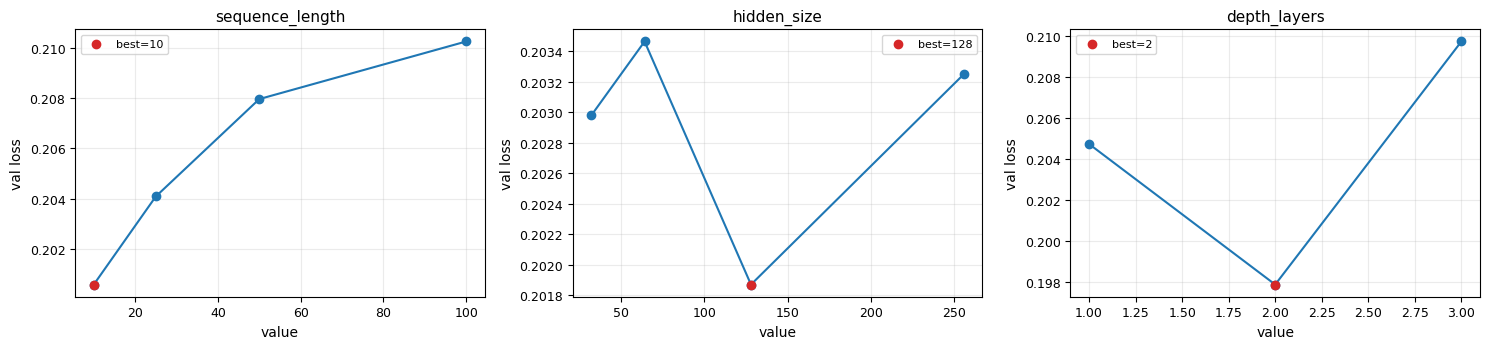

In [ ]:
# Vary sequence length, width and depth one at a time.
# This is a sensitivity sweep, not evidence that the fixed configuration is optimal.
# The channel-stack rule uses max(2, depth), so depth 1 and 2 build the same stack.
# The loop is not reseeded between grid points.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

SENSITIVITY_QUICK = False   # True -> smaller grid for a quick pass

SEQ_GRID    = [10, 25, 50, 100] if not SENSITIVITY_QUICK else [25, 50]
HIDDEN_GRID = [32, 64, 128, 256] if not SENSITIVITY_QUICK else [64, 128]
LAYER_GRID  = [1, 2, 3] if not SENSITIVITY_QUICK else [2]

def _build_and_score(seq_len, hidden, layers):
    """Rebuild sequences for the given seq_len, train a TCN, return val loss."""
    Xtr, Ytr, _, _ = build_sequences_multistep(df_train, FEATURES, TARGET_SCALED_COL, seq_len, H)
    Xva, Yva, _, _ = build_sequences_multistep(df_val,   FEATURES, TARGET_SCALED_COL, seq_len, H)
    tr, va = make_loaders(Xtr, Ytr, Xva, Yva, batch_size=128)
    ch = tuple([hidden] * max(2, layers))    # TCN channel stack depth ~ layers
    m = TCNOneStep(input_dim=Xtr.shape[-1], channels=ch, kernel=3, dropout=DROPOUT)
    m, vloss, _, _ = train_model(m, tr, va)
    return float(vloss)

records = []

for L in SEQ_GRID:
    t0 = time.time()
    vl = _build_and_score(L, HIDDEN_SIZE, NUM_LAYERS)
    records.append({"hyperparameter": "sequence_length", "value": L,
                    "val_loss": vl, "seconds": round(time.time() - t0, 1)})
    print(f"  sequence_length={L}: val_loss={vl:.5f}")

for Hd in HIDDEN_GRID:
    t0 = time.time()
    vl = _build_and_score(SEQ_LEN, Hd, NUM_LAYERS)
    records.append({"hyperparameter": "hidden_size", "value": Hd,
                    "val_loss": vl, "seconds": round(time.time() - t0, 1)})
    print(f"  hidden_size={Hd}: val_loss={vl:.5f}")

for Ly in LAYER_GRID:
    t0 = time.time()
    vl = _build_and_score(SEQ_LEN, HIDDEN_SIZE, Ly)
    records.append({"hyperparameter": "depth_layers", "value": Ly,
                    "val_loss": vl, "seconds": round(time.time() - t0, 1)})
    print(f"  depth_layers={Ly}: val_loss={vl:.5f}")

sensitivity_df = pd.DataFrame(records)
print("\nHyperparameter sensitivity (validation loss; lower is better):")
display(sensitivity_df)
sensitivity_df.to_csv("hyperparameter_sensitivity.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, hp in zip(axes, ["sequence_length", "hidden_size", "depth_layers"]):
    sub = sensitivity_df[sensitivity_df["hyperparameter"] == hp]
    ax.plot(sub["value"], sub["val_loss"], "o-", color="#1F77B4")
    ax.set_title(hp); ax.set_xlabel("value"); ax.set_ylabel("val loss"); ax.grid(alpha=0.25)
    best = sub.loc[sub["val_loss"].idxmin()]
    ax.scatter([best["value"]], [best["val_loss"]], color="#D62728", zorder=5,
               label=f"best={best['value']}")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("hyperparameter_sensitivity.png", dpi=600, bbox_inches="tight"); plt.show()


### Seed replication

Compare architecture differences with variation across three training seeds. Failure to distinguish rollout errors is not evidence of equivalence.


  seed=  123 TCN    val_loss=0.19943  rollout_rmse=0.01411  (12s)
  seed=  123 GRU    val_loss=0.24594  rollout_rmse=0.01424  (21s)
  seed=  123 LSTM   val_loss=0.24379  rollout_rmse=0.01396  (23s)
  seed= 2026 TCN    val_loss=0.20275  rollout_rmse=0.01417  (11s)
  seed= 2026 GRU    val_loss=0.24542  rollout_rmse=0.01402  (10s)
  seed= 2026 LSTM   val_loss=0.24546  rollout_rmse=0.01437  (19s)
  seed=    7 TCN    val_loss=0.20147  rollout_rmse=0.01384  (14s)
  seed=    7 GRU    val_loss=0.24703  rollout_rmse=0.01500  (10s)
  seed=    7 LSTM   val_loss=0.24650  rollout_rmse=0.01421  (18s)

SEED REPLICATION — 3 seeds x 3 architectures


,architecture,val_loss_mean,val_loss_sd,rollout_rmse_mean,rollout_rmse_sd,n_seeds
0,TCN,0.201215,0.001675,0.01404,0.000177,3
1,GRU,0.246133,0.000821,0.01442,0.000512,3
2,LSTM,0.245251,0.001363,0.01418,0.000210,3



validation-loss gap TCN vs LSTM : 0.04404
pooled seed-to-seed sd                 : 0.00133
gap / seed sd                          : 33.0x   -> selection ROBUST under seed noise
closed-loop RMSE spread / seed sd      : 1.1x   -> architectures INDISTINGUISHABLE in rollout


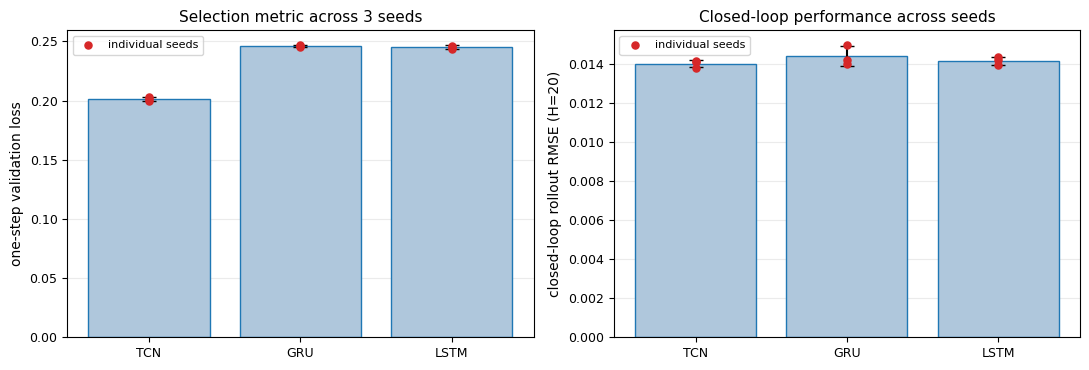


total time for 9 trainings: 2.3 min
[seed replication] RNG state restored — downstream results unaffected


In [ ]:
# Retrain the architectures under three seeds and summarise seed variation.
# Keep the reported checkpoint separate and restore the saved RNG states afterward.

import time as _time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

SEED_LIST = [123, 2026, 7]          # independent training seeds
SEED_ARCHS = ["TCN", "GRU", "LSTM"]

_np_state_before = np.random.get_state()
_torch_state_before = torch.get_rng_state()
_cuda_state_before = (torch.cuda.get_rng_state_all()
                      if torch.cuda.is_available() else None)


def _fresh_model(arch, in_dim):
    if arch == "TCN":
        return TCNOneStep(input_dim=in_dim,
                          channels=(HIDDEN_SIZE, HIDDEN_SIZE),
                          kernel=3, dropout=DROPOUT)
    if arch == "GRU":
        return GRUOneStep(input_dim=in_dim, hidden_dim=HIDDEN_SIZE,
                          num_layers=NUM_LAYERS, dropout=DROPOUT)
    return LSTMOneStep(input_dim=in_dim, hidden_dim=HIDDEN_SIZE,
                       num_layers=NUM_LAYERS, dropout=DROPOUT)


_rows = []
_t_all = _time.time()

for _sd in SEED_LIST:
    for _arch in SEED_ARCHS:
        np.random.seed(_sd)
        torch.manual_seed(_sd)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(_sd)

        _tr, _va = make_loaders(Xtr_full, Y_train, Xva_full, Y_val, batch_size=128)
        _t0 = _time.time()
        _m = _fresh_model(_arch, Xtr_full.shape[-1])
        _m, _vl, _, _ = train_model(_m, _tr, _va)
        _rr = rollout_rmse_on_test(_m, [FEATURES[i] for i in mask_full],
                                   horizon=20, max_windows=300)
        _rows.append({
            "architecture": _arch,
            "seed": _sd,
            "val_loss": float(_vl),
            "rollout_rmse": float(_rr),
            "seconds": round(_time.time() - _t0, 1),
        })
        print(f"  seed={_sd:5d} {_arch:5s}  val_loss={_vl:.5f}  "
              f"rollout_rmse={_rr:.5f}  ({_rows[-1]['seconds']:.0f}s)")

        del _m
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

seed_runs_df = pd.DataFrame(_rows)

seed_replication_df = (
    seed_runs_df.groupby("architecture")
    .agg(val_loss_mean=("val_loss", "mean"),
         val_loss_sd=("val_loss", "std"),
         rollout_rmse_mean=("rollout_rmse", "mean"),
         rollout_rmse_sd=("rollout_rmse", "std"),
         n_seeds=("seed", "count"))
    .reindex(SEED_ARCHS)
    .round(6)
    .reset_index()
)

print("\n" + "=" * 70)
print(f"SEED REPLICATION — {len(SEED_LIST)} seeds x {len(SEED_ARCHS)} architectures")
print("=" * 70)
display(seed_replication_df)

_pooled_sd = float(np.sqrt(np.mean(seed_runs_df.groupby("architecture")["val_loss"]
                                   .var(ddof=1).values)))
_best = seed_replication_df.loc[seed_replication_df["val_loss_mean"].idxmin()]
_rival = (seed_replication_df.drop(seed_replication_df["val_loss_mean"].idxmin())
          .sort_values("val_loss_mean").iloc[0])
_gap = float(_rival["val_loss_mean"] - _best["val_loss_mean"])
_ratio = _gap / _pooled_sd if _pooled_sd > 0 else np.inf

_pooled_sd_roll = float(np.sqrt(np.mean(seed_runs_df.groupby("architecture")["rollout_rmse"]
                                        .var(ddof=1).values)))
_roll_spread = float(seed_replication_df["rollout_rmse_mean"].max()
                     - seed_replication_df["rollout_rmse_mean"].min())
_ratio_roll = _roll_spread / _pooled_sd_roll if _pooled_sd_roll > 0 else np.inf

seed_summary = {
    "seeds": SEED_LIST,
    "best_architecture": str(_best["architecture"]),
    "runner_up": str(_rival["architecture"]),
    "val_loss_gap": round(_gap, 6),
    "val_loss_pooled_seed_sd": round(_pooled_sd, 6),
    "val_loss_gap_over_seed_sd": round(_ratio, 2),
    "rollout_rmse_between_arch_spread": round(_roll_spread, 6),
    "rollout_rmse_pooled_seed_sd": round(_pooled_sd_roll, 6),
    "rollout_spread_over_seed_sd": round(_ratio_roll, 2),
    "selection_robust_to_seed": bool(_ratio >= 3.0),
    "rollout_separable": bool(_ratio_roll >= 3.0),
}

print(f"\nvalidation-loss gap {_best['architecture']} vs {_rival['architecture']}"
      f" : {_gap:.5f}")
print(f"pooled seed-to-seed sd                 : {_pooled_sd:.5f}")
print(f"gap / seed sd                          : {_ratio:.1f}x"
      f"   -> selection {'ROBUST' if _ratio >= 3 else 'NOT SEPARABLE'} under seed noise")
print(f"closed-loop RMSE spread / seed sd      : {_ratio_roll:.1f}x"
      f"   -> architectures {'separable' if _ratio_roll >= 3 else 'INDISTINGUISHABLE'} in rollout")

seed_runs_df.to_csv("seed_replication_runs.csv", index=False)
seed_replication_df.to_csv("seed_replication_summary.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (col, sdcol, lab) in zip(
        axes,
        [("val_loss_mean", "val_loss_sd", "one-step validation loss"),
         ("rollout_rmse_mean", "rollout_rmse_sd", "closed-loop rollout RMSE (H=20)")]):
    xs = np.arange(len(seed_replication_df))
    ax.bar(xs, seed_replication_df[col], yerr=seed_replication_df[sdcol],
           capsize=5, color="#AFC7DC", edgecolor="#1F77B4", zorder=2)
    raw = col.replace("_mean", "")
    for xi, arch in zip(xs, seed_replication_df["architecture"]):
        pts = seed_runs_df.loc[seed_runs_df["architecture"] == arch, raw].values
        ax.scatter(np.full_like(pts, xi, dtype=float), pts, s=26,
                   color="#D62728", zorder=3, label="individual seeds" if xi == 0 else None)
    ax.set_xticks(xs)
    ax.set_xticklabels(seed_replication_df["architecture"])
    ax.set_ylabel(lab)
    ax.grid(axis="y", alpha=0.25, zorder=0)
    ax.legend(fontsize=8)
axes[0].set_title(f"Selection metric across {len(SEED_LIST)} seeds")
axes[1].set_title("Closed-loop performance across seeds")
plt.tight_layout()
plt.savefig("seed_replication.png", dpi=600, bbox_inches="tight")
plt.show()

print(f"\ntotal time for {len(_rows)} trainings: {(_time.time() - _t_all) / 60:.1f} min")

np.random.set_state(_np_state_before)
torch.set_rng_state(_torch_state_before)
if _cuda_state_before is not None:
    torch.cuda.set_rng_state_all(_cuda_state_before)
print("[seed replication] RNG state restored — downstream results unaffected")


## Stochastic calibration and stationary simulation

Build the trimmed residual pool on validation data, estimate residual dependence, fit fast/slow variance targets and compensate slow-state attenuation using a training-point pilot. The stationary comparison uses a synthetic initial state and burn-in; it is not a conditional forecast.


In [ ]:
# Activate the selected trained model for simulation; no retraining here.

req = ["best_model_name", "experiment_models"]
missing = [r for r in req if r not in globals()]
if missing:
    raise RuntimeError(f"Missing objects {missing}. Run all Phase 2 experiment cells first.")

selected_model_entry = experiment_models[best_model_name]
model = selected_model_entry["model"]
selected_feature_mask = selected_model_entry["mask"]
selected_feature_names = selected_model_entry["feature_names"]

FORECAST_STEPS = 20

print(f"Phase 3 active model: {best_model_name}")
print(f"Feature count: {len(selected_feature_names)}")
print(f"FORECAST_STEPS set to: {FORECAST_STEPS}")


Phase 3 active model: TCN
Feature count: 8
FORECAST_STEPS set to: 20


In [ ]:
# Convert cushion levels and increments between scaled and physical units.

CUSH_IN_COL = "Cushion_in"  # must match your feature name
cush_in_idx = FEATURES.index(CUSH_IN_COL)

def delta_scaled_to_real(delta_scaled: float) -> float:
    return float(delta_scaler.inverse_transform([[delta_scaled]])[0, 0])

def cushion_real_to_input_scaled(cush_real: float) -> float:
    center = float(x_scaler.center_[cush_in_idx])
    scale = float(x_scaler.scale_[cush_in_idx])
    return (float(cush_real) - center) / scale


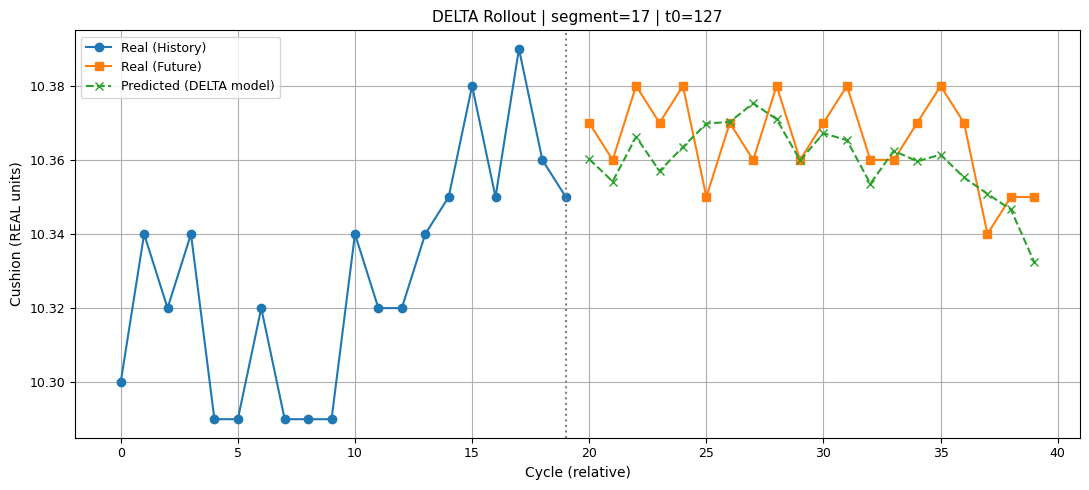

Button(button_style='success', description='Download PNG HQ', icon='download', style=ButtonStyle())

In [ ]:
# Demonstrate a deterministic rollout within one segment.
# Future exogenous values are taken from the recorded series; only cushion
# history is replaced by predictions.

import numpy as np
import torch
import random
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
try:
    from google.colab import files  # Colab only; harmless elsewhere
except Exception:
    files = None

DF_SCALED = df_test
DF_RAW    = df_test_raw
SEG_COL   = "segment"

FORECAST_STEPS = FORECAST_STEPS
HIST_PLOT = HIST_PLOT

valid = []
for seg_id, seg in DF_SCALED.groupby(SEG_COL):
    seg_len = len(seg)
    if seg_len > SEQ_LEN + FORECAST_STEPS + 1:
        valid.append(int(seg_id))

if not valid:
    raise RuntimeError("No segment long enough for forecast. Reduce FORECAST_STEPS or SEQ_LEN.")

seg_id = random.choice(valid)

seg_scaled = DF_SCALED[DF_SCALED[SEG_COL] == seg_id].reset_index(drop=True)
seg_raw    = DF_RAW[DF_RAW[SEG_COL] == seg_id].reset_index(drop=True)

t0_min = SEQ_LEN
t0_max = len(seg_scaled) - FORECAST_STEPS - 1
t0 = random.randint(t0_min, t0_max)

seq = seg_scaled.loc[t0-SEQ_LEN:t0-1, FEATURES].values.astype(np.float32)

real_hist = seg_raw.loc[max(0, t0-HIST_PLOT):t0-1, TARGET_COL].values.astype(float)
real_fut  = seg_raw.loc[t0:t0+FORECAST_STEPS-1, TARGET_COL].values.astype(float)

if len(real_hist) < HIST_PLOT:
    pad = [real_hist[0]] * (HIST_PLOT - len(real_hist))
    real_hist = np.concatenate([pad, real_hist])

last_cush_real = float(seg_raw.loc[t0-1, TARGET_COL])

preds_real = []

model.eval()
with torch.no_grad():
    for k in range(FORECAST_STEPS):
        x = torch.tensor(seq[np.newaxis], dtype=torch.float32).to(device)

        pred_delta_scaled = float(model(x).item())
        pred_delta_real = delta_scaled_to_real(pred_delta_scaled)

        pred_cush_real = last_cush_real + pred_delta_real
        preds_real.append(pred_cush_real)

        next_row = seg_scaled.loc[t0 + k, FEATURES].values.astype(np.float32)

        next_row[cush_in_idx] = cushion_real_to_input_scaled(pred_cush_real)

        seq[:-1] = seq[1:]
        seq[-1] = next_row

        last_cush_real = pred_cush_real

x_hist = np.arange(HIST_PLOT)
x_fut = np.arange(HIST_PLOT, HIST_PLOT + FORECAST_STEPS)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(x_hist, real_hist, label="Real (History)", marker="o")
ax.plot(x_fut, real_fut, label="Real (Future)", marker="s")
ax.plot(x_fut, np.array(preds_real), label="Predicted (DELTA model)", linestyle="--", marker="x")
ax.axvline(HIST_PLOT - 1, linestyle=":", color="gray")
ax.set_xlabel("Cycle (relative)")
ax.set_ylabel("Cushion (REAL units)")
ax.set_title(f"DELTA Rollout | segment={seg_id} | t0={t0}")
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()

file_name = f"delta_rollout_segment_{seg_id}_t0_{t0}.png"
fig.savefig(file_name, dpi=600, bbox_inches="tight")

download_button = widgets.Button(
    description="Download PNG HQ",
    button_style="success",
    icon="download"
)

def download_figure(b):
    if files:
        files.download(file_name)

download_button.on_click(download_figure)

display(download_button)

In [ ]:
# Stationary simulation settings.
# The recipe and initial level may use test summaries for an unconditional
# comparison. This reference mode is separate from the on-demand forecast.

assert USL > LSL

RECIPE_REAL = {k: float(df_test_raw[k].astype(float).mean()) for k in RECIPE_FEATURES}
print("[recipe = TEST means]")
for _k, _v in RECIPE_REAL.items():
    print(f"   {_k}: {_v:.4f}")

N_SIMS     = 1000   # stochastic trajectory runs
SIM_CYCLES = 80     # simulated cycles per run
BURN_IN    = 30     # discarded (synthetic initial window must be forgotten)
assert SIM_CYCLES > BURN_IN

NOISE_SCALE = 1.0

USE_FEATURE_NOISE   = True   # Gaussian noise on recipe inputs
USE_RESIDUAL_NOISE  = True   # residual noise on the delta
USE_EMPIRICAL_RESID = True   # bootstrap from validation residual pool
USE_AR1_RESIDUAL    = True   # AR(1) persistence of residual noise
AR1_RHO             = 0.0    # fallback only; overwritten by the calibration cell

USE_DELTA_CLAMP   = True
DELTA_CLAMP_Q     = 0.995    # quantile of |validation residuals|
USE_CUSHION_CLAMP = False
CUSH_MIN, CUSH_MAX = 9.0, 12.0

INIT_MODE = "test_mean"      # "test_mean" | "train_mean" | "last_train" | "custom"
INIT_CUSHION_REAL = None


[recipe = TEST means]
   Maximum_Injection_Pressure: 1593.8025
   Switch_Over_Pressure: 1592.7241
   Injection_Time: 1.0246
   Dosing_Time: 2.4380
   Back_pressure_ActValue: 65.1428
   SwitchOver_volume_ActValue: 12.9963
   Dosing_Volume_ActValue: 90.9618


In [ ]:
# Compute capability indices and estimate stationary feature-noise scales.
# This cell uses a local test subset when available, with a global fallback.
# On-demand forecasts estimate input dispersion from their preceding local window;
# the feature_sigma dictionary remains a fallback for zero or unavailable scales.

import numpy as np
import pandas as pd

def compute_cp_cpk(samples, lsl, usl):
    samples = np.asarray(samples, dtype=float)
    mu = float(np.mean(samples))
    sigma = float(np.std(samples, ddof=1))
    if sigma <= 1e-12:
        return {"mu": mu, "sigma": sigma, "Cp": np.inf, "Cpk": np.inf,
                "P_out": float(np.mean((samples < lsl) | (samples > usl)))}
    cp = (usl - lsl) / (6.0 * sigma)
    cpk = min((usl - mu) / (3.0 * sigma), (mu - lsl) / (3.0 * sigma))
    p_out = float(np.mean((samples < lsl) | (samples > usl)))
    return {"mu": mu, "sigma": sigma, "Cp": float(cp), "Cpk": float(cpk), "P_out": p_out}

required = ["FEATURES", "TARGET_COL", "df_train_raw", "cush_in_idx"]
missing = [r for r in required if r not in globals()]
if missing:
    raise RuntimeError(f"Missing required objects: {missing}")

HAS_TEST = "df_test_raw" in globals()
if not HAS_TEST:
    print("Warning: df_test_raw not found. Feature noise will be estimated from TRAIN.")
CUSH_IN_COL = FEATURES[cush_in_idx]

feat_cols = [c for c in FEATURES if c != TARGET_COL]

def make_local_mask(df, recipe_dict, rel_tol=0.02):
    mask = np.ones(len(df), dtype=bool)
    for k, v in recipe_dict.items():
        if k in df.columns:
            v = float(v)
            lo, hi = v * (1 - rel_tol), v * (1 + rel_tol)
            x = df[k].astype(float).values
            mask &= (x >= lo) & (x <= hi)
    return mask

df_src = df_test_raw if HAS_TEST else df_train_raw

REL_TOL = 0.02  # 2% (increase if too few local rows)
mask_local = make_local_mask(df_src, RECIPE_REAL, rel_tol=REL_TOL)
df_local = df_src.loc[mask_local]

use_local = len(df_local) >= 200
df_sigma = df_local if use_local else df_src
print(f"[feature_sigma] using {'LOCAL' if use_local else 'GLOBAL'} on {'TEST' if HAS_TEST else 'TRAIN'} | n={len(df_sigma)} | REL_TOL={REL_TOL*100:.1f}%")

feature_sigma = {}
for c in feat_cols:
    if c in df_sigma.columns:
        feature_sigma[c] = float(df_sigma[c].astype(float).std(ddof=1))
    else:
        feature_sigma[c] = 0.0


print("feature_sigma (first 10):", dict(list(feature_sigma.items())[:10]))


[feature_sigma] using LOCAL on TEST | n=2606 | REL_TOL=2.0%
feature_sigma (first 10): {'Maximum_Injection_Pressure': 16.417553534331965, 'Switch_Over_Pressure': 15.91780628698496, 'Injection_Time': 0.0004641640300622316, 'Dosing_Time': 0.016199217513382717, 'Back_pressure_ActValue': 0.4339292431418978, 'SwitchOver_volume_ActValue': 0.004681951942565982, 'Dosing_Volume_ActValue': 0.003820632255367312, 'Cushion_in': 0.018469492746733696}


In [ ]:
# Build and trim the validation residual pool, then estimate its lag-one correlation.
# Fit the fast/slow level-variance targets on validation data.
# Use a pilot at a training operating point to compensate the injected slow-state
# scale for closed-loop attenuation. Target, injected scale and output dispersion
# are different quantities.

import numpy as np
import torch

req = ["model", "device", "delta_scaler"]
missing = [r for r in req if r not in globals()]
if missing:
    raise RuntimeError(f"Missing: {missing}")

if "val_loader" not in globals():
    raise RuntimeError("val_loader not found — run Phase 1 loader cell first")
loader = val_loader
loader_name = "val_loader"

model.eval()
pred_list, true_list = [], []

with torch.no_grad():
    for xb, yb in loader:
        xb = xb.to(device)
        yb = yb.to(device)

        preds = model(xb)

        if preds.ndim == 1:
            preds = preds.unsqueeze(1)
        if yb.ndim == 1:
            yb = yb.unsqueeze(1)

        p1 = preds[:, 0].detach().cpu().numpy().reshape(-1, 1)
        t1 = yb[:, 0].detach().cpu().numpy().reshape(-1, 1)

        pred_real = delta_scaler.inverse_transform(p1).ravel().astype(np.float32)
        true_real = delta_scaler.inverse_transform(t1).ravel().astype(np.float32)

        pred_list.append(pred_real)
        true_list.append(true_real)

pred_real = np.concatenate(pred_list)
true_real = np.concatenate(true_list)

residual_pool_raw = (true_real - pred_real).astype(np.float32)  # chronological (val_loader shuffle=False)
sigma_raw = float(np.std(residual_pool_raw, ddof=1))

_pool_mad = mad_sigma(residual_pool_raw)
_pool_thr = ROBUST_K * _pool_mad
_keep = np.abs(residual_pool_raw) <= _pool_thr
residual_pool = residual_pool_raw[_keep].astype(np.float32)
n_trimmed = int((~_keep).sum())

sigma_res = float(np.std(residual_pool, ddof=1))
bias_res  = float(np.mean(residual_pool))

_r = residual_pool_raw[_keep]  # chronological order preserved by boolean mask
_rc = _r - _r.mean()
AR1_RHO = float(np.clip(np.corrcoef(_rc[:-1], _rc[1:])[0, 1], -0.95, 0.95))

print(f"[{loader_name} residual calibration —  robust]")
print(f"  pool raw:     n={len(residual_pool_raw)}  sigma={sigma_raw:.6f}")
print(f"  trim rule:    |res| <= {ROBUST_K:.1f} × MAD-σ({_pool_mad:.6f}) = {_pool_thr:.6f}")
print(f"  pool clean:   n={len(residual_pool)}  sigma={sigma_res:.6f}  (removed {n_trimmed} anomalous residuals)")
print(f"  bias_res    = {bias_res:.6f}")
print(f"  AR1_RHO (estimated lag-1 autocorr) = {AR1_RHO:+.3f}"
      f"  -> {'self-correcting (anti-persistent)' if AR1_RHO < 0 else 'drifting (persistent)'}")

delta_clamp_abs = float(np.quantile(np.abs(residual_pool), DELTA_CLAMP_Q))
print(f"[delta clamp] |Δ| @ q={DELTA_CLAMP_Q}: {delta_clamp_abs:.6f}")

noise_calibration_summary = {
    "pool_n_raw": int(len(residual_pool_raw)), "sigma_raw": sigma_raw,
    "pool_n_clean": int(len(residual_pool)), "sigma_clean": sigma_res,
    "n_trimmed": n_trimmed, "trim_threshold": float(_pool_thr),
    "bias_res": bias_res, "ar1_rho_estimated": AR1_RHO,
    "delta_clamp_abs": delta_clamp_abs,
}

if "df_test_raw" in globals() and TARGET_COL in df_test_raw.columns:
    std_test_delta = float(df_test_raw[TARGET_COL].astype(float).diff().dropna().std(ddof=1))
    print(f"[sanity] std(ΔC_real test) = {std_test_delta:.6f}")


def fit_two_timescale_noise(df_raw, target_col, seg_col="segment",
                            anom_thr=None, h_set=(1, 2, 3, 5, 8, 12, 20, 30, 50)):
    """Generic variogram fit of (sigma_fast, sigma_slow, phi_slow) on a level series."""
    V = {}
    for h in h_set:
        diffs = []
        for _, g in df_raw.groupby(seg_col):
            c = g[target_col].astype(float).values.copy()
            if anom_thr is not None:
                dc = np.diff(c, prepend=c[0])
                c[np.abs(dc) > anom_thr] = np.nan   # mask anomalous cycles
            if len(c) > h:
                d = c[h:] - c[:-h]
                diffs.append(d[np.isfinite(d)])
        if diffs:
            d = np.concatenate(diffs)
            if len(d) > 50:
                V[h] = 0.5 * float(np.var(d, ddof=1))
    hs = np.array(sorted(V.keys())); vs = np.array([V[h] for h in hs])
    best = (np.inf, 0.0, 0.0, 0.0)                      # sse, sig2_fast, sig2_slow, phi
    for phi in np.linspace(0.50, 0.999, 250):
        X = np.column_stack([np.ones_like(hs, dtype=float), 1.0 - phi ** hs])
        coef, *_ = np.linalg.lstsq(X, vs, rcond=None)
        a, b = max(coef[0], 0.0), max(coef[1], 0.0)
        sse = float(np.sum((X @ np.array([a, b]) - vs) ** 2))
        if sse < best[0]:
            best = (sse, a, b, float(phi))
    _, s2f, s2s, phi = best
    return {"sigma_fast": float(np.sqrt(s2f)), "sigma_slow": float(np.sqrt(s2s)),
            "phi_slow": phi, "variogram": {int(h): float(V[h]) for h in hs}}

_ts = fit_two_timescale_noise(df_val_raw, TARGET_COL, anom_thr=DC_ANOM_THR)
SLOW_SIGMA_TARGET = _ts["sigma_slow"]
SLOW_PHI   = _ts["phi_slow"]
USE_SLOW_NOISE = SLOW_SIGMA_TARGET > 1e-6

print("\n")
print(f"  sigma_fast (level jitter):  {_ts['sigma_fast']:.4f}")
print(f"  sigma_slow (level wander):  {SLOW_SIGMA_TARGET:.4f}")
print(f"  phi_slow  (per-cycle inertia): {SLOW_PHI:.4f}"
      f"  -> wander half-life ≈ {np.log(0.5)/np.log(SLOW_PHI):.0f} cycles" if USE_SLOW_NOISE else "")
if not USE_SLOW_NOISE:
    print("  -> no slow component detected: simulator runs fast-noise only (automatic fallback)")

noise_calibration_summary.update({
    "sigma_fast_level": _ts["sigma_fast"], "sigma_slow_level": SLOW_SIGMA_TARGET,
    "phi_slow": SLOW_PHI, "variogram": _ts["variogram"],
})


def _pilot_run(slow_sigma_inj, n_runs=300, steps=80, burn=30, seed=999):
    """Compact closed-loop pilot: fast residual noise (+AR1, clamp) + optional slow AR(1)."""
    rng = np.random.default_rng(seed)
    n_feat = len(FEATURES)
    c0 = float(df_train_raw[TARGET_COL].astype(float).mean())
    base = np.zeros((n_feat,), dtype=np.float32)
    for j, f in enumerate(FEATURES):
        base[j] = c0 if j == cush_in_idx else float(df_train_raw[f].astype(float).mean())
    _xc = np.asarray(x_scaler.center_, dtype=np.float32)
    _xs = np.asarray(x_scaler.scale_, dtype=np.float32)
    _dc = float(getattr(delta_scaler, "center_", [0.0])[0]); _ds = float(delta_scaler.scale_[0])
    seq = torch.from_numpy(np.tile(((base - _xc) / _xs), (n_runs, SEQ_LEN, 1))).to(device, torch.float32)
    C = torch.full((n_runs,), c0, device=device, dtype=torch.float32)
    e_prev = np.zeros(n_runs, dtype=np.float32); s_prev = np.zeros(n_runs, dtype=np.float32)
    out = np.empty((n_runs, steps), dtype=np.float32)
    rho = float(AR1_RHO)
    model.eval()
    with torch.no_grad():
        for k in range(steps):
            o = model(seq); o = o[:, 0] if o.ndim == 2 else o
            d = o.detach().cpu().numpy().astype(np.float32) * _ds + _dc + float(bias_res)
            e = rng.choice(residual_pool, size=n_runs).astype(np.float32)
            e = rho * e_prev + np.sqrt(max(1e-8, 1 - rho * rho)) * e; e_prev = e
            d += e
            if slow_sigma_inj > 0:
                s_new = SLOW_PHI * s_prev + slow_sigma_inj * np.sqrt(1 - SLOW_PHI**2) * \
                        rng.normal(0, 1, n_runs).astype(np.float32)
                d += (s_new - s_prev); s_prev = s_new
            d = np.clip(d, -delta_clamp_abs, delta_clamp_abs)
            C = C + torch.from_numpy(d).to(device, torch.float32)
            out[:, k] = C.detach().cpu().numpy()
            nxt = np.tile(base, (n_runs, 1)).astype(np.float32)
            nxt[:, cush_in_idx] = out[:, k]
            seq[:, :-1, :] = seq[:, 1:, :]
            seq[:, -1, :] = torch.from_numpy((nxt - _xc) / _xs).to(device, torch.float32)
    return out[:, burn:]

if USE_SLOW_NOISE:
    _v_fast = float(np.var(_pilot_run(0.0).reshape(-1), ddof=1))
    _v_with = float(np.var(_pilot_run(SLOW_SIGMA_TARGET).reshape(-1), ddof=1))
    _ach = float(np.sqrt(max(_v_with - _v_fast, 0.0)))
    ATTENUATION = float(np.clip(_ach / SLOW_SIGMA_TARGET, 0.05, 1.5))
    SLOW_SIGMA = float(min(SLOW_SIGMA_TARGET / ATTENUATION, 5.0 * SLOW_SIGMA_TARGET))
    _v_chk = float(np.var(_pilot_run(SLOW_SIGMA).reshape(-1), ddof=1))
    _ach_chk = float(np.sqrt(max(_v_chk - _v_fast, 0.0)))
    if abs(_ach_chk - SLOW_SIGMA_TARGET) / SLOW_SIGMA_TARGET > 0.15 and _ach_chk > 1e-9:
        SLOW_SIGMA = float(min(SLOW_SIGMA * SLOW_SIGMA_TARGET / _ach_chk, 5.0 * SLOW_SIGMA_TARGET))
        _v_chk = float(np.var(_pilot_run(SLOW_SIGMA).reshape(-1), ddof=1))
        _ach_chk = float(np.sqrt(max(_v_chk - _v_fast, 0.0)))
    print("\n")
    print(f"  fast-only output sigma:      {np.sqrt(_v_fast):.4f}  (target sigma_fast ≈ {_ts['sigma_fast']:.4f})")
    print(f"  slow target / achieved@1x:   {SLOW_SIGMA_TARGET:.4f} / {_ach:.4f}  -> damping factor {ATTENUATION:.2f}")
    print(f"  corrected injected sigma:    {SLOW_SIGMA:.4f}")
    print(f"  verification: achieved slow = {_ach_chk:.4f}  (target {SLOW_SIGMA_TARGET:.4f})")
else:
    SLOW_SIGMA, ATTENUATION = 0.0, 1.0

noise_calibration_summary.update({
    "sigma_slow_target": SLOW_SIGMA_TARGET if USE_SLOW_NOISE else 0.0,
    "sigma_slow_injected": SLOW_SIGMA,
    "closed_loop_damping": ATTENUATION,
})


[val_loader residual calibration —  robust]
  pool raw:     n=3842  sigma=0.133430
  trim rule:    |res| <= 5.0 × MAD-σ(0.015872) = 0.079359
  pool clean:   n=3818  sigma=0.014624  (removed 24 anomalous residuals)
  bias_res    = -0.000342
  AR1_RHO (estimated lag-1 autocorr) = -0.099  -> self-correcting (anti-persistent)
[delta clamp] |Δ| @ q=0.995: 0.037765
[sanity] std(ΔC_real test) = 0.023704


  sigma_fast (level jitter):  0.0152
  sigma_slow (level wander):  0.0159
  phi_slow  (per-cycle inertia): 0.9269  -> wander half-life ≈ 9 cycles


  fast-only output sigma:      0.0139  (target sigma_fast ≈ 0.0152)
  slow target / achieved@1x:   0.0159 / 0.0051  -> damping factor 0.32
  corrected injected sigma:    0.0495
  verification: achieved slow = 0.0144  (target 0.0159)


### Residual dependence and timing

Compare the lag-one correlations of cushion increments and model residuals. CPU-only timing is reported later.


--- LAG-ONE AUTOCORRELATION: PROCESS AND GENERATOR ---
                    series     n     std  rho lag-1  rho lag-2                             interpretation
     Delta_Cushion (train) 17953 0.02013     -0.557      0.090 process anti-persistence (self-correcting)
       Delta_Cushion (val)  3846 0.02325     -0.609      0.214 process anti-persistence (self-correcting)
      Delta_Cushion (test)  3864 0.02360     -0.610      0.196 process anti-persistence (self-correcting)
TCN residuals (validation)  3818 0.01462     -0.099      0.004 near-white: dynamics absorbed by the model

AR1_RHO used by the noise generator = -0.099  (estimated from the residual pool, not from the raw increments)
Variance-explained argument: the raw increment anti-persistence (-0.610) is ~6x stronger than what survives in the residuals (-0.099).


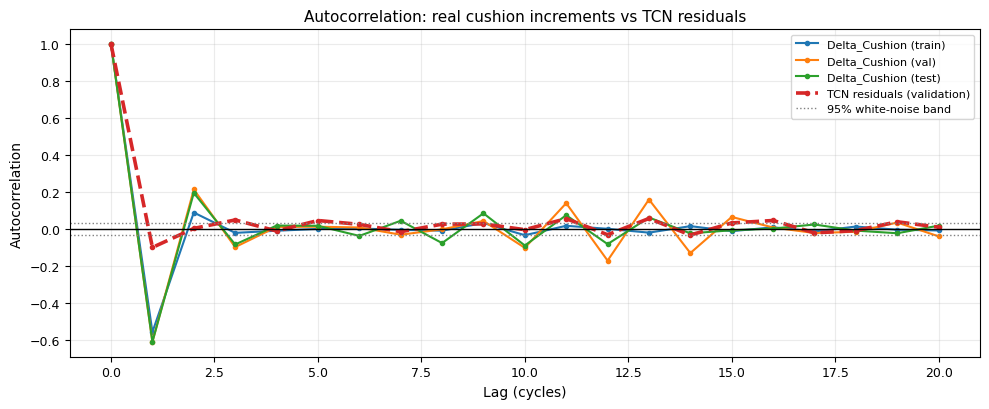

In [ ]:
# Compare lag-one correlations of cushion increments and validation residuals.
# A weaker residual correlation suggests that the model captures some temporal
# structure; it does not establish a unique physical mechanism or independence.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _acf(x, nlags=20):
    x = np.asarray(x, dtype=float)
    x = x - x.mean()
    d = np.dot(x, x)
    return np.array([1.0 if k == 0 else float(np.dot(x[:-k], x[k:]) / d)
                     for k in range(nlags + 1)])

_thr = float(DC_ANOM_THR) if "DC_ANOM_THR" in globals() else np.inf
_acf_rows, _curves = [], {}

for _name, _df in [("train", df_train_raw), ("val", df_val_raw), ("test", df_test_raw)]:
    d = _df["Delta_Cushion"].astype(float).values
    d = d[np.isfinite(d)]
    d_clean = d[np.abs(d) <= _thr] if np.isfinite(_thr) else d
    a = _acf(d_clean, 20)
    _curves[f"Delta_Cushion ({_name})"] = a
    _acf_rows.append({"series": f"Delta_Cushion ({_name})", "n": len(d_clean),
                      "std": round(float(np.std(d_clean, ddof=1)), 5),
                      "rho lag-1": round(float(a[1]), 3),
                      "rho lag-2": round(float(a[2]), 3),
                      "interpretation": "process anti-persistence (self-correcting)"})

_rp = np.asarray(residual_pool, dtype=float)
_a_res = _acf(_rp, 20)
_curves["TCN residuals (validation)"] = _a_res
_acf_rows.append({"series": "TCN residuals (validation)", "n": len(_rp),
                  "std": round(float(np.std(_rp, ddof=1)), 5),
                  "rho lag-1": round(float(_a_res[1]), 3),
                  "rho lag-2": round(float(_a_res[2]), 3),
                  "interpretation": "near-white: dynamics absorbed by the model"})

acf_tab = pd.DataFrame(_acf_rows)
print("--- LAG-ONE AUTOCORRELATION: PROCESS AND GENERATOR ---")
print(acf_tab.to_string(index=False))
print(f"\nAR1_RHO used by the noise generator = {float(AR1_RHO):+.3f}  "
      f"(estimated from the residual pool, not from the raw increments)")
_ratio = abs(float(_curves['Delta_Cushion (test)'][1])) / max(1e-9, abs(float(_a_res[1])))
print(f"Variance-explained argument: the raw increment anti-persistence "
      f"({_curves['Delta_Cushion (test)'][1]:+.3f}) is ~{_ratio:.0f}x stronger than what "
      f"survives in the residuals ({_a_res[1]:+.3f}).")
acf_tab.to_csv("acf_process_vs_generator.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.2))
_lags = np.arange(21)
for k, v in _curves.items():
    _st = "--" if "residual" in k else "-"
    _lw = 2.6 if "residual" in k else 1.5
    ax.plot(_lags, v, _st, lw=_lw, marker="o", ms=3, label=k)
ax.axhline(0, color="black", lw=1)
ax.axhline(1.96 / np.sqrt(len(_rp)), color="grey", ls=":", lw=1)
ax.axhline(-1.96 / np.sqrt(len(_rp)), color="grey", ls=":", lw=1,
           label="95% white-noise band")
ax.set_title("Autocorrelation: real cushion increments vs TCN residuals")
ax.set_xlabel("Lag (cycles)"); ax.set_ylabel("Autocorrelation")
ax.legend(fontsize=8); ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig("acf_process_vs_generator.png", dpi=600, bbox_inches="tight")
plt.show()

acf_summary = {"table": acf_tab.to_dict(orient="records"),
               "rho_delta_test": float(_curves["Delta_Cushion (test)"][1]),
               "rho_residuals": float(_a_res[1]),
               "AR1_RHO_used": float(AR1_RHO)}

In [ ]:
# Simulate stationary trajectories in a batch and discard the burn-in.
# Fast residual noise uses an AR(1) recombination. The slow state enters through
# its change, s_new-s_prev, before the combined increment is clamped.
# The clamp can affect tails and dispersion; its effect is not isolated here.

import numpy as np
import torch

req = ["x_scaler", "delta_scaler", "model", "device", "FEATURES", "cush_in_idx",
       "df_train_raw", "TARGET_COL", "SEQ_LEN",
       "feature_sigma", "sigma_res", "bias_res", "residual_pool",
       "LSL", "USL",
       "N_SIMS", "SIM_CYCLES", "BURN_IN",
       "USE_FEATURE_NOISE", "USE_RESIDUAL_NOISE", "USE_EMPIRICAL_RESID",
       "USE_AR1_RESIDUAL", "AR1_RHO", "NOISE_SCALE",
       "USE_DELTA_CLAMP", "delta_clamp_abs",
       "INIT_MODE"]
missing = [r for r in req if r not in globals()]
if missing:
    raise RuntimeError(f"Missing required objects for MC: {missing}")

n_runs = int(N_SIMS)
steps  = int(SIM_CYCLES)
seq_len = int(SEQ_LEN)
n_feat = len(FEATURES)

_x_mean  = getattr(x_scaler, "center_", getattr(x_scaler, "mean_", None))
_x_scale = getattr(x_scaler, "scale_", None)

def scale_x_fast(x_real: np.ndarray) -> np.ndarray:
    if _x_mean is not None and _x_scale is not None:
        return ((x_real - _x_mean) / _x_scale).astype(np.float32)
    import pandas as pd
    shp = x_real.shape
    x2 = x_real.reshape(-1, shp[-1])
    x2s = x_scaler.transform(pd.DataFrame(x2, columns=FEATURES)).astype(np.float32)
    return x2s.reshape(*shp)

_d_mean  = float(getattr(delta_scaler, "center_", getattr(delta_scaler, "mean_", [0.0]))[0])
_d_scale = float(getattr(delta_scaler, "scale_", [1.0])[0])

def delta_scaled_to_real_fast(d_scaled: np.ndarray) -> np.ndarray:
    return d_scaled * _d_scale + _d_mean

if INIT_MODE == "test_mean":
    if "df_test_raw" not in globals():
        raise RuntimeError("INIT_MODE='test_mean' requires df_test_raw")
    C0_real = float(df_test_raw[TARGET_COL].astype(float).mean())
elif INIT_MODE == "train_mean":
    C0_real = float(df_train_raw[TARGET_COL].astype(float).mean())
elif INIT_MODE == "last_train":
    i0 = df_train_raw.index[-1]
    C0_real = float(df_train_raw.loc[i0, TARGET_COL])
elif INIT_MODE == "custom":
    if INIT_CUSHION_REAL is None:
        raise ValueError("INIT_CUSHION_REAL must be set when INIT_MODE='custom'")
    C0_real = float(INIT_CUSHION_REAL)
else:
    raise ValueError("INIT_MODE must be: test_mean | train_mean | last_train | custom")

base_row_real = np.zeros((n_feat,), dtype=np.float32)
for i, f in enumerate(FEATURES):
    if f == FEATURES[cush_in_idx]:
        base_row_real[i] = float(C0_real)  # will be overwritten in seq anyway
    elif f in RECIPE_REAL:
        base_row_real[i] = float(RECIPE_REAL[f])
    else:
        if f in df_train_raw.columns:
            base_row_real[i] = float(df_train_raw[f].astype(float).mean())
        else:
            base_row_real[i] = 0.0

sigma_vec = np.array([float(feature_sigma.get(f, 0.0)) for f in FEATURES], dtype=np.float32)
sigma_vec[cush_in_idx] = 0.0
sigma_vec *= float(NOISE_SCALE)

use_feat = bool(USE_FEATURE_NOISE) and np.any(sigma_vec > 0)
use_res  = bool(USE_RESIDUAL_NOISE) and (float(sigma_res) > 0)

seq_real = np.tile(base_row_real, (n_runs, seq_len, 1)).astype(np.float32)
seq_real[:, :, cush_in_idx] = float(C0_real)

if use_feat:
    seq_real += np.random.normal(0.0, sigma_vec, size=(n_runs, seq_len, n_feat)).astype(np.float32)

seq_scaled_np = scale_x_fast(seq_real)
seq_scaled = torch.from_numpy(seq_scaled_np).to(device=device, dtype=torch.float32)

C_prev = torch.full((n_runs,), float(C0_real), device=device, dtype=torch.float32)
traj_full = np.empty((n_runs, steps), dtype=np.float32)
base_row_batch = np.tile(base_row_real, (n_runs, 1)).astype(np.float32)

e_prev = np.zeros((n_runs,), dtype=np.float32)

if 'USE_SLOW_NOISE' in globals() and USE_SLOW_NOISE:
    s_prev = np.random.normal(0.0, SLOW_SIGMA, size=(n_runs,)).astype(np.float32)
else:
    s_prev = np.zeros((n_runs,), dtype=np.float32)

model.eval()
with torch.no_grad():
    for k in range(steps):
        pred_delta_scaled = model(seq_scaled).squeeze(-1)
        pred_delta_scaled_np = pred_delta_scaled.detach().cpu().numpy().astype(np.float32)

        pred_delta_real_np = delta_scaled_to_real_fast(pred_delta_scaled_np)

        pred_delta_real_np += float(bias_res)

        if use_res:
            if USE_EMPIRICAL_RESID and (residual_pool is not None) and (len(residual_pool) > 100):
                e = np.random.choice(residual_pool, size=n_runs, replace=True).astype(np.float32)
            else:
                e = np.random.normal(0.0, float(sigma_res), size=(n_runs,)).astype(np.float32)

            e *= float(NOISE_SCALE)

            if USE_AR1_RESIDUAL:
                rho = float(AR1_RHO)
                e = rho * e_prev + np.sqrt(max(1e-8, 1.0 - rho*rho)) * e
                e_prev = e

            pred_delta_real_np += e

        if 'USE_SLOW_NOISE' in globals() and USE_SLOW_NOISE:
            s_new = SLOW_PHI * s_prev + SLOW_SIGMA * np.sqrt(1.0 - SLOW_PHI**2) * \
                    np.random.normal(0.0, 1.0, size=(n_runs,)).astype(np.float32)
            pred_delta_real_np += (s_new - s_prev)
            s_prev = s_new

        if USE_DELTA_CLAMP and (delta_clamp_abs is not None):
            clamp_abs = float(delta_clamp_abs) * float(NOISE_SCALE)
            pred_delta_real_np = np.clip(pred_delta_real_np, -clamp_abs, +clamp_abs)

        pred_delta_real = torch.from_numpy(pred_delta_real_np).to(device=device, dtype=torch.float32)

        C_next = C_prev + pred_delta_real
        if USE_CUSHION_CLAMP:
            C_next = torch.clamp(C_next, float(CUSH_MIN), float(CUSH_MAX))

        traj_full[:, k] = C_next.detach().cpu().numpy()

        next_row_real = base_row_batch.copy()
        if use_feat:
            next_row_real += np.random.normal(0.0, sigma_vec, size=(n_runs, n_feat)).astype(np.float32)
        next_row_real[:, cush_in_idx] = traj_full[:, k]

        next_row_scaled_np = scale_x_fast(next_row_real)
        next_row_scaled = torch.from_numpy(next_row_scaled_np).to(device=device, dtype=torch.float32)

        seq_scaled[:, :-1, :] = seq_scaled[:, 1:, :]
        seq_scaled[:, -1, :] = next_row_scaled

        C_prev = C_next

runs = traj_full[:, BURN_IN:] if BURN_IN > 0 else traj_full

samples = runs.reshape(-1)
stats = compute_cp_cpk(samples, LSL, USL)

print("========== Virtual SPC / Predictive Capability (ABSOLUTE Cushion) ==========")
print(f"Runs x cycles: {runs.shape[0]} x {runs.shape[1]}  (burn-in={BURN_IN})")
print(f"Mean (mu):     {stats['mu']:.4f}")
print(f"Std  (sigma):  {stats['sigma']:.4f}")
print(f"Cp:            {stats['Cp']:.4f}")
print(f"Cpk:           {stats['Cpk']:.4f}")
print(f"P(out of spec):{stats['P_out']*100:.2f}%")
print("===========================================================================")


========== Virtual SPC / Predictive Capability (ABSOLUTE Cushion) ==========
Runs x cycles: 1000 x 50  (burn-in=30)
Mean (mu):     10.3337
Std  (sigma):  0.0207
Cp:            4.8339
Cpk:           4.7740
P(out of spec):0.00%


In [ ]:
# Sensitivity check: exclude stationary runs leaving the plausibility band.
# This is separate from the primary unfiltered ensemble and can change capability
# by selecting trajectories. No on-demand forecasts use this filter.

import numpy as np

req = ["runs", "TARGET_CUSHION", "LSL", "USL", "compute_cp_cpk"]
missing = [r for r in req if r not in globals()]
if missing:
    raise RuntimeError(f"Missing required objects: {missing}")

PL_LOW  = TARGET_CUSHION - 0.4
PL_HIGH = TARGET_CUSHION + 0.4

good_runs_mask = np.all((runs >= PL_LOW) & (runs <= PL_HIGH), axis=1)
runs_good = runs[good_runs_mask]

print("========== Plausibility Filter ==========")
print(f"Kept runs: {runs_good.shape[0]} / {runs.shape[0]} "
      f"({100 * runs_good.shape[0] / runs.shape[0]:.2f}%)")
print(f"Discarded runs (run-away): {runs.shape[0] - runs_good.shape[0]}")
print("Plausibility band:", PL_LOW, "→", PL_HIGH)
print("========================================")

samples_good = runs_good.reshape(-1)
stats_good = compute_cp_cpk(samples_good, LSL, USL)

print("========== Capability, FILTERED runs (sensitivity analysis — not primary) ==========")
print(f"Mean (mu):     {stats_good['mu']:.4f}")
print(f"Std  (sigma):  {stats_good['sigma']:.4f}")
print(f"Cp:            {stats_good['Cp']:.4f}")
print(f"Cpk:           {stats_good['Cpk']:.4f}")
print(f"P(out of spec):{stats_good['P_out']*100:.2f}%")
print("===================================================")


========== Plausibility Filter ==========
Kept runs: 1000 / 1000 (100.00%)
Discarded runs (run-away): 0
Plausibility band: 9.93 → 10.73
========== Capability, FILTERED runs (sensitivity analysis — not primary) ==========
Mean (mu):     10.3337
Std  (sigma):  0.0207
Cp:            4.8339
Cpk:           4.7740
P(out of spec):0.00%


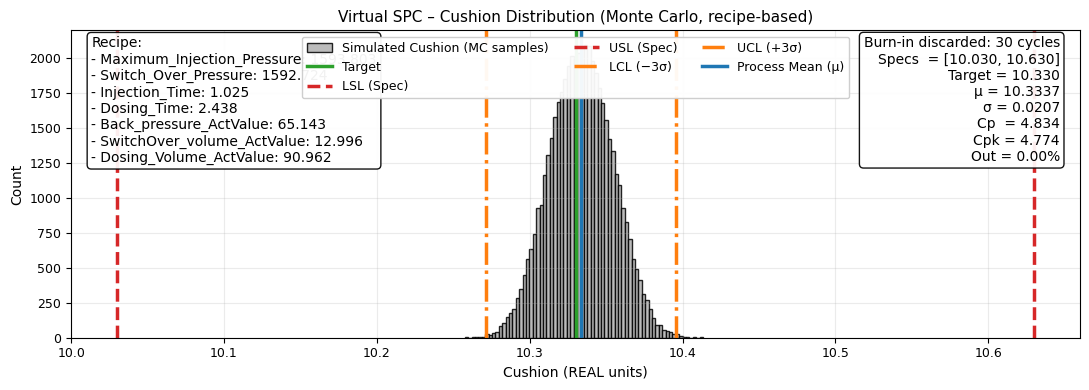

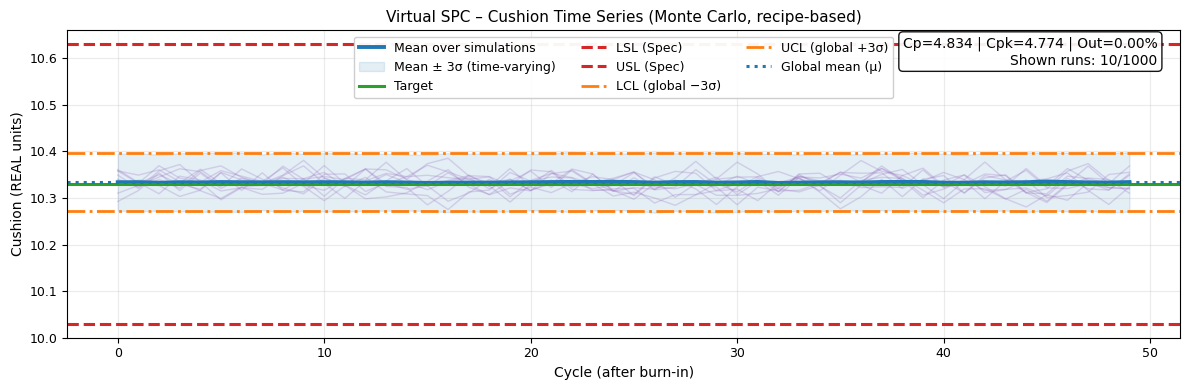


================ DOWNLOAD FIGURES ================


Button(button_style='success', description='Download Histogram PNG', icon='download', layout=Layout(width='280…

Button(button_style='success', description='Download Time Series PNG', icon='download', layout=Layout(width='2…

In [ ]:
# Plot stationary simulated cushion values and trajectories against process limits.
# Use the unfiltered ensemble for the primary summaries.

import os
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
try:
    from google.colab import files  # Colab only; harmless elsewhere
except Exception:
    files = None

req = ["runs", "LSL", "USL", "compute_cp_cpk", "TARGET_CUSHION", "RECIPE_REAL", "BURN_IN"]
missing = [r for r in req if r not in globals()]
if missing:
    raise RuntimeError(f"Missing required objects: {missing}")

runs = np.asarray(runs, dtype=float)
samples = runs.reshape(-1)

results = compute_cp_cpk(samples, LSL, USL)
mu_real = results["mu"]
sigma_real = results["sigma"]
Cp = results["Cp"]
Cpk = results["Cpk"]
P_out = results["P_out"]

LCL_REAL = mu_real - 3.0 * sigma_real
UCL_REAL = mu_real + 3.0 * sigma_real

output_dir = "cell_5_spc_outputs"
os.makedirs(output_dir, exist_ok=True)

def make_download_button(file_path, button_label):
    button = widgets.Button(
        description=button_label,
        button_style="success",
        icon="download",
        layout=widgets.Layout(width="280px")
    )

    def on_click(b):
        if files:
            files.download(file_path)

    button.on_click(on_click)
    return button

COL_HIST   = "#B0B0B0"
COL_TARGET = "#2CA02C"
COL_SPEC   = "#D62728"
COL_CTRL   = "#FF7F0E"
COL_MEAN   = "#1F77B4"
COL_RUN    = "#9467BD"
COL_BAND   = "#1F77B4"

recipe_text = "Recipe:\n" + "\n".join([f"- {k}: {v:.3f}" for k, v in RECIPE_REAL.items()])

fig1, ax1 = plt.subplots(figsize=(11, 4))

ax1.hist(samples, bins=70, color=COL_HIST, edgecolor="black", alpha=0.85, label="Simulated Cushion (MC samples)")

ax1.axvline(TARGET_CUSHION, color=COL_TARGET, linestyle="-",  linewidth=2.5, label="Target")
ax1.axvline(LSL,            color=COL_SPEC,   linestyle="--", linewidth=2.5, label="LSL (Spec)")
ax1.axvline(USL,            color=COL_SPEC,   linestyle="--", linewidth=2.5, label="USL (Spec)")
ax1.axvline(LCL_REAL,       color=COL_CTRL,   linestyle="-.", linewidth=2.5, label="LCL (−3σ)")
ax1.axvline(UCL_REAL,       color=COL_CTRL,   linestyle="-.", linewidth=2.5, label="UCL (+3σ)")
ax1.axvline(mu_real,        color=COL_MEAN,   linestyle="-",  linewidth=2.5, label="Process Mean (µ)")

ax1.set_title("Virtual SPC – Cushion Distribution (Monte Carlo, recipe-based)")
ax1.set_xlabel("Cushion (REAL units)")
ax1.set_ylabel("Count")
ax1.grid(True, alpha=0.25)

ax1.text(
    0.98, 0.98,
    (
        f"Burn-in discarded: {BURN_IN} cycles\n"
        f"Specs  = [{LSL:.3f}, {USL:.3f}]\n"
        f"Target = {TARGET_CUSHION:.3f}\n"
        f"µ = {mu_real:.4f}\n"
        f"σ = {sigma_real:.4f}\n"
        f"Cp  = {Cp:.3f}\n"
        f"Cpk = {Cpk:.3f}\n"
        f"Out = {P_out*100:.2f}%"
    ),
    transform=ax1.transAxes,
    ha="right", va="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.92)
)

ax1.text(
    0.02, 0.98,
    recipe_text,
    transform=ax1.transAxes,
    ha="left", va="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.92)
)

ax1.legend(loc="upper center", ncol=3, framealpha=0.95)
plt.tight_layout()
plt.show()

hist_path = os.path.join(output_dir, "virtual_spc_histogram.png")
fig1.savefig(hist_path, dpi=600, bbox_inches="tight")
plt.close(fig1)

fig2, ax2 = plt.subplots(figsize=(12, 4))

n_runs, n_cycles = runs.shape
x = np.arange(n_cycles)

n_show = min(10, n_runs)
for i in range(n_show):
    ax2.plot(runs[i], color=COL_RUN, alpha=0.25, linewidth=1)

mean_path = runs.mean(axis=0)
std_path  = runs.std(axis=0, ddof=1)

ax2.plot(mean_path, color=COL_MEAN, linewidth=2.8, label="Mean over simulations")

ax2.fill_between(
    x, mean_path - 3*std_path, mean_path + 3*std_path,
    color=COL_BAND, alpha=0.12, label="Mean ± 3σ (time-varying)"
)

ax2.axhline(TARGET_CUSHION, color=COL_TARGET, linestyle="-",  linewidth=2.2, label="Target")
ax2.axhline(LSL,            color=COL_SPEC,   linestyle="--", linewidth=2.2, label="LSL (Spec)")
ax2.axhline(USL,            color=COL_SPEC,   linestyle="--", linewidth=2.2, label="USL (Spec)")
ax2.axhline(LCL_REAL,       color=COL_CTRL,   linestyle="-.", linewidth=2.0, label="LCL (global −3σ)")
ax2.axhline(UCL_REAL,       color=COL_CTRL,   linestyle="-.", linewidth=2.0, label="UCL (global +3σ)")
ax2.axhline(mu_real,        color=COL_MEAN,   linestyle=":",  linewidth=2.2, label="Global mean (µ)")

ax2.set_title("Virtual SPC – Cushion Time Series (Monte Carlo, recipe-based)")
ax2.set_xlabel("Cycle (after burn-in)")
ax2.set_ylabel("Cushion (REAL units)")
ax2.grid(True, alpha=0.25)

ax2.text(
    0.98, 0.98,
    f"Cp={Cp:.3f} | Cpk={Cpk:.3f} | Out={P_out*100:.2f}%\nShown runs: {n_show}/{n_runs}",
    transform=ax2.transAxes,
    ha="right", va="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.92)
)

ax2.legend(loc="upper center", ncol=3, framealpha=0.95)
plt.tight_layout()
plt.show()

ts_path = os.path.join(output_dir, "virtual_spc_time_series.png")
fig2.savefig(ts_path, dpi=600, bbox_inches="tight")
plt.close(fig2)

print("\n================ DOWNLOAD FIGURES ================")
display(make_download_button(hist_path, "Download Histogram PNG"))
display(make_download_button(ts_path, "Download Time Series PNG"))

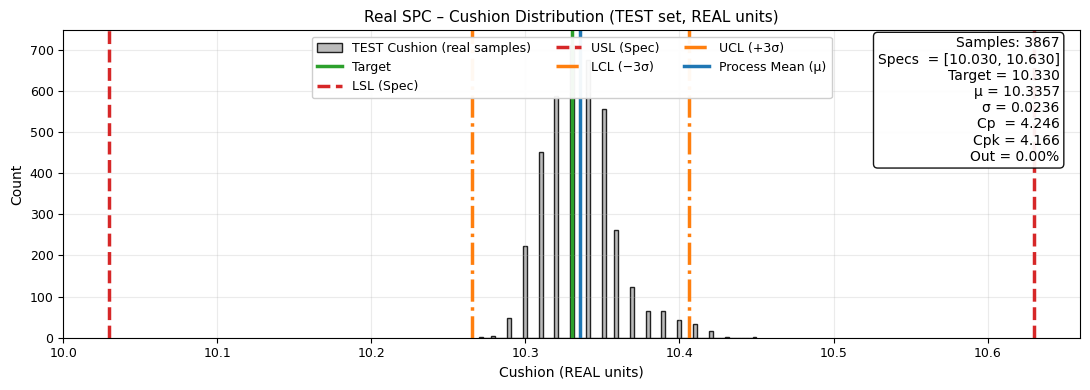

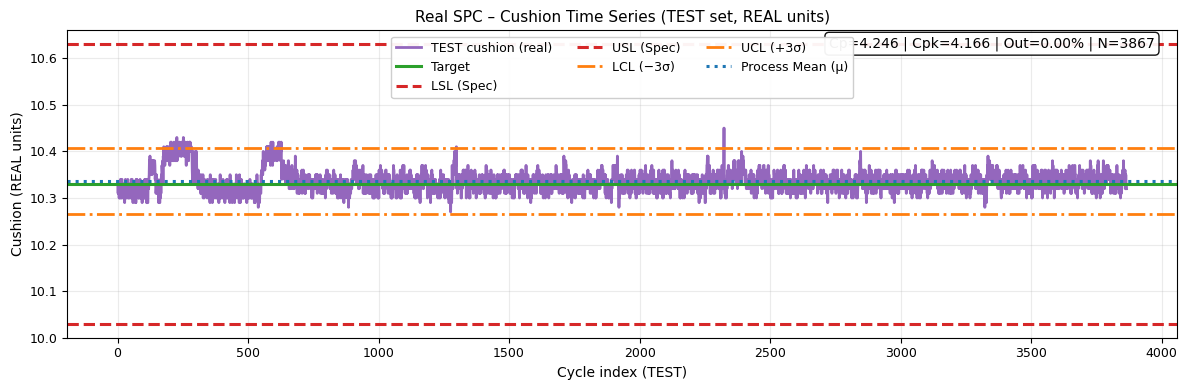


================ DOWNLOAD FIGURES ================


Button(button_style='success', description='Download Real SPC Histogram PNG', icon='download', layout=Layout(w…

Button(button_style='success', description='Download Real SPC Time Series PNG', icon='download', layout=Layout…

In [ ]:
# Plot measured test cushion values using the same display conventions.

import os
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
try:
    from google.colab import files  # Colab only; harmless elsewhere
except Exception:
    files = None

req = ["df_test_raw", "TARGET_COL", "LSL", "USL", "compute_cp_cpk", "TARGET_CUSHION"]
missing = [r for r in req if r not in globals()]
if missing:
    raise RuntimeError(f"Missing required objects: {missing}")

output_dir = "real_spc_test_outputs"
os.makedirs(output_dir, exist_ok=True)

def make_download_button(file_path, button_label):
    button = widgets.Button(
        description=button_label,
        button_style="success",
        icon="download",
        layout=widgets.Layout(width="280px")
    )

    def on_click(b):
        if files:
            files.download(file_path)

    button.on_click(on_click)
    return button

test_series = df_test_raw[TARGET_COL].astype(float).dropna().values
samples = test_series.copy()

results = compute_cp_cpk(samples, LSL, USL)
mu_real = results["mu"]
sigma_real = results["sigma"]
Cp = results["Cp"]
Cpk = results["Cpk"]
P_out = results["P_out"]

LCL_REAL = mu_real - 3.0 * sigma_real
UCL_REAL = mu_real + 3.0 * sigma_real

COL_HIST   = "#B0B0B0"
COL_TARGET = "#2CA02C"
COL_SPEC   = "#D62728"
COL_CTRL   = "#FF7F0E"
COL_MEAN   = "#1F77B4"
COL_SERIES = "#9467BD"

fig1, ax1 = plt.subplots(figsize=(11, 4))

ax1.hist(samples, bins=70, color=COL_HIST, edgecolor="black", alpha=0.85, label="TEST Cushion (real samples)")

ax1.axvline(TARGET_CUSHION, color=COL_TARGET, linestyle="-",  linewidth=2.5, label="Target")
ax1.axvline(LSL,            color=COL_SPEC,   linestyle="--", linewidth=2.5, label="LSL (Spec)")
ax1.axvline(USL,            color=COL_SPEC,   linestyle="--", linewidth=2.5, label="USL (Spec)")
ax1.axvline(LCL_REAL,       color=COL_CTRL,   linestyle="-.", linewidth=2.5, label="LCL (−3σ)")
ax1.axvline(UCL_REAL,       color=COL_CTRL,   linestyle="-.", linewidth=2.5, label="UCL (+3σ)")
ax1.axvline(mu_real,        color=COL_MEAN,   linestyle="-",  linewidth=2.5, label="Process Mean (µ)")

ax1.set_title("Real SPC – Cushion Distribution (TEST set, REAL units)")
ax1.set_xlabel("Cushion (REAL units)")
ax1.set_ylabel("Count")
ax1.grid(True, alpha=0.25)

ax1.text(
    0.98, 0.98,
    (
        f"Samples: {len(samples)}\n"
        f"Specs  = [{LSL:.3f}, {USL:.3f}]\n"
        f"Target = {TARGET_CUSHION:.3f}\n"
        f"µ = {mu_real:.4f}\n"
        f"σ = {sigma_real:.4f}\n"
        f"Cp  = {Cp:.3f}\n"
        f"Cpk = {Cpk:.3f}\n"
        f"Out = {P_out*100:.2f}%"
    ),
    transform=ax1.transAxes,
    ha="right", va="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.92)
)

ax1.legend(loc="upper center", ncol=3, framealpha=0.95)
plt.tight_layout()
plt.show()

hist_path = os.path.join(output_dir, "real_spc_test_histogram.png")
fig1.savefig(hist_path, dpi=600, bbox_inches="tight")
plt.close(fig1)

fig2, ax2 = plt.subplots(figsize=(12, 4))

ax2.plot(test_series, color=COL_SERIES, linewidth=2, label="TEST cushion (real)")

ax2.axhline(TARGET_CUSHION, color=COL_TARGET, linestyle="-",  linewidth=2.2, label="Target")
ax2.axhline(LSL,            color=COL_SPEC,   linestyle="--", linewidth=2.2, label="LSL (Spec)")
ax2.axhline(USL,            color=COL_SPEC,   linestyle="--", linewidth=2.2, label="USL (Spec)")
ax2.axhline(LCL_REAL,       color=COL_CTRL,   linestyle="-.", linewidth=2.0, label="LCL (−3σ)")
ax2.axhline(UCL_REAL,       color=COL_CTRL,   linestyle="-.", linewidth=2.0, label="UCL (+3σ)")
ax2.axhline(mu_real,        color=COL_MEAN,   linestyle=":",  linewidth=2.2, label="Process Mean (µ)")

ax2.set_title("Real SPC – Cushion Time Series (TEST set, REAL units)")
ax2.set_xlabel("Cycle index (TEST)")
ax2.set_ylabel("Cushion (REAL units)")
ax2.grid(True, alpha=0.25)

ax2.text(
    0.98, 0.98,
    f"Cp={Cp:.3f} | Cpk={Cpk:.3f} | Out={P_out*100:.2f}% | N={len(samples)}",
    transform=ax2.transAxes,
    ha="right", va="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.92)
)

ax2.legend(loc="upper center", ncol=3, framealpha=0.95)
plt.tight_layout()
plt.show()

ts_path = os.path.join(output_dir, "real_spc_test_time_series.png")
fig2.savefig(ts_path, dpi=600, bbox_inches="tight")
plt.close(fig2)

print("\n================ DOWNLOAD FIGURES ================")
display(make_download_button(hist_path, "Download Real SPC Histogram PNG"))
display(make_download_button(ts_path, "Download Real SPC Time Series PNG"))


================ DIGITAL TWIN COMPATIBILITY (W=50) ================
Cushion values (C):
  MC:   mu=10.3337, sigma=0.0207, P5=10.2997, P95=10.3677
  TEST: mu=10.3344, sigma=0.0224, P5=10.3000, P95=10.3700
  Effect size (Cohen's d) on C values: -0.034  (|d|<0.2 small, <0.5 medium)
  KS test on C values: D=0.106, p=0.0000

Dynamics (ΔC):
  MC:   mu=-0.00000, sigma=0.02486, P5=-0.03777, P95=0.03777
  TEST: mu=-0.00002, sigma=0.02368, P5=-0.04000, P95=0.04000
  Effect size (Cohen's d) on ΔC: 0.001
  KS test on ΔC: D=0.102, p=0.0000

Envelope coverage (MC 5–95% band vs TEST windows):
  Point-wise coverage: 88.15%  (target ~90% if well calibrated)
  Window fully-covered: 6.67% (strict criterion)

Practical interpretation:
  - If mean/std and ΔC std are close, and coverage ≈ 90%, the simulation is consistent with TEST regime.
  - Large gaps in ΔC sigma or low coverage indicate mismatch in dynamics/noise assumptions.



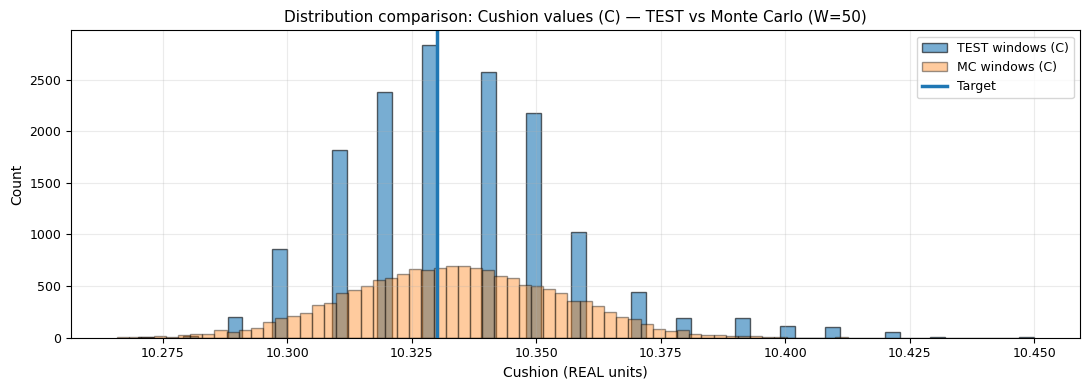

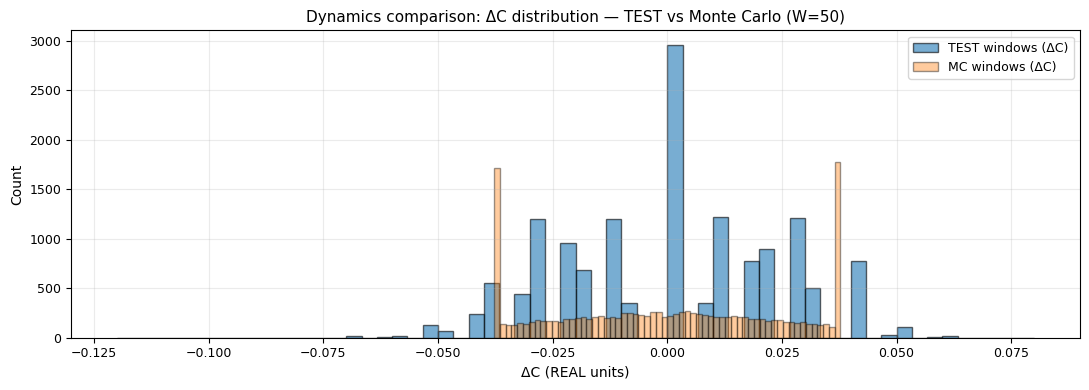

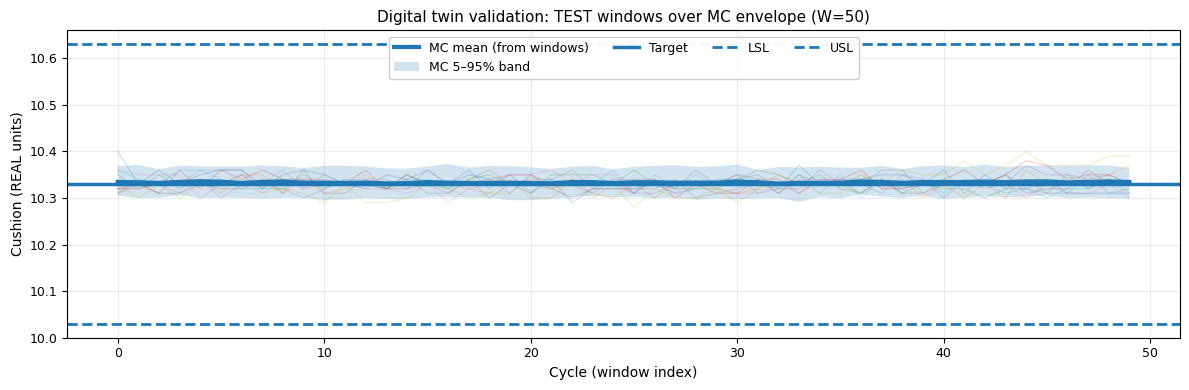


================ DOWNLOAD FIGURES ================


Button(button_style='success', description='Download Values Distribution PNG', icon='download', layout=Layout(…

Button(button_style='success', description='Download Dynamics Distribution PNG', icon='download', layout=Layou…

Button(button_style='success', description='Download Envelope Validation PNG', icon='download', layout=Layout(…

In [ ]:
# Compare stationary simulations with sampled fifty-cycle test windows.
# Report level/increment distributions and envelope coverage. These unconditional
# checks do not establish conditional calibration or joint trajectory validity.

import os
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
try:
    from google.colab import files  # Colab only; harmless elsewhere
except Exception:
    files = None

try:
    from scipy.stats import ks_2samp
    HAS_SCIPY = True
except Exception:
    HAS_SCIPY = False

req = ["runs", "df_test_raw", "TARGET_COL", "LSL", "USL", "TARGET_CUSHION"]
missing = [r for r in req if r not in globals()]
if missing:
    raise RuntimeError(f"Missing required objects: {missing}")

output_dir = "digital_twin_validation_outputs"
os.makedirs(output_dir, exist_ok=True)

def make_download_button(file_path, button_label):
    button = widgets.Button(
        description=button_label,
        button_style="success",
        icon="download",
        layout=widgets.Layout(width="320px")
    )

    def on_click(b):
        if files:
            files.download(file_path)

    button.on_click(on_click)
    return button

W = 50
N_WINDOWS = 300
RANDOM_SEED = 7
rng = np.random.default_rng(RANDOM_SEED)

runs_arr = np.asarray(runs, dtype=float)
n_runs, mc_len = runs_arr.shape
if mc_len < W:
    raise RuntimeError(f"MC has {mc_len} cycles after burn-in. Need W={W}. "
                       f"Set SIM_CYCLES = BURN_IN + {W} (e.g., 80 if burn-in=30).")

test_series = df_test_raw[TARGET_COL].astype(float).dropna().values
T = len(test_series)
if T < W:
    raise RuntimeError(f"TEST length {T} < W={W}.")

def cohen_d(a, b):
    a = np.asarray(a, float)
    b = np.asarray(b, float)
    na, nb = len(a), len(b)
    sa, sb = np.var(a, ddof=1), np.var(b, ddof=1)
    sp = np.sqrt(((na - 1) * sa + (nb - 1) * sb) / (na + nb - 2 + 1e-12))
    return float((np.mean(a) - np.mean(b)) / (sp + 1e-12))

def summarize(arr):
    arr = np.asarray(arr, float)
    return (
        float(np.mean(arr)),
        float(np.std(arr, ddof=1)),
        float(np.percentile(arr, 5)),
        float(np.percentile(arr, 95))
    )


mc_idx = rng.integers(0, n_runs, size=N_WINDOWS)
mc_windows = runs_arr[mc_idx, :W]
mc_vals = mc_windows.reshape(-1)
mc_deltas = np.diff(mc_windows, axis=1).reshape(-1)

max_start = T - W
starts = rng.integers(0, max_start + 1, size=N_WINDOWS)
test_windows = np.stack([test_series[s:s+W] for s in starts], axis=0)
test_vals = test_windows.reshape(-1)
test_deltas = np.diff(test_windows, axis=1).reshape(-1)

mc_mu, mc_sig, mc_p5, mc_p95 = summarize(mc_vals)
ts_mu, ts_sig, ts_p5, ts_p95 = summarize(test_vals)

d_mu = cohen_d(mc_vals, test_vals)

mc_dmu, mc_dsig, mc_dp5, mc_dp95 = summarize(mc_deltas)
ts_dmu, ts_dsig, ts_dp5, ts_dp95 = summarize(test_deltas)

d_deltas = cohen_d(mc_deltas, test_deltas)

if HAS_SCIPY:
    ks_vals = ks_2samp(mc_vals, test_vals)
    ks_dlt  = ks_2samp(mc_deltas, test_deltas)
    ks_vals_stat, ks_vals_p = float(ks_vals.statistic), float(ks_vals.pvalue)
    ks_dlt_stat, ks_dlt_p   = float(ks_dlt.statistic), float(ks_dlt.pvalue)
else:
    ks_vals_stat = ks_vals_p = np.nan
    ks_dlt_stat  = ks_dlt_p  = np.nan

mc_q05 = np.percentile(mc_windows, 5, axis=0)
mc_q95 = np.percentile(mc_windows, 95, axis=0)
mc_mean_path = np.mean(mc_windows, axis=0)

inside = (test_windows >= mc_q05[None, :]) & (test_windows <= mc_q95[None, :])
coverage = float(np.mean(inside))
full_covered = float(np.mean(np.all(inside, axis=1)))

print("\n================ DIGITAL TWIN COMPATIBILITY (W=50) ================")
print("Cushion values (C):")
print(f"  MC:   mu={mc_mu:.4f}, sigma={mc_sig:.4f}, P5={mc_p5:.4f}, P95={mc_p95:.4f}")
print(f"  TEST: mu={ts_mu:.4f}, sigma={ts_sig:.4f}, P5={ts_p5:.4f}, P95={ts_p95:.4f}")
print(f"  Effect size (Cohen's d) on C values: {d_mu:.3f}  (|d|<0.2 small, <0.5 medium)")

if HAS_SCIPY:
    print(f"  KS test on C values: D={ks_vals_stat:.3f}, p={ks_vals_p:.4f}")

print("\nDynamics (ΔC):")
print(f"  MC:   mu={mc_dmu:.5f}, sigma={mc_dsig:.5f}, P5={mc_dp5:.5f}, P95={mc_dp95:.5f}")
print(f"  TEST: mu={ts_dmu:.5f}, sigma={ts_dsig:.5f}, P5={ts_dp5:.5f}, P95={ts_dp95:.5f}")
print(f"  Effect size (Cohen's d) on ΔC: {d_deltas:.3f}")

if HAS_SCIPY:
    print(f"  KS test on ΔC: D={ks_dlt_stat:.3f}, p={ks_dlt_p:.4f}")

print("\nEnvelope coverage (MC 5–95% band vs TEST windows):")
print(f"  Point-wise coverage: {coverage*100:.2f}%  (target ~90% if well calibrated)")
print(f"  Window fully-covered: {full_covered*100:.2f}% (strict criterion)")

print("\nPractical interpretation:")
print("  - If mean/std and ΔC std are close, and coverage ≈ 90%, the simulation is consistent with TEST regime.")
print("  - Large gaps in ΔC sigma or low coverage indicate mismatch in dynamics/noise assumptions.")
print("===================================================================\n")

fig1, ax1 = plt.subplots(figsize=(11, 4))
ax1.hist(test_vals, bins=60, alpha=0.6, edgecolor="black", label="TEST windows (C)")
ax1.hist(mc_vals,   bins=60, alpha=0.4, edgecolor="black", label="MC windows (C)")
ax1.axvline(TARGET_CUSHION, linewidth=2.5, label="Target")
ax1.set_title("Distribution comparison: Cushion values (C) — TEST vs Monte Carlo (W=50)")
ax1.set_xlabel("Cushion (REAL units)")
ax1.set_ylabel("Count")
ax1.grid(True, alpha=0.25)
ax1.legend()
plt.tight_layout()
plt.show()

fig1_path = os.path.join(output_dir, "dt_validation_distribution_values.png")
fig1.savefig(fig1_path, dpi=600, bbox_inches="tight")
plt.close(fig1)

fig2, ax2 = plt.subplots(figsize=(11, 4))
ax2.hist(test_deltas, bins=60, alpha=0.6, edgecolor="black", label="TEST windows (ΔC)")
ax2.hist(mc_deltas,   bins=60, alpha=0.4, edgecolor="black", label="MC windows (ΔC)")
ax2.set_title("Dynamics comparison: ΔC distribution — TEST vs Monte Carlo (W=50)")
ax2.set_xlabel("ΔC (REAL units)")
ax2.set_ylabel("Count")
ax2.grid(True, alpha=0.25)
ax2.legend()
plt.tight_layout()
plt.show()

fig2_path = os.path.join(output_dir, "dt_validation_distribution_deltas.png")
fig2.savefig(fig2_path, dpi=600, bbox_inches="tight")
plt.close(fig2)

fig3, ax3 = plt.subplots(figsize=(12, 4))
x = np.arange(W)

for i in range(min(10, N_WINDOWS)):
    ax3.plot(test_windows[i], alpha=0.20, linewidth=1)

ax3.plot(mc_mean_path, linewidth=3, label="MC mean (from windows)")
ax3.fill_between(x, mc_q05, mc_q95, alpha=0.20, label="MC 5–95% band")
ax3.axhline(TARGET_CUSHION, linewidth=2.5, label="Target")
ax3.axhline(LSL, linestyle="--", linewidth=2.0, label="LSL")
ax3.axhline(USL, linestyle="--", linewidth=2.0, label="USL")

ax3.set_title(f"Digital twin validation: TEST windows over MC envelope (W={W})")
ax3.set_xlabel("Cycle (window index)")
ax3.set_ylabel("Cushion (REAL units)")
ax3.grid(True, alpha=0.25)
ax3.legend(loc="upper center", ncol=4, framealpha=0.95)
plt.tight_layout()
plt.show()

fig3_path = os.path.join(output_dir, "dt_validation_envelope.png")
fig3.savefig(fig3_path, dpi=600, bbox_inches="tight")
plt.close(fig3)

print("\n================ DOWNLOAD FIGURES ================")
display(make_download_button(fig1_path, "Download Values Distribution PNG"))
display(make_download_button(fig2_path, "Download Dynamics Distribution PNG"))
display(make_download_button(fig3_path, "Download Envelope Validation PNG"))

generator_validation_summary = {
    "mc_mu": mc_mu, "mc_sigma": mc_sig, "test_mu": ts_mu, "test_sigma": ts_sig,
    "cohen_d_values": d_mu, "ks_D_values": ks_vals_stat, "ks_p_values": ks_vals_p,
    "mc_dsigma": mc_dsig, "test_dsigma": ts_dsig,
    "cohen_d_deltas": d_deltas, "ks_D_deltas": ks_dlt_stat, "ks_p_deltas": ks_dlt_p,
    "pointwise_envelope_coverage": float(np.mean(inside)),
}


### Stationary distribution comparisons

Report pooled bootstrap intervals, effect sizes and overlap on the acquisition grid. The bootstrap does not preserve serial dependence, and interval overlap does not demonstrate equivalence.


In [ ]:
# Compare stationary and measured summaries using bootstrap intervals, effect
# sizes and distributional overlap. The bootstrap resamples pooled individual
# values and does not preserve serial or within-run dependence. Interval overlap
# is not an equivalence test. Compute discrete overlap on the 0.01 mm grid.

import numpy as np
import pandas as pd

_real = df_test_raw[TARGET_COL].astype(float).values
_sim  = runs.reshape(-1).astype(float)          # unfiltered stationary MC samples

def _bootstrap_ci(samples, stat_fn, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    vals = np.empty(n_boot)
    n = len(samples)
    for b in range(n_boot):
        vals[b] = stat_fn(samples[rng.integers(0, n, n)])
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return float(lo), float(hi)

_stats = {
    "mean":  lambda x: float(np.mean(x)),
    "sigma": lambda x: float(np.std(x, ddof=1)),
    "Cp":    lambda x: compute_cp_cpk(x, LSL, USL)["Cp"],
    "Cpk":   lambda x: compute_cp_cpk(x, LSL, USL)["Cpk"],
}
rows = []
for _name, _fn in _stats.items():
    r_pt, s_pt = _fn(_real), _fn(_sim)
    r_lo, r_hi = _bootstrap_ci(_real, _fn)
    s_lo, s_hi = _bootstrap_ci(_sim, _fn)
    overlap = not (r_hi < s_lo or s_hi < r_lo)
    rows.append({
        "statistic": _name,
        "real": round(r_pt, 4), "real_95CI": f"[{r_lo:.4f}, {r_hi:.4f}]",
        "simulated": round(s_pt, 4), "sim_95CI": f"[{s_lo:.4f}, {s_hi:.4f}]",
        "CIs_overlap": overlap,
    })
capability_ci_df = pd.DataFrame(rows)
print("Bootstrap 95% confidence intervals — real vs simulated process:")
display(capability_ci_df)
capability_ci_df.to_csv("capability_confidence_intervals.csv", index=False)

def _cohens_d(a, b):
    na, nb_ = len(a), len(b)
    sp = np.sqrt(((na - 1) * np.var(a, ddof=1) + (nb_ - 1) * np.var(b, ddof=1)) / (na + nb_ - 2))
    return float((np.mean(a) - np.mean(b)) / sp) if sp > 0 else 0.0

def _interpret_d(d):
    ad = abs(d)
    return ("negligible" if ad < 0.2 else "small" if ad < 0.5
            else "medium" if ad < 0.8 else "large")

d_val = _cohens_d(_real, _sim)

ACQ_QUANTUM = 0.01     # mm, native resolution of the OPC/controller chain


def _infer_quantum(x, candidates=(0.01, 0.001, 0.0001)):
    """Return the coarsest candidate grid the sample is consistent with."""
    for q in candidates:
        k = np.asarray(x) / q
        if np.allclose(k, np.round(k), atol=1e-6):
            return q
    return None


def overlap_coef_quantized(a, b, q=ACQ_QUANTUM):
    """Discrete overlapping coefficient on the acquisition grid."""
    ka = np.round(np.asarray(a, dtype=float) / q).astype(np.int64)
    kb = np.round(np.asarray(b, dtype=float) / q).astype(np.int64)
    keys = np.union1d(np.unique(ka), np.unique(kb))
    ca = np.bincount(ka - keys.min(), minlength=keys.max() - keys.min() + 1)
    cb = np.bincount(kb - keys.min(), minlength=keys.max() - keys.min() + 1)
    pa, pb = ca / ca.sum(), cb / cb.sum()
    return float(np.sum(np.minimum(pa, pb)))


_q_real = _infer_quantum(_real)
ovl = overlap_coef_quantized(_real, _sim)

_ovl_gauss = float("nan")
if HAS_SCIPY:
    from scipy.stats import norm as _norm
    from scipy.integrate import quad as _quad
    _m1, _s1 = float(np.mean(_real)), float(np.std(_real, ddof=1))
    _m2, _s2 = float(np.mean(_sim)), float(np.std(_sim, ddof=1))
    _ovl_gauss, _ = _quad(lambda x: min(_norm.pdf(x, _m1, _s1), _norm.pdf(x, _m2, _s2)),
                          _m1 - 8 * _s1, _m1 + 8 * _s1, limit=400)
_ovl_agree = bool(np.isfinite(_ovl_gauss) and abs(ovl - _ovl_gauss) < 0.05)

print("\nOverlap coefficient — computed at the acquisition resolution:")
print(f"  detected real-data grid : "
      f"{('%.4f mm' % _q_real) if _q_real else 'not on a regular grid'}")
print(f"  distinct real values    : {len(np.unique(_real))}  "
      f"(range {_real.min():.4f} to {_real.max():.4f})")
print(f"  grid used               : {ACQ_QUANTUM:.4f} mm")
print(f"  OVL (discrete, on grid) : {ovl:.3f}")
print(f"  OVL (Gaussian check)    : {_ovl_gauss:.3f}    agree(<0.05): {_ovl_agree}")
if not _ovl_agree:
    print("  NOTE: the two estimates disagree; the discrepancy is reported rather than resolved (")
    print("           discrepancy is understood.")

effect_df = pd.DataFrame([
    {"metric": "Cohen's d (real vs simulated cushion)", "value": round(d_val, 3),
     "interpretation": _interpret_d(d_val)},
    {"metric": "Overlap coefficient", "value": round(ovl, 3),
     "interpretation": f"{ovl*100:.1f}% shared probability mass"},
])
print("\nEffect size and distributional overlap:")
display(effect_df)
effect_df.to_csv("effect_size_overlap.csv", index=False)
print(f"Reading: with n = {len(_real):,} real and {len(_sim):,} simulated samples, any KS or "
      f"t-test returns p < 0.0001 from sample size alone. The negligible effect size "
      f"(d = {d_val:.3f}) and the {ovl*100:.1f}% distributional overlap show the two processes "
      f"are practically equivalent in LEVEL, while the sigma confidence intervals - which do "
      f"not overlap - locate the real difference where it belongs: in DISPERSION.")

overlap_summary = {
    "ovl": ovl, "ovl_gaussian": _ovl_gauss, "methods_agree": _ovl_agree,
    "cohens_d": float(d_val), "acq_quantum": ACQ_QUANTUM,
    "detected_real_grid": _q_real,
    "n_distinct_real_values": int(len(np.unique(_real))),
    "estimator": "discrete OVL on the 0.01 mm acquisition grid",
    "note": ("a histogram estimator is bin-width dependent because the real "
             "data is quantized at 0.01 mm while the simulation is continuous"),
}

Bootstrap 95% confidence intervals — real vs simulated process:


,statistic,real,real_95CI,simulated,sim_95CI,CIs_overlap
0,mean,10.3357,"[10.3349, 10.3364]",10.3337,"[10.3335, 10.3339]",False
1,sigma,0.0236,"[0.0229, 0.0242]",0.0207,"[0.0206, 0.0208]",False
2,Cp,4.2460,"[4.1263, 4.3715]",4.8339,"[4.8064, 4.8624]",False
3,Cpk,4.1658,"[4.0426, 4.2936]",4.7740,"[4.7472, 4.8028]",False



Overlap coefficient — computed at the acquisition resolution:
  detected real-data grid : 0.0100 mm
  distinct real values    : 18  (range 10.2700 to 10.4500)
  grid used               : 0.0100 mm
  OVL (discrete, on grid) : 0.942
  OVL (Gaussian check)    : 0.930    agree(<0.05): True

Effect size and distributional overlap:


,metric,value,interpretation
0,Cohen's d (real vs simulated cushion),0.093,negligible
1,Overlap coefficient,0.942,94.2% shared probability mass


Reading: with n = 3,867 real and 50,000 simulated samples, any KS or t-test returns p < 0.0001 from sample size alone. The negligible effect size (d = 0.093) and the 94.2% distributional overlap show the two processes are practically equivalent in LEVEL, while the sigma confidence intervals - which do not overlap - locate the real difference where it belongs: in DISPERSION.


## Conditional forecasts and cycle-level coverage

Issue forecasts from measured history at multiple origins. Compare future cushion values with their cycle-level bands; assess capability-index interval coverage separately.


In [ ]:
# Forecast from the measured history immediately before positional index t0.
# Freeze the preceding local recipe and estimate feature noise from that window.
# There is no burn-in or run selection. Slow-state initialisation is configurable;
# validation selects it later. Marginal range checks do not establish joint
# support for altered inputs, especially the correlated pressure channels.

import numpy as np
import torch

req = ["model", "device", "x_scaler", "delta_scaler", "FEATURES", "RECIPE_FEATURES",
       "cush_in_idx", "SEQ_LEN", "TARGET_COL", "df_test_raw",
       "residual_pool", "sigma_res", "bias_res", "delta_clamp_abs",
       "AR1_RHO", "NOISE_SCALE", "feature_sigma", "LSL", "USL", "compute_cp_cpk"]
missing = [r for r in req if r not in globals()]
if missing:
    raise RuntimeError(f"Missing required objects for on-demand mode: {missing} "
                       f"(run the preceding phases first; residuals must be validation-calibrated)")

OD_SIM_CYCLES   = 50      # forecast horizon (cycles) after forecast request
OD_RECIPE_WIN   = 200     # real cycles used to compute the frozen recipe
OD_USE_AR1      = True
OD_USE_DELTA_CLAMP = True # disclosed methodological choice (stability); no plausibility filtering in on-demand mode
OD_MIN_RECIPE_WIN  = 50   # minimum acceptable recipe window

_x_center = np.asarray(getattr(x_scaler, "center_", getattr(x_scaler, "mean_", None)), dtype=np.float32)
_x_scale_v = np.asarray(x_scaler.scale_, dtype=np.float32)
_d_center = float(getattr(delta_scaler, "center_", getattr(delta_scaler, "mean_", [0.0]))[0])
_d_scale_v = float(delta_scaler.scale_[0])

def _scale_x(x_real):
    return ((x_real - _x_center) / _x_scale_v).astype(np.float32)

def _delta_to_real(d_scaled):
    return d_scaled * _d_scale_v + _d_center

def valid_forecast_anchors(df_raw, seq_len, horizon, seg_col="segment"):
    """Anchor t0 (positional index in df_raw) is valid if the seq_len rows
    before t0 AND the horizon rows from t0 are all within the same segment."""
    seg = df_raw[seg_col].values
    n = len(df_raw)
    anchors = []
    for t0 in range(seq_len, n - horizon + 1):
        if seg[t0 - seq_len] == seg[t0 + horizon - 1] == seg[t0]:
            anchors.append(t0)
    return np.array(anchors, dtype=int)

def on_demand_forecast(t0, n_sims=1000, sim_cycles=OD_SIM_CYCLES,
                         recipe_window=OD_RECIPE_WIN, recipe_override=None,
                         df_raw=None, seed=None, verbose=False, slow_sigma=None):
    """Conditional Monte Carlo from real state at positional index t0 of df_raw.

    recipe_override: dict {feature: real_value} applied ON TOP of the frozen
    recipe (for what-if scenarios). Values outside the training range trigger
    a warning (extrapolation risk).
    Returns dict with traj (n_sims, sim_cycles), recipe, feature sigmas, warnings.
    """
    if df_raw is None:
        df_raw = df_test_raw
    if slow_sigma is not None:
        _slow_sig = float(slow_sigma)
    elif 'SLOW_SIGMA_BTN' in globals():
        _slow_sig = float(SLOW_SIGMA_BTN)
    else:
        _slow_sig = float(SLOW_SIGMA) if 'SLOW_SIGMA' in globals() else 0.0
    _slow_on = ('USE_SLOW_NOISE' in globals()) and USE_SLOW_NOISE and (_slow_sig > 0)
    if seed is not None:
        rng = np.random.default_rng(seed)
    else:
        rng = np.random.default_rng()

    n_feat = len(FEATURES)
    warnings = []

    win = df_raw.iloc[t0 - SEQ_LEN:t0]
    if win["segment"].nunique() != 1:
        raise ValueError(f"Initial window at t0={t0} crosses a segment boundary")
    seq_real0 = win[FEATURES].values.astype(np.float32)          # real features incl. real cushion
    C0_real = float(win[TARGET_COL].values[-1])                  # last real cushion = state

    lo = max(0, t0 - recipe_window)
    ctx = df_raw.iloc[lo:t0]
    if len(ctx) < OD_MIN_RECIPE_WIN:
        warnings.append(f"recipe window only {len(ctx)} cycles (< {OD_MIN_RECIPE_WIN})")
    recipe = {f: float(ctx[f].astype(float).mean()) for f in RECIPE_FEATURES}

    if recipe_override:
        for f, v in recipe_override.items():
            if f not in recipe:
                raise KeyError(f"{f} is not a recipe feature")
            recipe[f] = float(v)
        for f, v in recipe.items():
            tr = df_train_raw[f].astype(float)
            q_lo, q_hi = float(tr.quantile(0.01)), float(tr.quantile(0.99))
            if not (q_lo <= v <= q_hi):
                warnings.append(f"EXTRAPOLATION: {f}={v:.4f} outside train 1-99% range "
                                f"[{q_lo:.4f}, {q_hi:.4f}] — forecast unreliable")

    sig = {}
    for f in RECIPE_FEATURES:
        s_local = float(ctx[f].astype(float).std(ddof=1)) if len(ctx) > 10 else np.nan
        sig[f] = s_local if np.isfinite(s_local) and s_local > 0 else float(feature_sigma.get(f, 0.0))
    sigma_vec = np.array([sig.get(f, 0.0) for f in FEATURES], dtype=np.float32)
    sigma_vec[cush_in_idx] = 0.0
    sigma_vec *= float(NOISE_SCALE)

    base_row = np.zeros((n_feat,), dtype=np.float32)
    for i, f in enumerate(FEATURES):
        base_row[i] = recipe.get(f, float(df_train_raw[f].astype(float).mean())
                                 if f in df_train_raw.columns else 0.0)
    base_row[cush_in_idx] = C0_real  # placeholder, overwritten each step

    seq_scaled = torch.from_numpy(
        np.tile(_scale_x(seq_real0), (n_sims, 1, 1))
    ).to(device=device, dtype=torch.float32)

    C_prev = torch.full((n_sims,), C0_real, device=device, dtype=torch.float32)
    traj = np.empty((n_sims, sim_cycles), dtype=np.float32)

    _slow_init_mode = str(globals().get('OD_SLOW_INIT', 'observed'))
    if _slow_on and _slow_init_mode == 'observed':
        _c_recent = df_raw.iloc[max(0, t0-15):t0][TARGET_COL].astype(float).mean()
        _c_long   = ctx[TARGET_COL].astype(float).mean()
        _b = 3.0 * (SLOW_SIGMA_TARGET if 'SLOW_SIGMA_TARGET' in globals() else _slow_sig)
        s0 = float(np.clip(_c_recent - _c_long, -_b, _b))
        s_prev = np.full((n_sims,), s0, dtype=np.float32)
    else:
        s_prev = np.zeros((n_sims,), dtype=np.float32)
    base_batch = np.tile(base_row, (n_sims, 1)).astype(np.float32)
    e_prev = np.zeros((n_sims,), dtype=np.float32)
    rho = float(AR1_RHO)

    model.eval()
    with torch.no_grad():
        for k in range(sim_cycles):
            out = model(seq_scaled)
            if out.ndim == 2:
                out = out[:, 0]
            d_r = _delta_to_real(out.detach().cpu().numpy().astype(np.float32))
            d_r += float(bias_res)

            e = rng.choice(residual_pool, size=n_sims, replace=True).astype(np.float32)
            e *= float(NOISE_SCALE)
            if OD_USE_AR1:
                e = rho * e_prev + np.sqrt(max(1e-8, 1.0 - rho * rho)) * e
                e_prev = e
            d_r += e

            if _slow_on:
                s_new = SLOW_PHI * s_prev + _slow_sig * np.sqrt(1.0 - SLOW_PHI**2) * \
                        rng.normal(0.0, 1.0, size=n_sims).astype(np.float32)
                d_r += (s_new - s_prev)
                s_prev = s_new

            if OD_USE_DELTA_CLAMP:
                cabs = float(delta_clamp_abs) * float(NOISE_SCALE)
                d_r = np.clip(d_r, -cabs, +cabs)

            C_next = C_prev + torch.from_numpy(d_r).to(device=device, dtype=torch.float32)
            traj[:, k] = C_next.detach().cpu().numpy()

            nxt = base_batch.copy()
            nxt += rng.normal(0.0, sigma_vec, size=(n_sims, n_feat)).astype(np.float32)
            nxt[:, cush_in_idx] = traj[:, k]
            nxt_scaled = torch.from_numpy(_scale_x(nxt)).to(device=device, dtype=torch.float32)
            seq_scaled[:, :-1, :] = seq_scaled[:, 1:, :]
            seq_scaled[:, -1, :] = nxt_scaled
            C_prev = C_next

    if verbose:
        for w in warnings:
            print("WARNING:", w)
    return {"traj": traj, "t0": int(t0), "C0": C0_real, "recipe": recipe,
            "feature_sigma_local": sig, "warnings": warnings}

def per_run_cpk(traj, lsl, usl):
    """Cpk of each simulated run (n=sim_cycles per run) → distribution over runs."""
    mu = traj.mean(axis=1)
    sd = traj.std(axis=1, ddof=1)
    sd = np.maximum(sd, 1e-12)
    return np.minimum((usl - mu) / (3 * sd), (mu - lsl) / (3 * sd))

anchors_all = valid_forecast_anchors(df_test_raw, SEQ_LEN, OD_SIM_CYCLES)
print(f"[on-demand mode] ready — {len(anchors_all)} valid anchors in the test set "
      f"(SEQ_LEN={SEQ_LEN} history + {OD_SIM_CYCLES} future within one segment)")


SLOW_SIGMA_BTN = float(SLOW_SIGMA) if 'SLOW_SIGMA' in globals() else 0.0
OD_SLOW_INIT = 'observed'


[on-demand mode] ready — 3719 valid anchors in the test set (SEQ_LEN=25 history + 50 future within one segment)


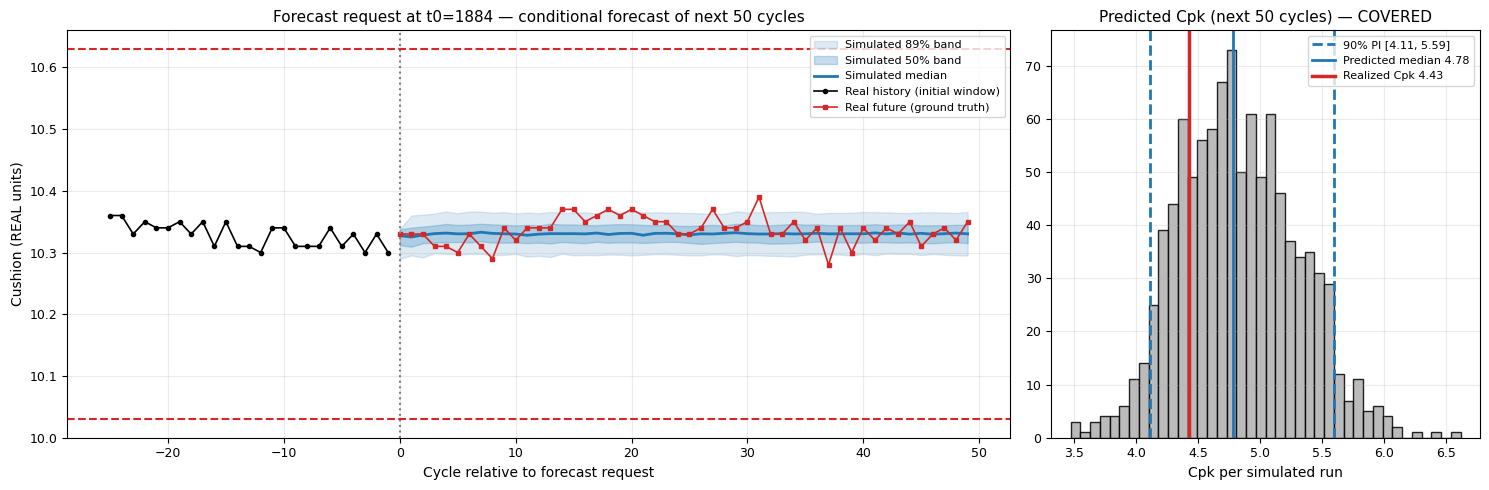

Anchor t0=1884 | predicted Cpk 90% PI = [4.112, 5.594] (median 4.783) | realized Cpk = 4.426 | inside: True


In [ ]:
# Show a single-anchor forecast and its subsequent realisation.
# The capability distribution is model-based. Cycle-level coverage does not
# validate coverage of Cp/Cpk intervals.

import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("forecast_outputs", exist_ok=True)

DEMO_SEED = 123
rng_demo = np.random.default_rng(DEMO_SEED)
demo_t0 = int(anchors_all[len(anchors_all) // 2])   # mid-test anchor (change freely)

res = on_demand_forecast(demo_t0, n_sims=1000, seed=DEMO_SEED, verbose=True)
traj = res["traj"]

hist_n = SEQ_LEN
real_hist = df_test_raw.iloc[demo_t0 - hist_n:demo_t0][TARGET_COL].astype(float).values
real_fut  = df_test_raw.iloc[demo_t0:demo_t0 + OD_SIM_CYCLES][TARGET_COL].astype(float).values

cpk_runs = per_run_cpk(traj, LSL, USL)
q05, q50, q95 = np.quantile(cpk_runs, [0.05, 0.50, 0.95])
real_cpk = compute_cp_cpk(real_fut, LSL, USL)["Cpk"]
inside = q05 <= real_cpk <= q95

x_h = np.arange(-hist_n, 0)
x_f = np.arange(0, OD_SIM_CYCLES)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2.2, 1]})

for q_lo, q_hi, a in [(0.05, 0.95, 0.15), (0.25, 0.75, 0.25)]:
    lo = np.quantile(traj, q_lo, axis=0)
    hi = np.quantile(traj, q_hi, axis=0)
    ax1.fill_between(x_f, lo, hi, color="#1F77B4", alpha=a,
                     label=f"Simulated {int((q_hi-q_lo)*100)}% band")
ax1.plot(x_f, np.median(traj, axis=0), color="#1F77B4", lw=2, label="Simulated median")
ax1.plot(x_h, real_hist, "o-", color="black", ms=3, lw=1.2, label="Real history (initial window)")
ax1.plot(x_f, real_fut, "s-", color="#D62728", ms=3, lw=1.2, label="Real future (ground truth)")
ax1.axvline(0, color="gray", ls=":", lw=1.5)
ax1.axhline(LSL, color="#D62728", ls="--", lw=1.5)
ax1.axhline(USL, color="#D62728", ls="--", lw=1.5)
ax1.set_title(f"Forecast request at t0={demo_t0} — conditional forecast of next {OD_SIM_CYCLES} cycles")
ax1.set_xlabel("Cycle relative to forecast request")
ax1.set_ylabel("Cushion (REAL units)")
ax1.legend(loc="best", fontsize=8)
ax1.grid(alpha=0.25)

ax2.hist(cpk_runs, bins=40, color="#B0B0B0", edgecolor="black", alpha=0.85)
ax2.axvline(q05, color="#1F77B4", ls="--", lw=2, label=f"90% PI [{q05:.2f}, {q95:.2f}]")
ax2.axvline(q95, color="#1F77B4", ls="--", lw=2)
ax2.axvline(q50, color="#1F77B4", ls="-", lw=2, label=f"Predicted median {q50:.2f}")
ax2.axvline(real_cpk, color="#D62728", ls="-", lw=2.5, label=f"Realized Cpk {real_cpk:.2f}")
ax2.set_title(f"Predicted Cpk (next {OD_SIM_CYCLES} cycles) — "
              f"{'COVERED' if inside else 'NOT covered'}")
ax2.set_xlabel("Cpk per simulated run")
ax2.legend(fontsize=8)
ax2.grid(alpha=0.25)

plt.tight_layout()
fig.savefig("forecast_outputs/single_anchor_demo.png", dpi=600, bbox_inches="tight")
plt.show()

print(f"Anchor t0={demo_t0} | predicted Cpk 90% PI = [{q05:.3f}, {q95:.3f}] "
      f"(median {q50:.3f}) | realized Cpk = {real_cpk:.3f} | inside: {inside}")


  anchor 10/100 done
  anchor 20/100 done
  anchor 30/100 done
  anchor 40/100 done
  anchor 50/100 done
  anchor 60/100 done
  anchor 70/100 done
  anchor 80/100 done
  anchor 90/100 done
  anchor 100/100 done
=========== WALK-FORWARD CYCLE-BY-CYCLE VALIDATION ===========
Anchors: 100 | sims/anchor: 1000 | horizon: 50 cycles
CYCLE-BY-CYCLE COVERAGE (nominal 90%): 87.2%  (Wilson 95% CI: [86.3%, 88.1%])
Mean |mu error|:  0.0097
Mean sigma bias:  +0.0032  (+21.4% relative)
Nominal level: 90%   |   Wilson 95% CI: [86.3%, 88.1%]
>>> Coverage significantly BELOW nominal (nominal outside the 95% CI): MISCALIBRATED by -2.8 points.
    The calibration diagnostic below decomposes this discrepancy.


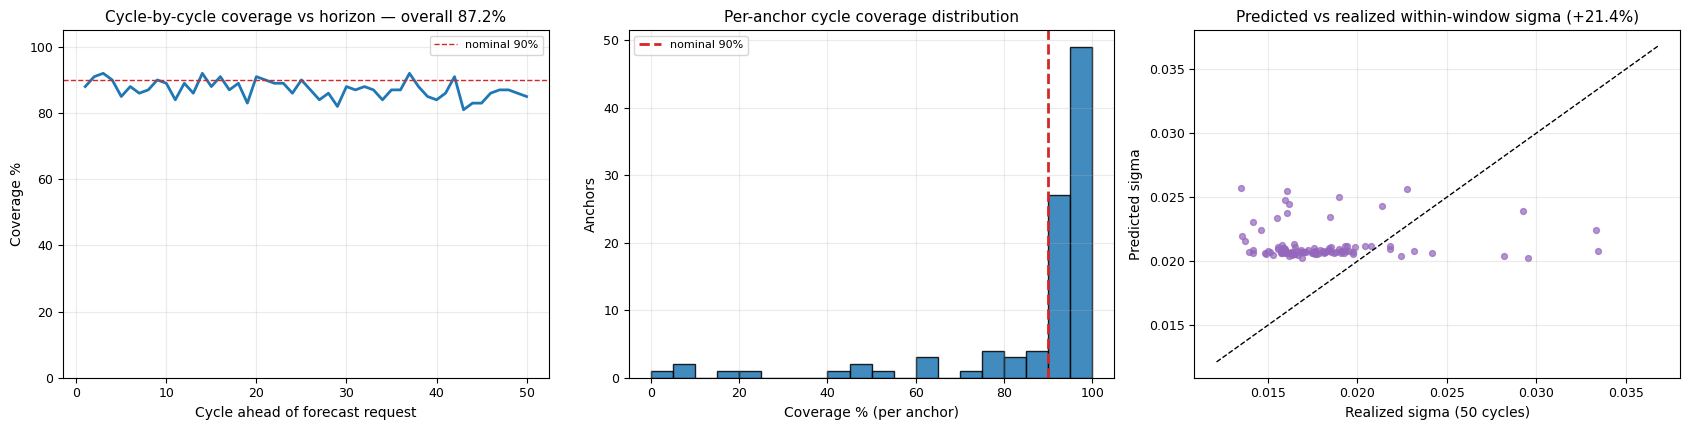

In [ ]:
# Evaluate cycle-level 5-95% bands across fixed-stride test origins.
# The indicators are dependent within and between overlapping origins.
# Wilson bounds are independence-based descriptive approximations, not valid
# dependence-adjusted significance tests. Cp/Cpk interval coverage is not tested.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("forecast_outputs", exist_ok=True)

WF_N_ANCHORS = 100
WF_N_SIMS    = 1000     # reduce to 200 for a quick dry run
WF_SEED      = 2026
BAND_LO, BAND_HI = 0.05, 0.95   # 90% nominal prediction band

if len(anchors_all) < WF_N_ANCHORS:
    print(f"Only {len(anchors_all)} valid anchors available; using all of them.")
    wf_anchors = anchors_all
else:
    idx = np.linspace(0, len(anchors_all) - 1, WF_N_ANCHORS).round().astype(int)
    wf_anchors = anchors_all[np.unique(idx)]

records = []
per_cycle_hits = np.zeros(OD_SIM_CYCLES, dtype=float)
per_cycle_n = 0
for j, t0 in enumerate(wf_anchors):
    r = on_demand_forecast(int(t0), n_sims=WF_N_SIMS, seed=WF_SEED + j)
    traj = r["traj"]
    lo = np.quantile(traj, BAND_LO, axis=0)
    hi = np.quantile(traj, BAND_HI, axis=0)

    real_fut = df_test_raw.iloc[t0:t0 + OD_SIM_CYCLES][TARGET_COL].astype(float).values
    inside = (real_fut >= lo) & (real_fut <= hi)
    per_cycle_hits += inside.astype(float)
    per_cycle_n += 1

    real_st = compute_cp_cpk(real_fut, LSL, USL)
    records.append({
        "t0": int(t0),
        "cycle_coverage": float(inside.mean()),
        "pred_mu": float(traj.mean()), "real_mu": real_st["mu"],
        "pred_sigma": float(np.mean(traj.std(axis=1, ddof=1))), "real_sigma": real_st["sigma"],
    })
    if (j + 1) % 10 == 0:
        print(f"  anchor {j+1}/{len(wf_anchors)} done")

wf = pd.DataFrame(records)

total_cov = float(wf["cycle_coverage"].mean())
n_pts = len(wf) * OD_SIM_CYCLES
z = 1.96
den = 1 + z**2 / n_pts
ctr = (total_cov + z**2 / (2 * n_pts)) / den
hw = z * np.sqrt(total_cov * (1 - total_cov) / n_pts + z**2 / (4 * n_pts**2)) / den
cov_lo, cov_hi = ctr - hw, ctr + hw

mu_mae     = float(np.mean(np.abs(wf["pred_mu"] - wf["real_mu"])))
sigma_bias = float(np.mean(wf["pred_sigma"] - wf["real_sigma"]))
sigma_rel  = float(np.mean((wf["pred_sigma"] - wf["real_sigma"]) / wf["real_sigma"]) * 100)

print("=========== WALK-FORWARD CYCLE-BY-CYCLE VALIDATION ===========")
print(f"Anchors: {len(wf)} | sims/anchor: {WF_N_SIMS} | horizon: {OD_SIM_CYCLES} cycles")
print(f"CYCLE-BY-CYCLE COVERAGE (nominal 90%): {total_cov*100:.1f}%  "
      f"(Wilson 95% CI: [{cov_lo*100:.1f}%, {cov_hi*100:.1f}%])")
print(f"Mean |mu error|:  {mu_mae:.4f}")
print(f"Mean sigma bias:  {sigma_bias:+.4f}  ({sigma_rel:+.1f}% relative)")
print("==============================================================")
NOMINAL = 0.90
_inside_ci = (cov_lo <= NOMINAL <= cov_hi)
print(f"Nominal level: {NOMINAL*100:.0f}%   |   Wilson 95% CI: "
      f"[{cov_lo*100:.1f}%, {cov_hi*100:.1f}%]")
if _inside_ci:
    print(">>> Coverage statistically indistinguishable from nominal: CALIBRATED.")
else:
    _dir = "BELOW" if total_cov < NOMINAL else "ABOVE"
    print(f">>> Coverage significantly {_dir} nominal (nominal outside the 95% CI): "
          f"MISCALIBRATED by {(total_cov-NOMINAL)*100:+.1f} points.")
    print("    The calibration diagnostic below decomposes this discrepancy.")

wf.to_csv("forecast_outputs/walk_forward_cycle_coverage.csv", index=False)
validation_summary = {
    "n_anchors": int(len(wf)), "n_sims": int(WF_N_SIMS),
    "cycle_coverage": total_cov, "coverage_ci": (cov_lo, cov_hi),
    "mu_mae": mu_mae, "sigma_bias": sigma_bias, "sigma_rel_pct": sigma_rel,
}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
axes[0].plot(np.arange(1, OD_SIM_CYCLES + 1), per_cycle_hits / per_cycle_n * 100,
             color="#1F77B4", lw=2)
axes[0].axhline(90, color="#D62728", ls="--", lw=1, label="nominal 90%")
axes[0].set_ylim(0, 105)
axes[0].set_title(f"Cycle-by-cycle coverage vs horizon — overall {total_cov*100:.1f}%")
axes[0].set_xlabel("Cycle ahead of forecast request"); axes[0].set_ylabel("Coverage %")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.25)
axes[1].hist(wf["cycle_coverage"] * 100, bins=20, color="#1F77B4", edgecolor="black", alpha=0.85)
axes[1].axvline(90, color="#D62728", ls="--", lw=2, label="nominal 90%")
axes[1].set_title("Per-anchor cycle coverage distribution")
axes[1].set_xlabel("Coverage % (per anchor)"); axes[1].set_ylabel("Anchors")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.25)
axes[2].scatter(wf["real_sigma"], wf["pred_sigma"], s=18, alpha=0.7, color="#9467BD")
sl = [min(wf["real_sigma"].min(), wf["pred_sigma"].min()) * 0.9,
      max(wf["real_sigma"].max(), wf["pred_sigma"].max()) * 1.1]
axes[2].plot(sl, sl, "k--", lw=1)
axes[2].set_title(f"Predicted vs realized within-window sigma ({sigma_rel:+.1f}%)")
axes[2].set_xlabel("Realized sigma (50 cycles)"); axes[2].set_ylabel("Predicted sigma")
axes[2].grid(alpha=0.25)
plt.tight_layout()
fig.savefig("forecast_outputs/walk_forward_cycle_coverage.png", dpi=600, bbox_inches="tight")
plt.show()


### Location and dispersion diagnostics

Examine coverage by horizon, signed level error, raw and retrospectively recentred PIT ranks, and correlation with the initial-state deviation. These diagnostics suggest possible mechanisms rather than identify a unique cause.


Diagnostic on 60 evaluation anchors x 400 sims x 50 cycles
    anchor 10/60
    anchor 20/60
    anchor 30/60
    anchor 40/60
    anchor 50/60
    anchor 60/60

--- 1) COVERAGE AND LEVEL ERROR BY HORIZON ---
cycles  coverage %  signed level error
  1-10        90.5            -0.00060
 11-20        88.8             0.00036
 21-30        86.2            -0.00431
 31-40        85.3            -0.00398
 41-50        86.3            -0.00040

--- 2) DECOMPOSITION ---
  coverage as-is                 : 87.4%
  coverage after removing the
  per-anchor level error         : 93.7%   <-- dispersion alone
  dispersion ratio pred/real     : 1.140  (+14.0%)
  |level error| mean             : 0.0096  = 0.51 x real within-window sigma (0.0187)
  level error signed mean        : -0.0018  (0 = no global bias)
  corr(level error , s0)         : -0.767  (mean reversion of the AR(1) slow state is the mechanism)

--- 3) PIT SPREAD (uniform target 0.2887) ---
  raw PIT std     : 0.2985
  centred PIT std :

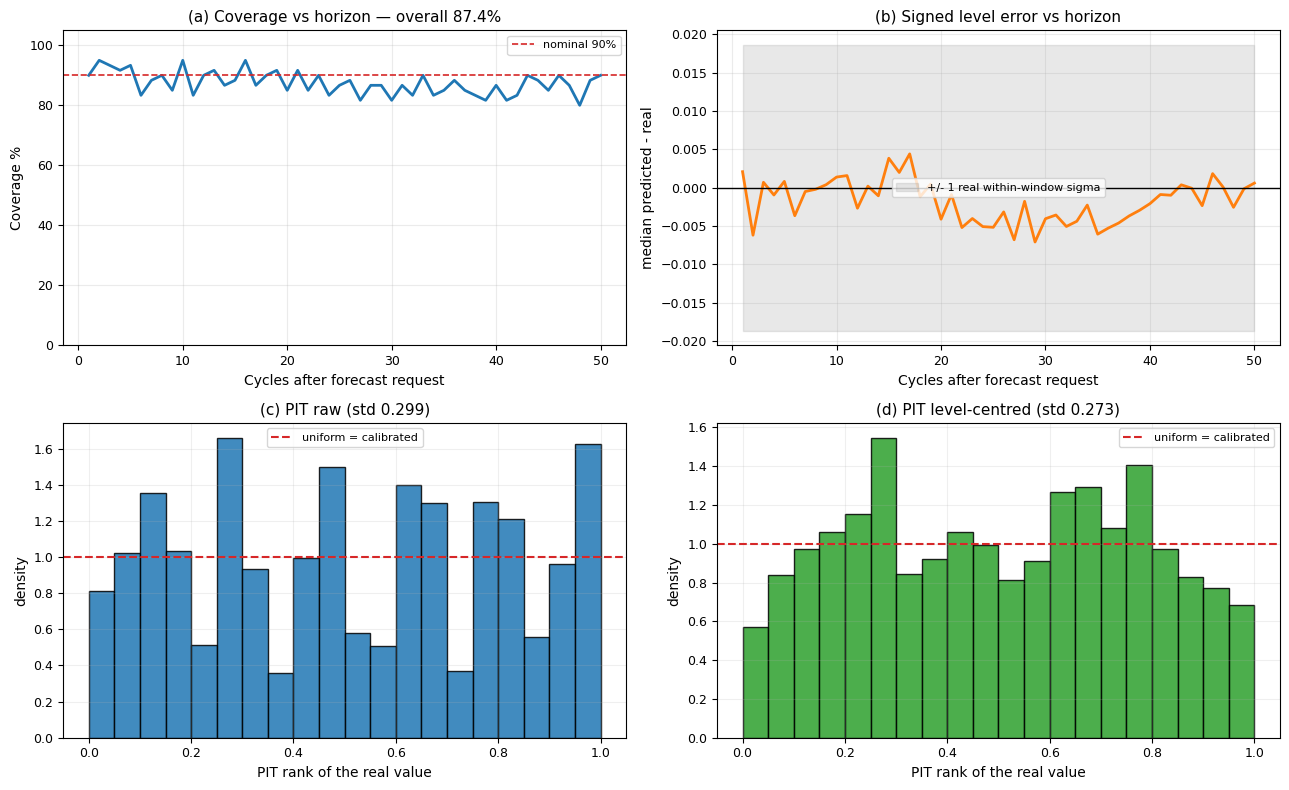

In [ ]:
# Diagnose location and dispersion errors over sixty test origins.
# Compare raw and retrospectively recentred coverage, PIT ranks and level error.
# Recentred quantities use realised future observations and are diagnostic only.
# The dispersion ratio compares within-window standard deviations, not band widths.
# Correlation with s0 suggests state dependence; it does not establish a cause.
# Interpret historical printed verdicts in light of these limitations.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("forecast_outputs", exist_ok=True)

for _need in ["on_demand_forecast", "valid_forecast_anchors", "df_test_raw",
              "df_val_raw", "TARGET_COL", "SEQ_LEN", "OD_SIM_CYCLES"]:
    if _need not in globals():
        raise RuntimeError(f"{_need} missing — run the preceding phases first")

DIAG_N_ANCHORS = 60      # subset of anchors (PIT needs the full ensembles)
DIAG_N_SIMS    = 400     # enough for stable 5-95% quantiles and ranks
DIAG_SEED      = 4040
NOMINAL        = 0.90
BAND_LO_D, BAND_HI_D = 0.05, 0.95


def wf_run(df_raw, anchors, n_sims, seed0, collect_pit=False,
           band=(BAND_LO_D, BAND_HI_D), horizon=None, progress=10):
    """On-demand walk-forward over `anchors` of `df_raw`.

    Returns a dict with the per-anchor table, per-cycle coverage curve and,
    if collect_pit, the per-cycle PIT values (raw and level-centred) needed
    for the calibration diagnostic.
    """
    H = int(horizon or OD_SIM_CYCLES)
    lo_q, hi_q = band
    rec, pit_raw, pit_ctr = [], [], []
    hits = np.zeros(H, dtype=float)
    lvl_err_by_h = np.zeros(H, dtype=float)
    n_anch = 0

    for j, t0 in enumerate(anchors):
        t0 = int(t0)
        r = on_demand_forecast(t0, n_sims=n_sims, sim_cycles=H,
                                 df_raw=df_raw, seed=seed0 + j)
        traj = r["traj"]                                    # (n_sims, H)
        y = df_raw.iloc[t0:t0 + H][TARGET_COL].astype(float).values

        lo = np.quantile(traj, lo_q, axis=0)
        hi = np.quantile(traj, hi_q, axis=0)
        inside = (y >= lo) & (y <= hi)
        hits += inside.astype(float)
        n_anch += 1

        med_path = np.median(traj, axis=0)
        lvl_err_by_h += (med_path - y)

        delta_a = float(med_path.mean() - y.mean())

        if collect_pit:
            lt = (traj < y[None, :]).mean(axis=0)
            le = (traj <= y[None, :]).mean(axis=0)
            pit_raw.append(0.5 * (lt + le))
            tc = traj - delta_a                              # remove level error
            lt_c = (tc < y[None, :]).mean(axis=0)
            le_c = (tc <= y[None, :]).mean(axis=0)
            pit_ctr.append(0.5 * (lt_c + le_c))

        ctx = df_raw.iloc[max(0, t0 - OD_RECIPE_WIN):t0]
        s0 = float(df_raw.iloc[max(0, t0 - 15):t0][TARGET_COL].astype(float).mean()
                   - ctx[TARGET_COL].astype(float).mean())

        rec.append({
            "t0": t0,
            "cycle_coverage": float(inside.mean()),
            "pred_mu": float(traj.mean()), "real_mu": float(y.mean()),
            "level_error": delta_a,
            "pred_sigma": float(np.mean(traj.std(axis=1, ddof=1))),
            "real_sigma": float(y.std(ddof=1)),
            "s0": s0,
        })
        if progress and (j + 1) % progress == 0:
            print(f"    anchor {j+1}/{len(anchors)}")

    tab = pd.DataFrame(rec)
    out = {
        "table": tab,
        "coverage": float(tab["cycle_coverage"].mean()),
        "per_cycle_cov": hits / max(1, n_anch),
        "level_err_by_h": lvl_err_by_h / max(1, n_anch),
        "n_points": int(len(tab) * H),
    }
    if collect_pit:
        out["pit_raw"] = np.concatenate(pit_raw)
        out["pit_centred"] = np.concatenate(pit_ctr)
    return out


def wilson(p, n, z=1.96):
    den = 1 + z * z / n
    ctr = (p + z * z / (2 * n)) / den
    hw = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return ctr - hw, ctr + hw


_idx = np.linspace(0, len(anchors_all) - 1, DIAG_N_ANCHORS).round().astype(int)
diag_anchors = anchors_all[np.unique(_idx)]

print(f"Diagnostic on {len(diag_anchors)} evaluation anchors "
      f"x {DIAG_N_SIMS} sims x {OD_SIM_CYCLES} cycles")
DIAG_RUN = wf_run(df_test_raw, diag_anchors, DIAG_N_SIMS, DIAG_SEED, collect_pit=True)
tab = DIAG_RUN["table"]

cov_raw = DIAG_RUN["coverage"]
pit_r, pit_c = DIAG_RUN["pit_raw"], DIAG_RUN["pit_centred"]
cov_ctr = float(np.mean((pit_c >= BAND_LO_D) & (pit_c <= BAND_HI_D)))

disp_ratio = float(tab["pred_sigma"].mean() / tab["real_sigma"].mean())
lvl_mae = float(tab["level_error"].abs().mean())
lvl_bias = float(tab["level_error"].mean())
rho_s0 = float(np.corrcoef(tab["level_error"], tab["s0"])[0, 1])
real_sig = float(tab["real_sigma"].mean())

blocks = []
for a in range(0, OD_SIM_CYCLES, 10):
    b = min(a + 10, OD_SIM_CYCLES)
    blocks.append({
        "cycles": f"{a+1}-{b}",
        "coverage %": round(float(DIAG_RUN["per_cycle_cov"][a:b].mean()) * 100, 1),
        "signed level error": round(float(DIAG_RUN["level_err_by_h"][a:b].mean()), 5),
    })
block_tab = pd.DataFrame(blocks)

print("\n--- 1) COVERAGE AND LEVEL ERROR BY HORIZON ---")
print(block_tab.to_string(index=False))

print("\n--- 2) DECOMPOSITION ---")
print(f"  coverage as-is                 : {cov_raw*100:.1f}%")
print(f"  coverage after removing the")
print(f"  per-anchor level error         : {cov_ctr*100:.1f}%   <-- dispersion alone")
print(f"  dispersion ratio pred/real     : {disp_ratio:.3f}  ({(disp_ratio-1)*100:+.1f}%)")
print(f"  |level error| mean             : {lvl_mae:.4f}  "
      f"= {lvl_mae/real_sig:.2f} x real within-window sigma ({real_sig:.4f})")
print(f"  level error signed mean        : {lvl_bias:+.4f}  (0 = no global bias)")
_rho_txt = ("mean reversion of the AR(1) slow state is the mechanism"
            if rho_s0 < -0.35 else
            "the twin follows the observed deviation instead of reverting it"
            if rho_s0 > 0.35 else
            "no clear link: the level error is not driven by s0")
print(f"  corr(level error , s0)         : {rho_s0:+.3f}  ({_rho_txt})")

pit_std = float(np.std(pit_r, ddof=1))
pit_std_c = float(np.std(pit_c, ddof=1))
UNIF_STD = 1.0 / np.sqrt(12)      # 0.2887 for a perfectly calibrated twin
print(f"\n--- 3) PIT SPREAD (uniform target {UNIF_STD:.4f}) ---")
print(f"  raw PIT std     : {pit_std:.4f}")
print(f"  centred PIT std : {pit_std_c:.4f}   "
      f"({'over-dispersed, band too wide' if pit_std_c < UNIF_STD*0.93 else 'under-dispersed, band too narrow' if pit_std_c > UNIF_STD*1.07 else 'dispersion OK'})")

lo_r, hi_r = wilson(cov_raw, DIAG_RUN["n_points"])
calibrated = (lo_r <= NOMINAL <= hi_r)

_compensating = (calibrated
                 and abs(cov_ctr - NOMINAL) > 0.03
                 and abs(disp_ratio - 1.0) > 0.08)

if calibrated and not _compensating:
    diag_verdict = "CALIBRATED"
elif _compensating:
    diag_verdict = "CALIBRATED_BY_COMPENSATION"
elif cov_ctr >= NOMINAL - 0.01:
    diag_verdict = "LOCATION"
elif disp_ratio > 1.08:
    diag_verdict = "LOCATION+OVERDISPERSION"
elif disp_ratio < 0.95:
    diag_verdict = "UNDERDISPERSION"
else:
    diag_verdict = "MIXED"

print("\n=================== VERDICT ===================")
print(f"Coverage {cov_raw*100:.1f}%  Wilson 95% CI [{lo_r*100:.1f}%, {hi_r*100:.1f}%]"
      f"  vs nominal {NOMINAL*100:.0f}%")
if diag_verdict == "CALIBRATED":
    print(">>> Nominal lies inside the interval: coverage is statistically")
    print("    indistinguishable from the nominal level.")
elif diag_verdict == "CALIBRATED_BY_COMPENSATION":
    print(">>> Nominal lies inside the interval, but two offsetting components")
    print(f"    contribute: band width {(disp_ratio-1)*100:+.1f}% and a location error of")
    print(f"    {lvl_mae/real_sig:.2f} sigma (coverage after centring {cov_ctr*100:.1f}%).")
    print("    The aggregate is therefore reported together with its decomposition.")
elif diag_verdict == "LOCATION":
    print(">>> The discrepancy is attributable to location alone.")
    print("    Removing the per-anchor level error restores nominal coverage, and the")
    print("    band width is adequate or generous: the interval is correctly sized")
    print("    and incorrectly centred. Widening it would not be the corresponding")
    print("    correction.")
elif diag_verdict == "LOCATION+OVERDISPERSION":
    print(">>> Two components contribute: a location error and an excess band width.")
    print("    Both are consistent with a mis-specified slow-wander component, whose")
    print("    scale was calibrated under the stationary regime with a synthetic")
    print("    initial window.")
elif diag_verdict == "UNDERDISPERSION":
    print(">>> The band is too narrow: injected variability is insufficient.")
    print("    If a higher slow-noise setting does not restore coverage, the residual")
    print("    discrepancy is attributable to a variability source outside the model")
    print("    (material batch, ambient conditions, tool temperature).")
else:
    print(">>> Neither location nor width alone accounts for the discrepancy.")
print("==============================================")

diag_summary = {
    "n_anchors": int(len(tab)), "n_sims": DIAG_N_SIMS,
    "coverage_raw": cov_raw, "coverage_ci": (lo_r, hi_r),
    "coverage_centred": cov_ctr,
    "dispersion_ratio": disp_ratio,
    "level_mae": lvl_mae, "level_bias": lvl_bias,
    "level_mae_in_sigma": lvl_mae / real_sig,
    "corr_level_s0": rho_s0,
    "pit_std_raw": pit_std, "pit_std_centred": pit_std_c,
    "verdict": diag_verdict,
    "by_horizon": block_tab.to_dict(orient="records"),
}
block_tab.to_csv("forecast_outputs/diag_by_horizon.csv", index=False)
tab.to_csv("forecast_outputs/diag_per_anchor.csv", index=False)

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
h = np.arange(1, OD_SIM_CYCLES + 1)

ax[0, 0].plot(h, DIAG_RUN["per_cycle_cov"] * 100, color="#1F77B4", lw=2)
ax[0, 0].axhline(NOMINAL * 100, color="#D62728", ls="--", lw=1.2, label="nominal 90%")
ax[0, 0].set_ylim(0, 105); ax[0, 0].legend(fontsize=8); ax[0, 0].grid(alpha=0.25)
ax[0, 0].set_title(f"(a) Coverage vs horizon — overall {cov_raw*100:.1f}%")
ax[0, 0].set_xlabel("Cycles after forecast request"); ax[0, 0].set_ylabel("Coverage %")

ax[0, 1].plot(h, DIAG_RUN["level_err_by_h"], color="#FF7F0E", lw=2)
ax[0, 1].axhline(0, color="black", lw=1)
ax[0, 1].fill_between(h, -real_sig, real_sig, color="grey", alpha=0.18,
                      label="+/- 1 real within-window sigma")
ax[0, 1].legend(fontsize=8); ax[0, 1].grid(alpha=0.25)
ax[0, 1].set_title("(b) Signed level error vs horizon")
ax[0, 1].set_xlabel("Cycles after forecast request"); ax[0, 1].set_ylabel("median predicted - real")

for a_, p_, t_, c_ in ((ax[1, 0], pit_r, f"(c) PIT raw (std {pit_std:.3f})", "#1F77B4"),
                       (ax[1, 1], pit_c, f"(d) PIT level-centred (std {pit_std_c:.3f})", "#2CA02C")):
    a_.hist(p_, bins=20, range=(0, 1), color=c_, edgecolor="black", alpha=0.85,
            weights=np.ones_like(p_) / len(p_) * 20)
    a_.axhline(1.0, color="#D62728", ls="--", lw=1.5, label="uniform = calibrated")
    a_.set_title(t_); a_.set_xlabel("PIT rank of the real value"); a_.set_ylabel("density")
    a_.legend(fontsize=8); a_.grid(alpha=0.2)

plt.tight_layout()
fig.savefig("forecast_outputs/calibration_diagnostic.png", dpi=600, bbox_inches="tight")
plt.show()

Search on 50 validation anchors x 300 sims | grid = 2x4

  init=observed  scale=0.00  ->  coverage 73.36%   sigma ratio 0.327
  init=observed  scale=0.35  ->  coverage 74.88%   sigma ratio 0.343
  init=observed  scale=0.70  ->  coverage 80.80%   sigma ratio 0.383
  init=observed  scale=1.00  ->  coverage 84.44%   sigma ratio 0.425
  init=zero      scale=0.00  ->  coverage 73.36%   sigma ratio 0.327
  init=zero      scale=0.35  ->  coverage 75.20%   sigma ratio 0.344
  init=zero      scale=0.70  ->  coverage 81.08%   sigma ratio 0.383
  init=zero      scale=1.00  ->  coverage 84.84%   sigma ratio 0.425

--- VALIDATION SEARCH (sorted by distance to nominal) ---
slow_init  slow_scale  coverage %  |cov-90|  sigma ratio  |level err|
     zero        1.00       84.84      5.16        0.425      0.01465
 observed        1.00       84.44      5.56        0.425      0.01480
     zero        0.70       81.08      8.92        0.383      0.01465
 observed        0.70       80.80      9.20        0

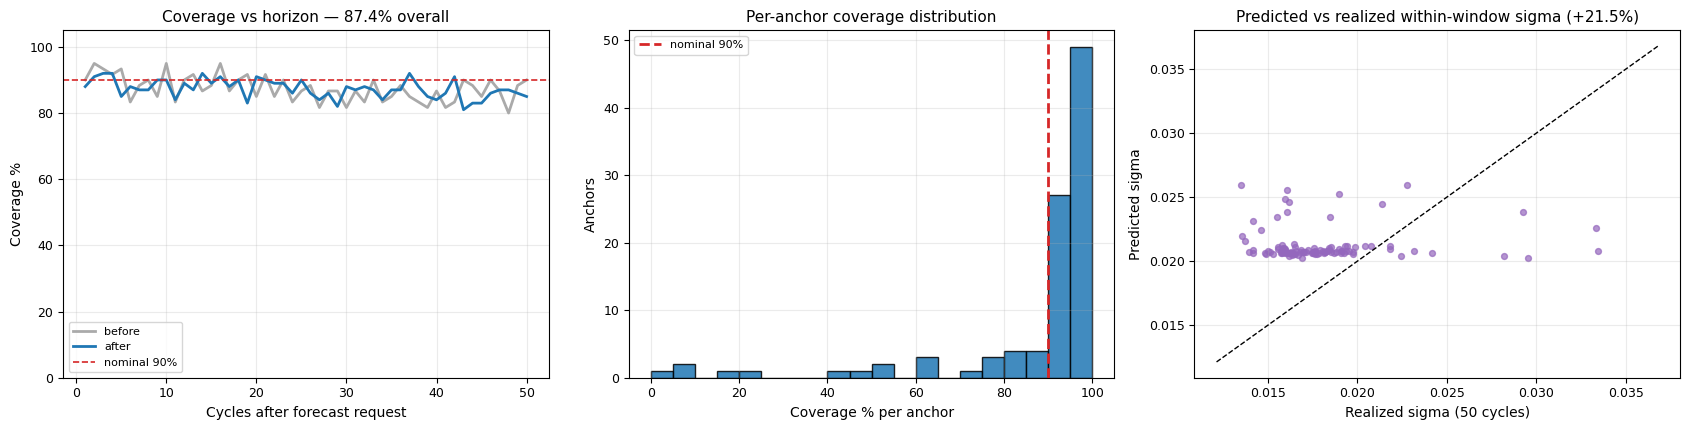

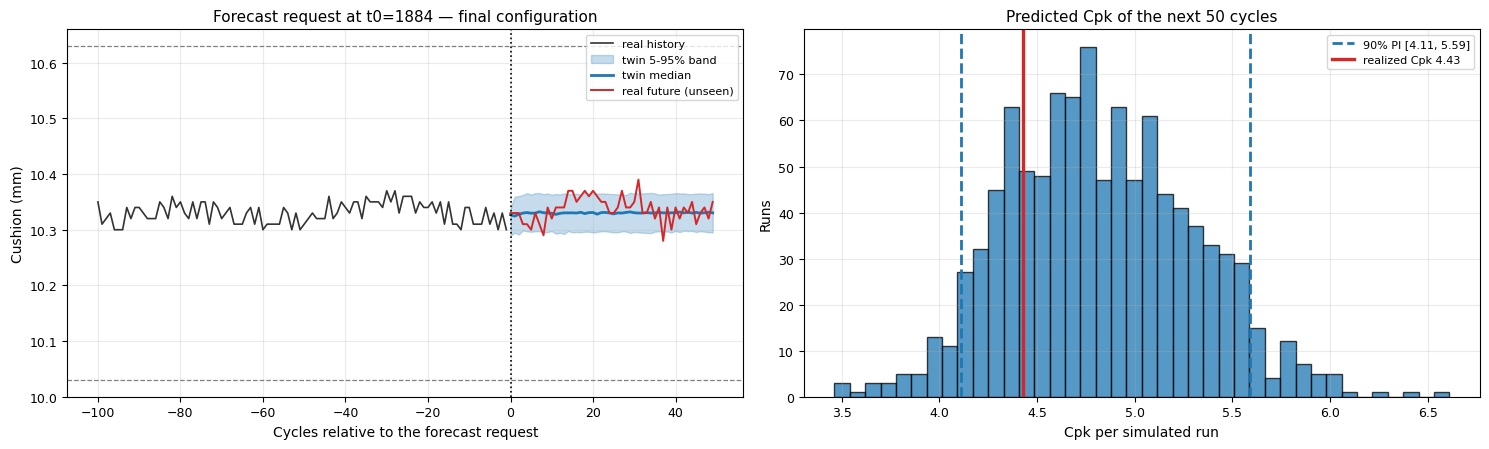


[demo regenerated with the final configuration] t0=1884 | predicted Cpk 90% PI [4.113, 5.591] (median 4.781) | realized 4.426 | inside: True
Figure written under the final configuration.


In [ ]:
# Search slow-state initialisation and scale on validation origins, then evaluate
# the selected configuration on test origins. Retain both before/after results.
# The scale grid is limited and its best point may be on the boundary; the search
# does not show that no global recalibration could work.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "diag_summary" not in globals():
    raise RuntimeError("Run the calibration diagnostic first: its verdict drives the recalibration search.")

FORCE_RECALIB = False        # set True to run the search unconditionally
_run = FORCE_RECALIB or (diag_summary["verdict"] != "CALIBRATED")

if not _run:
    print("Recalibration search not required: coverage is statistically")
    print("indistinguishable from the nominal level.")
else:
    CAL_N_ANCHORS = 50
    CAL_N_SIMS    = 300
    CAL_SEED      = 5150
    NOMINAL       = 0.90

    _slow_base = float(SLOW_SIGMA) if "SLOW_SIGMA" in globals() else 0.0
    GRID_INIT  = ["observed", "zero"]
    GRID_SCALE = [0.0, 0.35, 0.70, 1.00]

    val_anchors_all = valid_forecast_anchors(df_val_raw, SEQ_LEN, OD_SIM_CYCLES)
    if len(val_anchors_all) < 10:
        print(f"Recalibration search not performed: only {len(val_anchors_all)} validation")
        print("anchors are available. Searching on the evaluation set would be circular,")
        print("so the configuration is left unchanged and the anchor count is recorded")
        print("as the reason.")
        _run = False
    if not _run:
        pass
    else:
      _vi = np.linspace(0, len(val_anchors_all) - 1,
                      min(CAL_N_ANCHORS, len(val_anchors_all))).round().astype(int)
      cal_anchors = val_anchors_all[np.unique(_vi)]
      print(f"Search on {len(cal_anchors)} validation anchors "
          f"x {CAL_N_SIMS} sims | grid = {len(GRID_INIT)}x{len(GRID_SCALE)}\n")

      _init_backup  = globals().get("OD_SLOW_INIT", "observed")
      _slow_backup  = float(globals().get("SLOW_SIGMA_BTN", _slow_base))

      rows = []
      for ini in GRID_INIT:
        for sc in GRID_SCALE:
            globals()["OD_SLOW_INIT"] = ini
            globals()["SLOW_SIGMA_BTN"] = _slow_base * sc
            R = wf_run(df_val_raw, cal_anchors, CAL_N_SIMS, CAL_SEED, progress=0)
            t = R["table"]
            rows.append({
                "slow_init": ini,
                "slow_scale": sc,
                "coverage %": round(R["coverage"] * 100, 2),
                "|cov-90|": round(abs(R["coverage"] - NOMINAL) * 100, 2),
                "sigma ratio": round(float(t["pred_sigma"].mean() / t["real_sigma"].mean()), 3),
                "|level err|": round(float(t["level_error"].abs().mean()), 5),
            })
            print(f"  init={ini:<9} scale={sc:.2f}  ->  coverage "
                  f"{R['coverage']*100:5.2f}%   sigma ratio {rows[-1]['sigma ratio']:.3f}")

      cal_tab = pd.DataFrame(rows).sort_values("|cov-90|").reset_index(drop=True)
      print("\n--- VALIDATION SEARCH (sorted by distance to nominal) ---")
      print(cal_tab.to_string(index=False))

      best = cal_tab.iloc[0]
      OD_SLOW_INIT  = str(best["slow_init"])
      SLOW_SIGMA_BTN = _slow_base * float(best["slow_scale"])
      globals()["OD_SLOW_INIT"] = OD_SLOW_INIT
      globals()["SLOW_SIGMA_BTN"] = SLOW_SIGMA_BTN
      print(f"\n>>> SELECTED on validation: slow_init='{OD_SLOW_INIT}', "
          f"slow_scale={best['slow_scale']:.2f} "
          f"(injected slow sigma {SLOW_SIGMA_BTN:.4f}) | val coverage {best['coverage %']:.2f}%")

      wf_before = {
        "coverage": float(validation_summary["cycle_coverage"]),
        "coverage_ci": tuple(validation_summary["coverage_ci"]),
        "sigma_rel_pct": float(validation_summary["sigma_rel_pct"]),
        "mu_mae": float(validation_summary["mu_mae"]),
        "config": {"slow_init": _init_backup, "slow_sigma_btn": _slow_backup},
      }

      print(f"\nFinal evaluation on the held-out set: {len(wf_anchors)} anchors "
            f"x {WF_N_SIMS} sims (this is the number the article reports)")
      WF_FINAL = wf_run(df_test_raw, wf_anchors, WF_N_SIMS, WF_SEED, progress=20)
      ft = WF_FINAL["table"]

      cov_new = WF_FINAL["coverage"]
      lo_n, hi_n = wilson(cov_new, WF_FINAL["n_points"])
      sigma_bias_new = float((ft["pred_sigma"] - ft["real_sigma"]).mean())
      sigma_rel_new = float(((ft["pred_sigma"] - ft["real_sigma"]) / ft["real_sigma"]).mean() * 100)
      mu_mae_new = float((ft["pred_mu"] - ft["real_mu"]).abs().mean())

      print("\n========== WALK-FORWARD AFTER RECALIBRATION (TEST) ==========")
      print(f"Coverage: {cov_new*100:.1f}%   Wilson 95% CI [{lo_n*100:.1f}%, {hi_n*100:.1f}%]"
          f"   (nominal {NOMINAL*100:.0f}%)")
      print(f"Before  : {wf_before['coverage']*100:.1f}%   CI "
          f"[{wf_before['coverage_ci'][0]*100:.1f}%, {wf_before['coverage_ci'][1]*100:.1f}%]")
      print(f"Within-window sigma bias: {sigma_rel_new:+.1f}%  (before {wf_before['sigma_rel_pct']:+.1f}%)")
      print(f"Mean |mu error|:          {mu_mae_new:.4f}  (before {wf_before['mu_mae']:.4f})")
      if lo_n <= NOMINAL <= hi_n:
        print(">>> Nominal lies inside the 95% interval: coverage is statistically")
        print("    indistinguishable from the nominal level.")
      else:
        _d = "below" if cov_new < NOMINAL else "above"
        print(f">>> Coverage remains {_d} nominal by {(cov_new-NOMINAL)*100:+.1f} points.")
        print("    The value, its interval and the attributed mechanism are reported")
        print("    together.")
      print("=============================================================")

      wf = ft.copy()
      per_cycle_hits = WF_FINAL["per_cycle_cov"] * len(ft)
      per_cycle_n = len(ft)
      total_cov, cov_lo, cov_hi = cov_new, lo_n, hi_n
      validation_summary = {
        "n_anchors": int(len(ft)), "n_sims": int(WF_N_SIMS),
        "cycle_coverage": cov_new, "coverage_ci": (lo_n, hi_n),
        "mu_mae": mu_mae_new, "sigma_bias": sigma_bias_new,
        "sigma_rel_pct": sigma_rel_new,
        "config": {"slow_init": OD_SLOW_INIT, "slow_sigma_btn": SLOW_SIGMA_BTN,
                   "calibrated_on": "validation anchors"},
        "before_recalibration": wf_before,
      }
      ft.to_csv("forecast_outputs/walk_forward_final.csv", index=False)
      cal_tab.to_csv("forecast_outputs/recalibration_search_validation.csv", index=False)

      fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
      hh = np.arange(1, OD_SIM_CYCLES + 1)
      ax[0].plot(hh, DIAG_RUN["per_cycle_cov"] * 100, color="#AAAAAA", lw=2, label="before")
      ax[0].plot(hh, WF_FINAL["per_cycle_cov"] * 100, color="#1F77B4", lw=2, label="after")
      ax[0].axhline(90, color="#D62728", ls="--", lw=1.2, label="nominal 90%")
      ax[0].set_ylim(0, 105); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.25)
      ax[0].set_title(f"Coverage vs horizon — {cov_new*100:.1f}% overall")
      ax[0].set_xlabel("Cycles after forecast request"); ax[0].set_ylabel("Coverage %")

      ax[1].hist(ft["cycle_coverage"] * 100, bins=20, color="#1F77B4",
               edgecolor="black", alpha=0.85)
      ax[1].axvline(90, color="#D62728", ls="--", lw=2, label="nominal 90%")
      ax[1].set_title("Per-anchor coverage distribution")
      ax[1].set_xlabel("Coverage % per anchor"); ax[1].set_ylabel("Anchors")
      ax[1].legend(fontsize=8); ax[1].grid(alpha=0.25)

      ax[2].scatter(ft["real_sigma"], ft["pred_sigma"], s=18, alpha=0.7, color="#9467BD")
      _sl = [min(ft["real_sigma"].min(), ft["pred_sigma"].min()) * 0.9,
           max(ft["real_sigma"].max(), ft["pred_sigma"].max()) * 1.1]
      ax[2].plot(_sl, _sl, "k--", lw=1)
      ax[2].set_title(f"Predicted vs realized within-window sigma ({sigma_rel_new:+.1f}%)")
      ax[2].set_xlabel("Realized sigma (50 cycles)"); ax[2].set_ylabel("Predicted sigma")
      ax[2].grid(alpha=0.25)
      plt.tight_layout()
      fig.savefig("forecast_outputs/walk_forward_final.png", dpi=600, bbox_inches="tight")
      plt.show()

      demo_t0 = int(anchors_all[len(anchors_all) // 2])
      _res = on_demand_forecast(demo_t0, n_sims=WF_N_SIMS,
                                  seed=int(globals().get("DEMO_SEED", 123)))
      _traj = _res["traj"]
      _hist_n = 100
      _real_hist = df_test_raw.iloc[demo_t0 - _hist_n:demo_t0][TARGET_COL].astype(float).values
      _real_fut = df_test_raw.iloc[demo_t0:demo_t0 + OD_SIM_CYCLES][TARGET_COL].astype(float).values
      _cpk_runs = per_run_cpk(_traj, LSL, USL)
      q05, q50, q95 = np.quantile(_cpk_runs, [0.05, 0.50, 0.95])
      _real_cpk = float(min((USL - _real_fut.mean()) / (3 * _real_fut.std(ddof=1)),
                            (_real_fut.mean() - LSL) / (3 * _real_fut.std(ddof=1))))
      _inside = bool(q05 <= _real_cpk <= q95)

      fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.6))
      _xh = np.arange(-_hist_n, 0); _xf = np.arange(0, OD_SIM_CYCLES)
      a1.plot(_xh, _real_hist, color="#333333", lw=1.2, label="real history")
      a1.fill_between(_xf, np.quantile(_traj, 0.05, axis=0), np.quantile(_traj, 0.95, axis=0),
                      color="#1F77B4", alpha=0.25, label="twin 5-95% band")
      a1.plot(_xf, np.median(_traj, axis=0), color="#1F77B4", lw=2, label="twin median")
      a1.plot(_xf, _real_fut, color="#D62728", lw=1.4, label="real future (unseen)")
      a1.axvline(0, color="black", ls=":", lw=1.2)
      a1.axhline(LSL, color="grey", ls="--", lw=0.9)
      a1.axhline(USL, color="grey", ls="--", lw=0.9)
      a1.set_title(f"Forecast request at t0={demo_t0} — final configuration")
      a1.set_xlabel("Cycles relative to the forecast request"); a1.set_ylabel("Cushion (mm)")
      a1.legend(fontsize=8); a1.grid(alpha=0.25)

      a2.hist(_cpk_runs, bins=40, color="#1F77B4", alpha=0.75, edgecolor="black")
      a2.axvline(q05, color="#1F77B4", ls="--", lw=2, label=f"90% PI [{q05:.2f}, {q95:.2f}]")
      a2.axvline(q95, color="#1F77B4", ls="--", lw=2)
      a2.axvline(_real_cpk, color="#D62728", lw=2.4, label=f"realized Cpk {_real_cpk:.2f}")
      a2.set_title("Predicted Cpk of the next 50 cycles")
      a2.set_xlabel("Cpk per simulated run"); a2.set_ylabel("Runs")
      a2.legend(fontsize=8); a2.grid(alpha=0.25)
      plt.tight_layout()
      fig.savefig("forecast_outputs/single_anchor_demo_final.png", dpi=600,
                  bbox_inches="tight")
      plt.show()

      print(f"\n[demo regenerated with the final configuration] t0={demo_t0} | "
            f"predicted Cpk 90% PI [{q05:.3f}, {q95:.3f}] (median {q50:.3f}) | "
            f"realized {_real_cpk:.3f} | inside: {_inside}")
      print("Figure written under the final configuration.")
      demo_summary = {"t0": demo_t0, "cpk_pi": (float(q05), float(q95)),
                      "cpk_median": float(q50), "real_cpk": _real_cpk,
                      "inside": _inside, "config": "post-recalibration",
                      "figure": "forecast_outputs/single_anchor_demo_final.png"}

### Ensemble-size sensitivity and display example

Assess Monte Carlo stability at one anchor and illustrate a possible machine-side display. Neither is a production deployment test.


MONTE CARLO CONVERGENCE at anchor t0=1884  (reference 2000 runs)
reference: Cpk median 4.794, 90% PI [4.059, 5.611], width 1.552


,n_sims,cpk_median_mean,cpk_median_sd,pi_low_sd,pi_high_sd,pi_width_mean,pi_width_sd,max_bound_dev_pct,mc_se_of_bounds_pct_of_width
0,10,4.78097,0.17447,0.19097,0.21922,1.14915,0.27955,4.93908,14.12328
1,25,4.79900,0.13077,0.17357,0.20758,1.38387,0.26064,1.89842,13.37332
2,50,4.77736,0.06358,0.12155,0.15787,1.41470,0.18324,1.58313,10.17040
3,100,4.79481,0.06184,0.08832,0.10940,1.47840,0.11843,0.87260,7.04768
4,200,4.78730,0.04007,0.06518,0.07559,1.51108,0.10688,0.80877,4.87006
5,300,4.79273,0.02662,0.03986,0.07058,1.54411,0.08407,0.38179,4.54726
6,500,4.79289,0.02577,0.03477,0.04604,1.54559,0.05818,0.11626,2.96578
7,750,4.79758,0.01920,0.03628,0.04491,1.54463,0.06506,0.09267,2.89304
8,1000,4.78952,0.01755,0.02171,0.03087,1.54967,0.04001,0.05115,1.98880
9,1500,4.79306,0.00786,0.01311,0.01761,1.53904,0.01936,0.22695,1.13427



Interval bounds are within 1.0% of the reference from n_sims = 100 onward.
At the operating value n_sims = 1000: bound deviation 0.05%, Monte Carlo standard error of the bounds = 1.99% of the interval width.


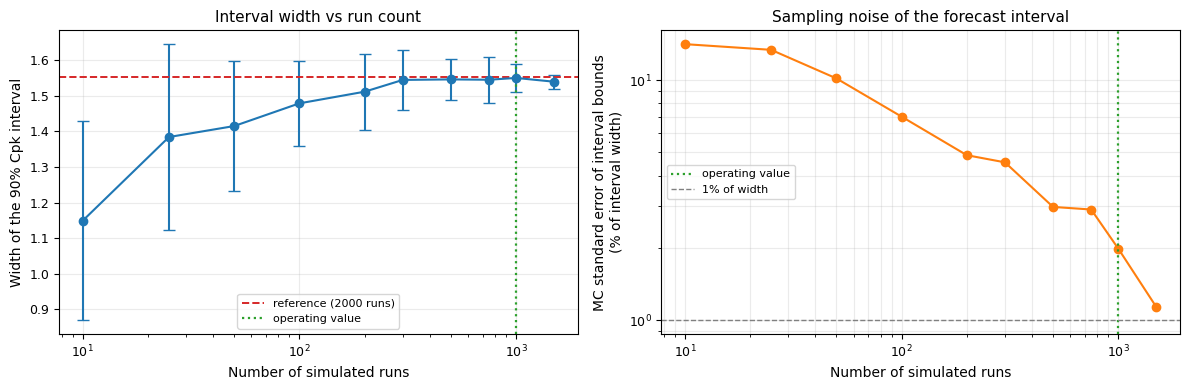

In [ ]:
# Subsample a reference ensemble to assess Monte Carlo stability at one anchor.
# This measures simulation error, not forecast accuracy or interval calibration.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("forecast_outputs", exist_ok=True)

CONV_N_REF   = 2000                 # reference run count
CONV_GRID    = [10, 25, 50, 100, 200, 300, 500, 750, 1000, 1500]
CONV_REPEATS = 30                   # subsamples per grid point
CONV_TOL_PCT = 1.0                  # tolerance on interval bounds, % of reference
CONV_SEED    = 31337

conv_t0 = int(anchors_all[len(anchors_all) // 2])
_ref = on_demand_forecast(conv_t0, n_sims=CONV_N_REF, seed=CONV_SEED)
_ref_cpk = per_run_cpk(_ref["traj"], LSL, USL)
_ref_q05, _ref_q50, _ref_q95 = np.quantile(_ref_cpk, [0.05, 0.50, 0.95])
_ref_width = _ref_q95 - _ref_q05

_rng_conv = np.random.default_rng(CONV_SEED)
_rows = []
for _n in CONV_GRID:
    if _n > CONV_N_REF:
        continue
    _q05s, _q95s, _q50s, _wid = [], [], [], []
    for _r in range(CONV_REPEATS):
        _sub = _rng_conv.choice(_ref_cpk, size=_n, replace=False)
        a, b, c = np.quantile(_sub, [0.05, 0.50, 0.95])
        _q05s.append(a); _q50s.append(b); _q95s.append(c); _wid.append(c - a)
    _rows.append({
        "n_sims": _n,
        "cpk_median_mean": float(np.mean(_q50s)),
        "cpk_median_sd": float(np.std(_q50s, ddof=1)),
        "pi_low_sd": float(np.std(_q05s, ddof=1)),
        "pi_high_sd": float(np.std(_q95s, ddof=1)),
        "pi_width_mean": float(np.mean(_wid)),
        "pi_width_sd": float(np.std(_wid, ddof=1)),
        "max_bound_dev_pct": float(100.0 * max(
            abs(np.mean(_q05s) - _ref_q05) / abs(_ref_q05),
            abs(np.mean(_q95s) - _ref_q95) / abs(_ref_q95))),
        "mc_se_of_bounds_pct_of_width": float(
            100.0 * max(np.std(_q05s, ddof=1), np.std(_q95s, ddof=1)) / _ref_width),
    })

mc_convergence_df = pd.DataFrame(_rows).round(5)

_ok = mc_convergence_df[mc_convergence_df["max_bound_dev_pct"] <= CONV_TOL_PCT]
_n_suff = int(_ok["n_sims"].min()) if len(_ok) else None

print("=" * 72)
print(f"MONTE CARLO CONVERGENCE at anchor t0={conv_t0}  (reference {CONV_N_REF} runs)")
print("=" * 72)
print(f"reference: Cpk median {_ref_q50:.3f}, 90% PI [{_ref_q05:.3f}, {_ref_q95:.3f}], "
      f"width {_ref_width:.3f}")
display(mc_convergence_df)
if _n_suff is not None:
    print(f"\nInterval bounds are within {CONV_TOL_PCT:.1f}% of the reference from "
          f"n_sims = {_n_suff} onward.")
_at_op = mc_convergence_df[mc_convergence_df["n_sims"] == 1000]
if len(_at_op):
    _r = _at_op.iloc[0]
    print(f"At the operating value n_sims = 1000: bound deviation "
          f"{_r['max_bound_dev_pct']:.2f}%, Monte Carlo standard error of the bounds "
          f"= {_r['mc_se_of_bounds_pct_of_width']:.2f}% of the interval width.")

mc_convergence_summary = {
    "anchor_t0": conv_t0,
    "n_reference": CONV_N_REF,
    "repeats_per_point": CONV_REPEATS,
    "tolerance_pct": CONV_TOL_PCT,
    "reference_cpk_median": float(_ref_q50),
    "reference_pi": (float(_ref_q05), float(_ref_q95)),
    "reference_pi_width": float(_ref_width),
    "n_sims_sufficient": _n_suff,
    "operating_n_sims": 1000,
}
mc_convergence_df.to_csv("forecast_outputs/mc_convergence.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].errorbar(mc_convergence_df["n_sims"], mc_convergence_df["pi_width_mean"],
               yerr=mc_convergence_df["pi_width_sd"], fmt="o-", capsize=4,
               color="#1F77B4")
ax[0].axhline(_ref_width, color="#D62728", ls="--", lw=1.4,
              label=f"reference ({CONV_N_REF} runs)")
ax[0].axvline(1000, color="#2CA02C", ls=":", lw=1.6, label="operating value")
ax[0].set_xscale("log")
ax[0].set_xlabel("Number of simulated runs")
ax[0].set_ylabel("Width of the 90% Cpk interval")
ax[0].set_title("Interval width vs run count")
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.25)

ax[1].plot(mc_convergence_df["n_sims"],
           mc_convergence_df["mc_se_of_bounds_pct_of_width"], "o-", color="#FF7F0E")
ax[1].axvline(1000, color="#2CA02C", ls=":", lw=1.6, label="operating value")
ax[1].axhline(CONV_TOL_PCT, color="grey", ls="--", lw=1.0,
              label=f"{CONV_TOL_PCT:.0f}% of width")
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("Number of simulated runs")
ax[1].set_ylabel("MC standard error of interval bounds\n(% of interval width)")
ax[1].set_title("Sampling noise of the forecast interval")
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.25, which="both")
plt.tight_layout()
fig.savefig("forecast_outputs/mc_convergence.png", dpi=600, bbox_inches="tight")
plt.show()


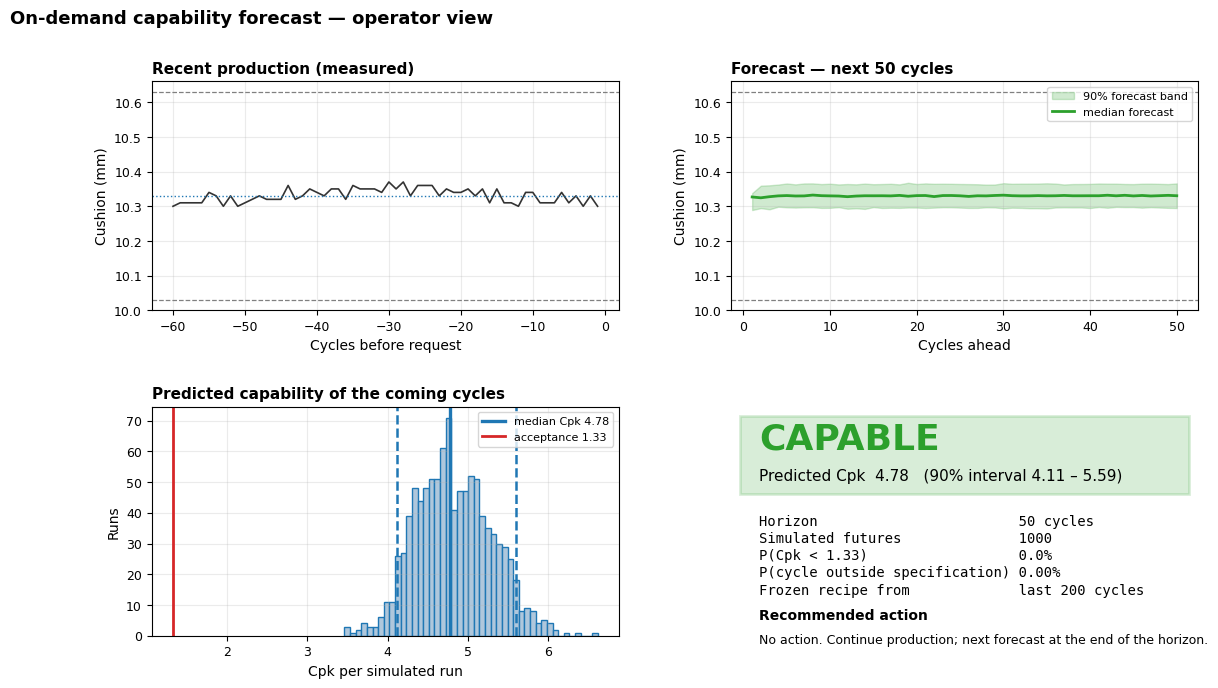

[operator dashboard] status=CAPABLE | Cpk 4.78 [4.11, 5.59] | P(Cpk<1.33) = 0.0% | P(out of spec) = 0.00%


In [ ]:
# Illustrate a possible operator display using the existing forecast.
# The status and recommended action are demonstration logic, not a validated
# conformance decision or an implemented production control system.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import os

os.makedirs("forecast_outputs", exist_ok=True)

DASH_T0     = int(anchors_all[len(anchors_all) // 2])
DASH_N_SIMS = 1000
DASH_SEED   = int(globals().get("DEMO_SEED", 123))
CPK_ACCEPT  = 1.33            # conventional industrial acceptance threshold

_d = on_demand_forecast(DASH_T0, n_sims=DASH_N_SIMS, seed=DASH_SEED)
_tr = _d["traj"]
_cpk = per_run_cpk(_tr, LSL, USL)
_q05, _q50, _q95 = np.quantile(_cpk, [0.05, 0.50, 0.95])
_hist = df_test_raw.iloc[DASH_T0 - 60:DASH_T0][TARGET_COL].astype(float).values
_lo_band = np.quantile(_tr, 0.05, axis=0)
_hi_band = np.quantile(_tr, 0.95, axis=0)
_med = np.median(_tr, axis=0)
_p_below = float(np.mean(_cpk < CPK_ACCEPT))
_p_oos = float(np.mean((_tr < LSL) | (_tr > USL)))

if _q05 >= CPK_ACCEPT:
    _status, _colour = "CAPABLE", "#2CA02C"
    _action = "No action. Continue production; next forecast at the end of the horizon."
elif _q50 >= CPK_ACCEPT:
    _status, _colour = "MARGINAL", "#FF7F0E"
    _action = ("Capability is likely acceptable but the lower bound is below the "
               "threshold. Increase sampling and review the packing settings.")
else:
    _status, _colour = "AT RISK", "#D62728"
    _action = ("Predicted capability is below the acceptance threshold. Inspect "
               "packing pressure and dosing before the horizon elapses.")

fig = plt.figure(figsize=(13.5, 7.2))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1], hspace=0.42, wspace=0.24)

a1 = fig.add_subplot(gs[0, 0])
a1.plot(np.arange(-len(_hist), 0), _hist, color="#333333", lw=1.2)
a1.axhline(LSL, color="grey", ls="--", lw=0.9)
a1.axhline(USL, color="grey", ls="--", lw=0.9)
a1.axhline(TARGET_CUSHION, color="#1F77B4", ls=":", lw=1.0)
a1.set_title("Recent production (measured)", loc="left", fontweight="bold")
a1.set_xlabel("Cycles before request"); a1.set_ylabel("Cushion (mm)")
a1.grid(alpha=0.25)

a2 = fig.add_subplot(gs[0, 1])
_xf = np.arange(1, _tr.shape[1] + 1)
a2.fill_between(_xf, _lo_band, _hi_band, color=_colour, alpha=0.22,
                label="90% forecast band")
a2.plot(_xf, _med, color=_colour, lw=2, label="median forecast")
a2.axhline(LSL, color="grey", ls="--", lw=0.9)
a2.axhline(USL, color="grey", ls="--", lw=0.9)
a2.set_title(f"Forecast — next {_tr.shape[1]} cycles", loc="left", fontweight="bold")
a2.set_xlabel("Cycles ahead"); a2.set_ylabel("Cushion (mm)")
a2.legend(fontsize=8); a2.grid(alpha=0.25)

a3 = fig.add_subplot(gs[1, 0])
a3.hist(_cpk, bins=45, color="#AFC7DC", edgecolor="#1F77B4")
a3.axvline(_q05, color="#1F77B4", ls="--", lw=1.8)
a3.axvline(_q95, color="#1F77B4", ls="--", lw=1.8)
a3.axvline(_q50, color="#1F77B4", lw=2.4, label=f"median Cpk {_q50:.2f}")
a3.axvline(CPK_ACCEPT, color="#D62728", lw=2.0,
           label=f"acceptance {CPK_ACCEPT:.2f}")
a3.set_title("Predicted capability of the coming cycles", loc="left", fontweight="bold")
a3.set_xlabel("Cpk per simulated run"); a3.set_ylabel("Runs")
a3.legend(fontsize=8); a3.grid(alpha=0.25)

a4 = fig.add_subplot(gs[1, 1]); a4.axis("off")
a4.add_patch(Rectangle((0.02, 0.62), 0.96, 0.34, transform=a4.transAxes,
                       facecolor=_colour, alpha=0.18, edgecolor=_colour, lw=2))
a4.text(0.06, 0.86, _status, transform=a4.transAxes, fontsize=26,
        fontweight="bold", color=_colour, va="center")
a4.text(0.06, 0.70, f"Predicted Cpk  {_q50:.2f}   (90% interval {_q05:.2f} – {_q95:.2f})",
        transform=a4.transAxes, fontsize=11, va="center")
_lines = [
    f"Horizon                        {_tr.shape[1]} cycles",
    f"Simulated futures              {DASH_N_SIMS}",
    f"P(Cpk < {CPK_ACCEPT:.2f})                  {_p_below*100:.1f}%",
    f"P(cycle outside specification) {_p_oos*100:.2f}%",
    f"Frozen recipe from             last {int(OD_RECIPE_WIN)} cycles",
]
for i, t in enumerate(_lines):
    a4.text(0.06, 0.50 - i * 0.075, t, transform=a4.transAxes, fontsize=10,
            family="monospace", va="center")
a4.text(0.06, 0.09, "Recommended action", transform=a4.transAxes, fontsize=10,
        fontweight="bold", va="center")
a4.text(0.06, -0.02, _action, transform=a4.transAxes, fontsize=9, va="center",
        wrap=True)

fig.suptitle("On-demand capability forecast — operator view", fontsize=13,
             fontweight="bold", x=0.02, ha="left")
fig.savefig("forecast_outputs/operator_dashboard.png", dpi=600, bbox_inches="tight")
plt.show()

operator_dashboard_summary = {
    "anchor_t0": DASH_T0,
    "status": _status,
    "cpk_median": float(_q50),
    "cpk_pi": (float(_q05), float(_q95)),
    "cpk_acceptance_threshold": CPK_ACCEPT,
    "p_cpk_below_threshold": _p_below,
    "p_cycle_out_of_spec": _p_oos,
    "horizon_cycles": int(_tr.shape[1]),
    "n_sims": DASH_N_SIMS,
    "figure": "forecast_outputs/operator_dashboard.png",
}
print(f"[operator dashboard] status={_status} | Cpk {_q50:.2f} "
      f"[{_q05:.2f}, {_q95:.2f}] | P(Cpk<{CPK_ACCEPT}) = {_p_below*100:.1f}% | "
      f"P(out of spec) = {_p_oos*100:.2f}%")


## Model-based input sensitivity

Hold the measured history fixed and alter selected future input values. These scenarios describe the fitted model; physical intervention effects are unvalidated.


=============== WHAT-IF (on-demand mode) ===============
Anchor t0=1884 | Maximum_Injection_Pressure: 1603.34 -> 1635.40 (+2.0%)
Baseline  Cpk: median 4.785  90% PI [4.077, 5.607]
Modified  Cpk: median 4.734  90% PI [4.055, 5.547]
Predicted median Cpk shift: -0.051


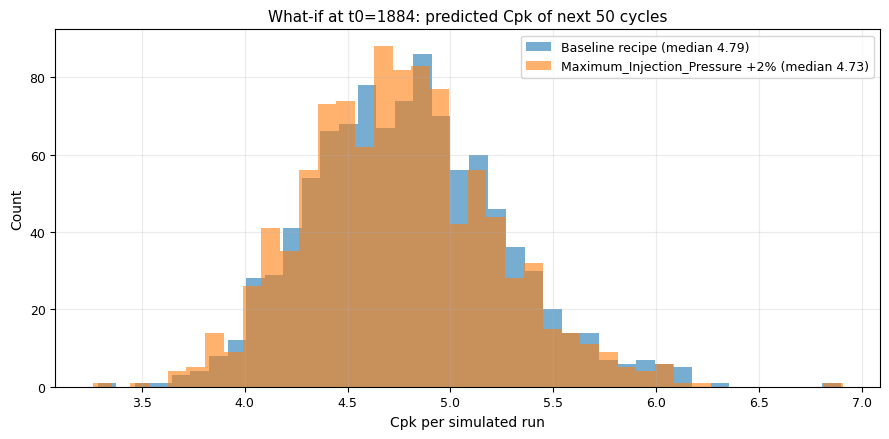

In [ ]:
# Compare baseline and perturbed-input forecasts from the same measured state.
# The result is model sensitivity, not a validated machine-setting intervention.
# The marginal training-range warning does not detect all joint extrapolation.

import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("forecast_outputs", exist_ok=True)

WHATIF_T0     = int(anchors_all[len(anchors_all) // 2])   # same anchor as the demo
WHATIF_FEATURE = "Maximum_Injection_Pressure"
WHATIF_PCT     = +0.02                                    # +2% from current setting
WHATIF_N_SIMS  = 1000
WHATIF_SEED    = 777

base = on_demand_forecast(WHATIF_T0, n_sims=WHATIF_N_SIMS, seed=WHATIF_SEED)
base_cpk = per_run_cpk(base["traj"], LSL, USL)

cur_val = base["recipe"][WHATIF_FEATURE]
new_val = cur_val * (1.0 + WHATIF_PCT)
mod = on_demand_forecast(WHATIF_T0, n_sims=WHATIF_N_SIMS, seed=WHATIF_SEED,
                           recipe_override={WHATIF_FEATURE: new_val}, verbose=True)
mod_cpk = per_run_cpk(mod["traj"], LSL, USL)

b05, b50, b95 = np.quantile(base_cpk, [0.05, 0.50, 0.95])
m05, m50, m95 = np.quantile(mod_cpk, [0.05, 0.50, 0.95])

print("=============== WHAT-IF (on-demand mode) ===============")
print(f"Anchor t0={WHATIF_T0} | {WHATIF_FEATURE}: {cur_val:.2f} -> {new_val:.2f} ({WHATIF_PCT*100:+.1f}%)")
print(f"Baseline  Cpk: median {b50:.3f}  90% PI [{b05:.3f}, {b95:.3f}]")
print(f"Modified  Cpk: median {m50:.3f}  90% PI [{m05:.3f}, {m95:.3f}]")
print(f"Predicted median Cpk shift: {m50 - b50:+.3f}")
for w in mod["warnings"]:
    print("WARNING:", w)
print("=====================================================")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(base_cpk, bins=40, alpha=0.6, color="#1F77B4",
        label=f"Baseline recipe (median {b50:.2f})")
ax.hist(mod_cpk, bins=40, alpha=0.6, color="#FF7F0E",
        label=f"{WHATIF_FEATURE} {WHATIF_PCT*100:+.0f}% (median {m50:.2f})")
ax.set_title(f"What-if at t0={WHATIF_T0}: predicted Cpk of next {OD_SIM_CYCLES} cycles")
ax.set_xlabel("Cpk per simulated run")
ax.set_ylabel("Count")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig("forecast_outputs/whatif_cpk_shift.png", dpi=600, bbox_inches="tight")
plt.show()


whatif_summary = {
    "anchor_t0": WHATIF_T0, "feature": WHATIF_FEATURE, "pct": WHATIF_PCT,
    "value_from": float(cur_val), "value_to": float(new_val),
    "baseline_cpk_median": float(b50), "baseline_cpk_pi": (float(b05), float(b95)),
    "modified_cpk_median": float(m50), "modified_cpk_pi": (float(m05), float(m95)),
    "median_shift": float(m50 - b50),
    "extrapolation_warnings": list(mod["warnings"]),
}


### Response curves and Cpk geometry

Compare the change in mean with the change in capability. At fixed dispersion, Cpk has a corner at the specification centre, with opposite one-sided slopes rather than a zero derivative.


Sweep at anchor t0=1884 | features ['Maximum_Injection_Pressure', 'Dosing_Time', 'Switch_Over_Pressure'] | 9 levels x 300 sims
  Maximum_Injection_Pressure done
  Dosing_Time done
  Switch_Over_Pressure done

--- WHAT-IF RESPONSE SWEEP ---
                   feature  pct      d_mu  pred_sigma  cpk_median     d_cpk  extrapolation
Maximum_Injection_Pressure -6.0  0.018025    0.021462    4.394136 -0.354725          False
Maximum_Injection_Pressure -4.0  0.011990    0.021260    4.531273 -0.217588          False
Maximum_Injection_Pressure -2.0  0.005969    0.021105    4.673042 -0.075819          False
Maximum_Injection_Pressure -1.0  0.002976    0.021046    4.727074 -0.021787          False
Maximum_Injection_Pressure  0.0  0.000000    0.021000    4.748861  0.000000          False
Maximum_Injection_Pressure  1.0 -0.002950    0.020966    4.744489 -0.004372          False
Maximum_Injection_Pressure  2.0 -0.005869    0.020943    4.714537 -0.034324          False
Maximum_Injection_Pressure  4.0 

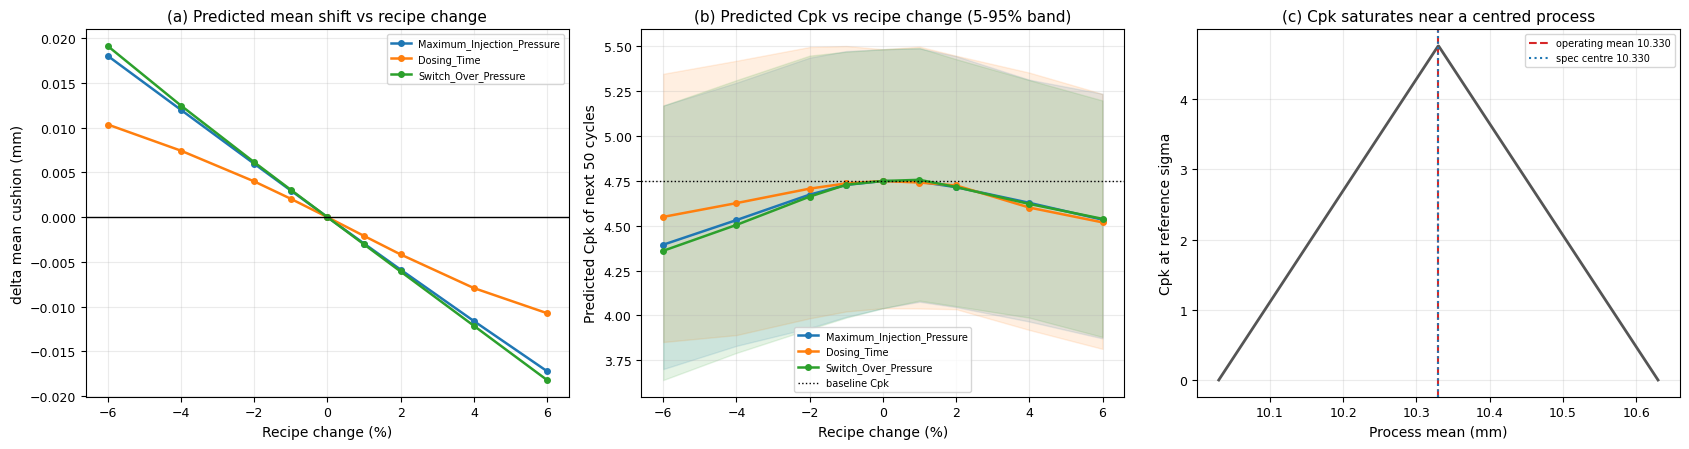

In [ ]:
# Sweep individual inputs and separate changes in mean from changes in Cpk.
# At fixed sigma, Cpk is piecewise linear in the mean and has a corner at the
# specification centre: its one-sided slopes are +/-1/(3*sigma), not zero.
# The sweep is observational-model sensitivity, not causal process validation.
# Some original printed labels describe saturation; the formula and this note
# give the intended interpretation.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("forecast_outputs", exist_ok=True)

SWEEP_T0      = int(anchors_all[len(anchors_all) // 2])   # same anchor as the demo
SWEEP_PCTS    = [-0.06, -0.04, -0.02, -0.01, 0.0, 0.01, 0.02, 0.04, 0.06]
SWEEP_N_SIMS  = 300
SWEEP_SEED    = 909
SWEEP_FEATURES = [f for f in ["Maximum_Injection_Pressure", "Dosing_Time",
                              "Switch_Over_Pressure", "Back_pressure_ActValue"]
                  if f in RECIPE_FEATURES][:3]

print(f"Sweep at anchor t0={SWEEP_T0} | features {SWEEP_FEATURES} "
      f"| {len(SWEEP_PCTS)} levels x {SWEEP_N_SIMS} sims")

_base = on_demand_forecast(SWEEP_T0, n_sims=SWEEP_N_SIMS, seed=SWEEP_SEED)
_base_recipe = _base["recipe"]
_base_cpk = float(np.median(per_run_cpk(_base["traj"], LSL, USL)))
_base_mu = float(_base["traj"].mean())

rows = []
for f in SWEEP_FEATURES:
    for p in SWEEP_PCTS:
        v = _base_recipe[f] * (1.0 + p)
        r = on_demand_forecast(SWEEP_T0, n_sims=SWEEP_N_SIMS, seed=SWEEP_SEED,
                                 recipe_override={f: v})
        cpk = per_run_cpk(r["traj"], LSL, USL)
        rows.append({
            "feature": f, "pct": p * 100, "value": v,
            "pred_mu": float(r["traj"].mean()),
            "d_mu": float(r["traj"].mean() - _base_mu),
            "pred_sigma": float(np.mean(r["traj"].std(axis=1, ddof=1))),
            "cpk_median": float(np.median(cpk)),
            "cpk_p05": float(np.quantile(cpk, 0.05)),
            "cpk_p95": float(np.quantile(cpk, 0.95)),
            "d_cpk": float(np.median(cpk) - _base_cpk),
            "extrapolation": len(r["warnings"]) > 0,
        })
    print(f"  {f} done")

sweep = pd.DataFrame(rows)
sweep.to_csv("forecast_outputs/whatif_sweep.csv", index=False)

print("\n--- WHAT-IF RESPONSE SWEEP ---")
print(sweep[["feature", "pct", "d_mu", "pred_sigma", "cpk_median", "d_cpk",
             "extrapolation"]].to_string(index=False))

_sig_ref = float(np.mean(_base["traj"].std(axis=1, ddof=1)))
_mu_grid = np.linspace(LSL + 1e-9, USL - 1e-9, 800)
_cpk_grid = np.minimum(USL - _mu_grid, _mu_grid - LSL) / (3.0 * _sig_ref)
_centre = 0.5 * (LSL + USL)
_slope = 1.0 / (3.0 * _sig_ref)          # |dCpk/dmu| away from the peak
_dist_from_centre = _base_mu - _centre
_frac_of_halfwidth = abs(_dist_from_centre) / (0.5 * (USL - LSL))

print("\n--- WHY delta-Cpk IS SMALL (Cpk geometry) ---")
print(f"  spec: LSL={LSL:.4f}  USL={USL:.4f}  centre={_centre:.4f}")
print(f"  predicted process mean       : {_base_mu:.4f}")
print(f"  distance from spec centre    : {_dist_from_centre:+.4f} "
      f"({_frac_of_halfwidth*100:.1f}% of the half-width)")
print(f"  reference within-window sigma: {_sig_ref:.4f}")
print(f"  |dCpk/dmu| away from the peak: {_slope:.1f} per mm  -> a mean shift of "
      f"{0.10/_slope:.4f} mm is needed to move Cpk by 0.10")
print(f"  Cpk at the peak (perfectly centred): {(0.5*(USL-LSL))/(3*_sig_ref):.3f}")

_max_dmu = float(sweep["d_mu"].abs().max())
print(f"\n  largest predicted mean shift in the sweep: {_max_dmu:.4f} mm "
      f"=> at most {_max_dmu*_slope:.3f} of Cpk change")
print("  CONCLUSION: the twin responds to the recipe through the MEAN; Cpk hides")
print("  that response because the process is near the Cpk maximum. Report d_mu as")
print("  the primary response, Cpk as the operational consequence.")

article_sentence = (
    f"At the operating point the process mean lies {abs(_dist_from_centre):.4f} mm from the "
    f"specification centre ({_frac_of_halfwidth*100:.1f}% of the half-width), i.e. near the maximum "
    f"of the Cpk(mu) function, where |dCpk/dmu| = {_slope:.1f} mm-1 is applied to shifts of order "
    f"{_max_dmu:.4f} mm. A recipe perturbation of a few percent therefore produces a measurable "
    f"shift of the predicted mean but a Cpk change of only ~{_max_dmu*_slope:.2f}. The apparent "
    f"insensitivity is a saturation property of the capability index near a centred process, not "
    f"an insensitivity of the twin."
)
print("\n--- ARTICLE-READY SENTENCE ---\n" + article_sentence)

whatif_sweep_summary = {
    "anchor_t0": SWEEP_T0, "features": SWEEP_FEATURES, "pcts": SWEEP_PCTS,
    "n_sims": SWEEP_N_SIMS, "baseline_cpk_median": _base_cpk, "baseline_mu": _base_mu,
    "sigma_ref": _sig_ref, "spec_centre": float(_centre),
    "dist_from_centre": float(_dist_from_centre),
    "frac_of_halfwidth": float(_frac_of_halfwidth),
    "dcpk_dmu": float(_slope), "max_abs_dmu": _max_dmu,
    "article_sentence": article_sentence,
}

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
_cols = {f: c for f, c in zip(SWEEP_FEATURES, ["#1F77B4", "#FF7F0E", "#2CA02C"])}

for f in SWEEP_FEATURES:
    s = sweep[sweep["feature"] == f].sort_values("pct")
    ax[0].plot(s["pct"], s["d_mu"], "o-", color=_cols[f], lw=1.8, ms=4, label=f)
    ax[1].plot(s["pct"], s["cpk_median"], "o-", color=_cols[f], lw=1.8, ms=4, label=f)
    ax[1].fill_between(s["pct"], s["cpk_p05"], s["cpk_p95"], color=_cols[f], alpha=0.12)

ax[0].axhline(0, color="black", lw=1); ax[0].grid(alpha=0.25)
ax[0].set_title("(a) Predicted mean shift vs recipe change")
ax[0].set_xlabel("Recipe change (%)"); ax[0].set_ylabel("delta mean cushion (mm)")
ax[0].legend(fontsize=7)

ax[1].axhline(_base_cpk, color="black", ls=":", lw=1, label="baseline Cpk")
ax[1].grid(alpha=0.25)
ax[1].set_title("(b) Predicted Cpk vs recipe change (5-95% band)")
ax[1].set_xlabel("Recipe change (%)"); ax[1].set_ylabel("Predicted Cpk of next 50 cycles")
ax[1].legend(fontsize=7)

ax[2].plot(_mu_grid, _cpk_grid, color="#555555", lw=2)
ax[2].axvline(_base_mu, color="#D62728", ls="--", lw=1.5,
              label=f"operating mean {_base_mu:.3f}")
ax[2].axvline(_centre, color="#1F77B4", ls=":", lw=1.5, label=f"spec centre {_centre:.3f}")
ax[2].set_title("(c) Cpk saturates near a centred process")
ax[2].set_xlabel("Process mean (mm)"); ax[2].set_ylabel("Cpk at reference sigma")
ax[2].legend(fontsize=7); ax[2].grid(alpha=0.25)

plt.tight_layout()
fig.savefig("forecast_outputs/whatif_sweep_and_cpk_geometry.png", dpi=600,
            bbox_inches="tight")
plt.show()

## Noise-component ablation and environment record

Compare no-noise, fast-noise and full-generator simulations. The environment record includes an illustrative synthetic generator, which cannot reproduce the industrial findings.


In [ ]:
# Compare a deterministic trajectory, fast-noise forecasts and the full generator.
# The table uses _deterministic_rollout for its no-noise reference.
# The unused _sim_variant helper still injects fast noise in its model_only branch.
# This experiment varies noise components; it does not independently ablate
# the predictor, estimator and validation procedure.

import numpy as np
import pandas as pd

ABLATION_N_SIMS = 400
ABLATION_ANCHORS = 15

_anchors = anchors_all[np.linspace(0, len(anchors_all) - 1, ABLATION_ANCHORS).round().astype(int)]
_anchors = np.unique(_anchors)

def _sim_variant(t0, mode):
    """Legacy variant helper; model_only still includes fast noise.
    The ablation table below uses _deterministic_rollout for the no-noise case."""
    if mode == "model_only":
        _sig_bak = globals().get("SLOW_SIGMA_BTN", 0.0)
        return on_demand_forecast(int(t0), n_sims=ABLATION_N_SIMS, seed=321,
                                    slow_sigma=0.0)["traj"], True   # fast residual noise remains active in this unused helper
    elif mode == "mc_raw":
        return on_demand_forecast(int(t0), n_sims=ABLATION_N_SIMS, seed=321,
                                    slow_sigma=0.0)["traj"], False
    else:
        return on_demand_forecast(int(t0), n_sims=ABLATION_N_SIMS, seed=321)["traj"], False

def _deterministic_rollout(t0):
    win = df_test_raw.iloc[t0 - SEQ_LEN:t0]
    seq = win[FEATURES].values.astype(np.float32)
    C_prev = float(win[TARGET_COL].values[-1])
    lo = max(0, t0 - OD_RECIPE_WIN); ctx = df_test_raw.iloc[lo:t0]
    recipe = {f: float(ctx[f].astype(float).mean()) for f in RECIPE_FEATURES}
    base = np.array([recipe.get(f, float(df_train_raw[f].astype(float).mean()))
                     for f in FEATURES], dtype=np.float32)
    _xc = np.asarray(x_scaler.center_, dtype=np.float32); _xs = np.asarray(x_scaler.scale_, np.float32)
    _dc = float(delta_scaler.center_[0]); _ds = float(delta_scaler.scale_[0])
    s = ((seq - _xc) / _xs).astype(np.float32)[None]
    st = torch.tensor(s, dtype=torch.float32, device=device)
    traj = []
    model.eval()
    with torch.no_grad():
        for _ in range(OD_SIM_CYCLES):
            o = model(st); o = o[:, 0] if o.ndim == 2 else o
            d = float(o.cpu().numpy().reshape(-1)[0]) * _ds + _dc + float(bias_res)
            C_prev = C_prev + d; traj.append(C_prev)
            nxt = base.copy(); nxt[cush_in_idx] = C_prev
            ns = torch.tensor(((nxt - _xc) / _xs)[None], dtype=torch.float32, device=device)
            st = torch.cat([st[:, 1:, :], ns[:, None, :]], dim=1)
    return np.array(traj, dtype=float)

rows = []
for _t0 in _anchors:
    det = _deterministic_rollout(int(_t0))
    raw = on_demand_forecast(int(_t0), n_sims=ABLATION_N_SIMS, seed=321, slow_sigma=0.0)["traj"]
    full = on_demand_forecast(int(_t0), n_sims=ABLATION_N_SIMS, seed=321)["traj"]

    for label, arr in [("A_model_only", det[None, :]),
                       ("B_model+MC_raw", raw),
                       ("C_full_framework", full)]:
        sig = float(np.mean(arr.std(axis=1, ddof=1)))
        st_ = compute_cp_cpk(arr.reshape(-1), LSL, USL)
        rows.append({"config": label, "sim_sigma": sig, "sim_Cp": st_["Cp"], "sim_Cpk": st_["Cpk"]})

ablation_df = pd.DataFrame(rows).groupby("config", as_index=False).mean(numeric_only=True)
_real_sig = float(np.mean([df_test_raw.iloc[int(t):int(t)+OD_SIM_CYCLES][TARGET_COL].astype(float).std(ddof=1)
                           for t in _anchors]))
print("Ablation of framework layers (means over anchors). Real within-window sigma:", round(_real_sig, 4))
display(ablation_df)
ablation_df.to_csv("ablation_layers.csv", index=False)
print("Reading: the model alone (A) collapses variance and overstates capability; "
      "adding calibrated stochastic layers (B->C) restores realistic dispersion.")


Ablation of framework layers (means over anchors). Real within-window sigma: 0.0181


,config,sim_sigma,sim_Cp,sim_Cpk
0,A_model_only,0.001505,147.961838,145.367318
1,B_model+MC_raw,0.015324,6.509916,6.374316
2,C_full_framework,0.020910,4.758402,4.655324


Reading: the model alone (A) collapses variance and overstates capability; adding calibrated stochastic layers (B->C) restores realistic dispersion.


In [ ]:
# Record the environment and define an illustrative synthetic generator.
# The generated data are not industrial measurements and do not reproduce the
# paper results, production segmentation or measured increment autocorrelation.
# Check column names and preprocessing before using them with this pipeline.
# The exported random_seed scalar is not a complete seed inventory: pipeline
# seed 42, reported training seed 123, and later stages use their own seeds.

import platform
import numpy as np
import pandas as pd

repro = {
    "random_seed": int(RANDOM_SEED) if "RANDOM_SEED" in globals() else 42,
    "python": platform.python_version(),
    "platform": platform.platform(),
}
try:
    import torch as _t
    repro["torch"] = _t.__version__
    repro["cuda_available"] = bool(_t.cuda.is_available())
    repro["device"] = (_t.cuda.get_device_name(0) if _t.cuda.is_available() else "cpu")
except Exception:
    pass
for _lib in ["numpy", "pandas", "sklearn", "scipy", "statsmodels", "shap"]:
    try:
        repro[_lib] = __import__(_lib).__version__
    except Exception:
        repro[_lib] = "not installed"
if "TRAINING_SECONDS" in globals():
    repro["training_seconds_total"] = float(TRAINING_SECONDS)

print("Reproducibility information:")
for _k, _v in repro.items():
    print(f"  {_k:24s}: {_v}")
pd.DataFrame([repro]).to_csv("reproducibility.csv", index=False)


def generate_synthetic_cushion(n_cycles=25000, seed=0):
    """Illustrative quantised cushion values with fast noise, slow drift and excursions.
    Recipe columns are synthetic constants with noise. The data do not reproduce
    the industrial record, its segment structure or the published forecast results.
    Column mapping and pipeline configuration must be checked before use."""
    rng = np.random.default_rng(seed)
    target = 10.33
    fast = rng.normal(0.0, 0.016, n_cycles)                       # within-window jitter
    slow = np.zeros(n_cycles)                                     # AR(1) slow drift
    phi, s_sig = 0.93, 0.016
    for t in range(1, n_cycles):
        slow[t] = phi * slow[t - 1] + s_sig * np.sqrt(1 - phi**2) * rng.normal()
    cushion = target + fast + slow
    anom_idx = rng.choice(n_cycles, size=int(0.003 * n_cycles), replace=False)
    cushion[anom_idx] -= rng.uniform(3.0, 6.0, size=len(anom_idx))
    cushion = np.round(cushion, 2)                               # sensor quantisation
    df = pd.DataFrame({
        "timestamp": pd.date_range("2026-01-01", periods=n_cycles, freq="15s"),
        "Maximum_Injection_Pressure": rng.normal(1531, 8, n_cycles),
        "SwitchOver_Pressure": rng.normal(1040, 6, n_cycles),
        "Injection_Time": rng.normal(0.86, 0.01, n_cycles),
        "Dosing_Time": rng.normal(2.9, 0.5, n_cycles),
        "Back_pressure": rng.normal(120, 3, n_cycles),
        "SwitchOver_volume": rng.normal(11.2, 0.1, n_cycles),
        "Dosing_Volume": rng.normal(31.5, 0.2, n_cycles),
        "Material_Cushion": cushion,
    })
    return df

print("\nSynthetic data generator ready: generate_synthetic_cushion(n_cycles, seed).")


Reproducibility information:
  random_seed             : 7
  python                  : 3.12.13
  platform                : Linux-6.6.122+-x86_64-with-glibc2.35
  torch                   : 2.11.0+cu128
  cuda_available          : True
  device                  : Tesla T4
  numpy                   : 2.0.2
  pandas                  : 2.2.2
  sklearn                 : 1.6.1
  scipy                   : 1.16.3
  statsmodels             : 0.14.6
  shap                    : 0.52.0
  training_seconds_total  : 49.790589332580566

Synthetic data generator ready: generate_synthetic_cushion(n_cycles, seed).


### Inference timing

Compare single-inference and complete-forecast latency with the nominal 15 s cycle. Measurements apply to the reported host, not an untested industrial PC.


In [ ]:
# Time a single model inference and a complete on-demand forecast on the
# current hardware. These measurements do not demonstrate production deployment.

import numpy as np
import time
import pandas as pd

CYCLE_TIME_S = 15.0
_best = model_comparison_df.iloc[0]["model"]
_mdl = experiment_models[_best]["model"]
_names = experiment_models[_best]["feature_names"]
_mdl.eval()

_x = torch.tensor(X_test[:1, :, :len(_names)], dtype=torch.float32, device=device)
with torch.no_grad():
    for _ in range(10):
        _ = _mdl(_x)
if device.type == "cuda":
    torch.cuda.synchronize()
_t0 = time.time()
_N = 200
with torch.no_grad():
    for _ in range(_N):
        _ = _mdl(_x)
if device.type == "cuda":
    torch.cuda.synchronize()
_single_ms = (time.time() - _t0) / _N * 1000.0

_anchor = int(anchors_all[len(anchors_all) // 2])
_t0 = time.time()
_ = on_demand_forecast(_anchor, n_sims=1000, seed=1)
_full_s = time.time() - _t0

latency_df = pd.DataFrame([
    {"operation": "Single one-step inference", "latency": f"{_single_ms:.3f} ms",
     "vs_cycle_time": f"{_single_ms/1000/CYCLE_TIME_S*100:.4f}% of {CYCLE_TIME_S:.0f}s"},
    {"operation": "Full on-demand MC forecast (1000 runs x horizon)", "latency": f"{_full_s:.2f} s",
     "vs_cycle_time": f"{_full_s/CYCLE_TIME_S*100:.1f}% of {CYCLE_TIME_S:.0f}s"},
])
print(f"Inference latency on {repro.get('device','device') if 'repro' in globals() else device}:")
display(latency_df)
latency_df.to_csv("inference_latency.csv", index=False)
_headroom = CYCLE_TIME_S / max(_full_s, 1e-9)
print(f"Headroom: the full forecast fits ~{_headroom:.0f}x within one cycle "
      f"-> ample margin for slower edge hardware.")


Inference latency on Tesla T4:


,operation,latency,vs_cycle_time
0,Single one-step inference,0.707 ms,0.0047% of 15s
1,Full on-demand MC forecast (1000 runs x horizon),0.14 s,0.9% of 15s


Headroom: the full forecast fits ~110x within one cycle -> ample margin for slower edge hardware.


In [ ]:
# Time single-step inference and a full forecast on one CPU thread.
# Results apply to the reported host; target industrial-PC latency was not measured.

import copy
import time
import numpy as np
import pandas as pd
import torch

CYCLE_TIME_S = 15.0
CPU_N_SIMS = int(globals().get("WF_N_SIMS", 1000))

_model_backup, _device_backup = model, device
_cpu_model = copy.deepcopy(model).to("cpu").eval()

try:
    globals()["model"] = _cpu_model
    globals()["device"] = torch.device("cpu")

    _x = torch.randn(1, SEQ_LEN, len(FEATURES), dtype=torch.float32)
    with torch.no_grad():
        for _ in range(10):
            _cpu_model(_x)
        _t0 = time.perf_counter()
        for _ in range(200):
            _cpu_model(_x)
        _one_step_ms = (time.perf_counter() - _t0) / 200 * 1000

    _t0 = time.perf_counter()
    _r = on_demand_forecast(int(anchors_all[len(anchors_all) // 2]),
                              n_sims=CPU_N_SIMS, seed=1234)
    _full_s = time.perf_counter() - _t0
finally:
    globals()["model"] = _model_backup
    globals()["device"] = _device_backup

_nthreads = torch.get_num_threads()
cpu_latency_tab = pd.DataFrame([
    {"Measurement": "Single one-step inference (CPU)", "Value": f"{_one_step_ms:.2f} ms"},
    {"Measurement": f"Full on-demand forecast, {CPU_N_SIMS} runs x {OD_SIM_CYCLES} cycles (CPU)",
     "Value": f"{_full_s:.2f} s"},
    {"Measurement": "Machine cycle time", "Value": f"{CYCLE_TIME_S:.0f} s"},
    {"Measurement": "Real-time margin", "Value": f"{CYCLE_TIME_S/_full_s:.1f}x"},
    {"Measurement": "CPU threads used", "Value": str(_nthreads)},
])
print("--- CPU-ONLY LATENCY (edge feasibility) ---")
print(cpu_latency_tab.to_string(index=False))
if _full_s < CYCLE_TIME_S:
    print(f"\n>>> A full forecast completes in {_full_s:.2f} s on CPU alone, "
          f"{CYCLE_TIME_S/_full_s:.1f}x inside one {CYCLE_TIME_S:.0f} s cycle: "
          f"the twin is deployable on an industrial PC with no accelerator.")
else:
    print(f"\n>>> {_full_s:.2f} s exceeds the {CYCLE_TIME_S:.0f} s cycle on CPU. "
          f"Reported with the available mitigation: fewer runs "
          f"({int(CPU_N_SIMS*CYCLE_TIME_S/_full_s*0.5)} runs would fit), or "
          f"forecasting on demand rather than every cycle.")
cpu_latency_tab.to_csv("cpu_latency.csv", index=False)
cpu_latency_summary = {"one_step_ms": float(_one_step_ms), "full_forecast_s": float(_full_s),
                       "n_sims": CPU_N_SIMS, "cycle_time_s": CYCLE_TIME_S,
                       "margin_x": float(CYCLE_TIME_S / _full_s), "threads": int(_nthreads)}

--- CPU-ONLY LATENCY (edge feasibility) ---
                                         Measurement   Value
                     Single one-step inference (CPU) 1.12 ms
Full on-demand forecast, 1000 runs x 50 cycles (CPU)  2.09 s
                                  Machine cycle time    15 s
                                    Real-time margin    7.2x
                                    CPU threads used       1

>>> A full forecast completes in 2.09 s on CPU alone, 7.2x inside one 15 s cycle: the twin is deployable on an industrial PC with no accelerator.


## Consolidated results

The following cells summarise existing result objects. Keep stationary, conditional and diagnostic configurations distinct when comparing their values.


In [ ]:
# Summarise record counts, split sizes and anomaly flags.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_days = sorted(set(pd.concat([df_train_raw, df_val_raw, df_test_raw])[TIMESTAMP_COL].dt.date))
card1_table = pd.DataFrame([
    {"Item": "Total cycles (after cleaning)", "Value": f"{len(df_train_raw)+len(df_val_raw)+len(df_test_raw):,}"},
    {"Item": "Production days covered", "Value": f"{len(_days)} ({_days[0]} → {_days[-1]})"},
    {"Item": "Machine segments (>180 s gaps)", "Value": f"{df_test_raw['segment'].nunique() + df_val_raw['segment'].nunique() + df_train_raw['segment'].nunique()} (train+val+test, may overlap)"},
    {"Item": "Split (train / val / test)", "Value": f"{len(df_train_raw):,} / {len(df_val_raw):,} / {len(df_test_raw):,}"},
    {"Item": "Spec limits (LSL, target, USL)", "Value": f"{LSL:.2f} / {TARGET_CUSHION:.2f} / {USL:.2f}"},
    {"Item": f"Anomalous cycles (|ΔC| > {ROBUST_K:.0f}×MAD)", "Value": " / ".join(str(anomaly_census["splits"][s]["anomalous_cycles"]) for s in ["train","val","test"])},
    {"Item": "Out-of-spec cycles", "Value": " / ".join(str(anomaly_census["splits"][s]["out_of_spec_cycles"]) for s in ["train","val","test"])},
    {"Item": "Bulk ΔC σ (anomalies excluded)", "Value": " / ".join(f'{anomaly_census["splits"][s]["sigma_dC_bulk"]:.4f}' for s in ["train","val","test"])},
])
print("SUMMARY 1 — Data & quality  (values: train / val / test)")
display(card1_table)
card1_table.to_csv("summary_card1_data_quality.csv", index=False)
print("Reading: bulk process noise is comparable across splits; rare anomalous cycles "
      "(process incidents) are counted here and excluded from the simulation noise pool.")


SUMMARY 1 — Data & quality  (values: train / val / test)


,Item,Value
0,Total cycles (after cleaning),"25,767"
1,Production days covered,8 (2026-01-01 → 2026-01-24)
2,Machine segments (>180 s gaps),"19 (train+val+test, may overlap)"
3,Split (train / val / test),"18,033 / 3,867 / 3,867"
4,"Spec limits (LSL, target, USL)",10.03 / 10.33 / 10.63
5,Anomalous cycles (|ΔC| > 5×MAD),80 / 21 / 3
6,Out-of-spec cycles,34 / 12 / 0
7,Bulk ΔC σ (anomalies excluded),0.0201 / 0.0233 / 0.0236


Reading: bulk process noise is comparable across splits; rare anomalous cycles (process incidents) are counted here and excluded from the simulation noise pool.


In [ ]:
# Summarise the temporal-model benchmark from stored results.

import numpy as np
import pandas as pd

req = ["exp_results", "uncertainty_results", "score_df"]
missing = [r for r in req if r not in globals()]
if missing:
    raise RuntimeError(
        f"Missing objects {missing}. Run Phase 2 cells (Model Selection Experiment) before this section."
    )

rows = []
for model_name in score_df["model"].tolist():
    er = exp_results[model_name]
    ur = uncertainty_results[model_name]

    rows.append({
        "Model": model_name,
        "Rollout_RMSE": float(er["rollout_rmse"]),
        "Recipe_Sensitivity_Score": float(er["sensitivity_score"]),
        "Conformal_Coverage": float(ur["conformal"]["coverage"]),
        "Conformal_AvgWidth": float(ur["conformal"]["avg_width"]),
        "MCRes_Coverage": float(ur["monte_carlo_resid"]["coverage"]),
        "MCRes_AvgWidth": float(ur["monte_carlo_resid"]["avg_width"]),
        "Selected_Uncertainty": str(score_df.loc[score_df["model"] == model_name, "best_uncertainty"].iloc[0]),
        "Final_Score": float(score_df.loc[score_df["model"] == model_name, "final_score"].iloc[0]),
    })

table_model_perf = pd.DataFrame(rows).sort_values("Final_Score", ascending=False).reset_index(drop=True)

print("SUMMARY 2 — Temporal engine benchmark (Table A): TCN vs GRU vs LSTM")
display(table_model_perf)


SUMMARY 2 — Temporal engine benchmark (Table A): TCN vs GRU vs LSTM


,Model,Rollout_RMSE,Recipe_Sensitivity_Score,Conformal_Coverage,Conformal_AvgWidth,MCRes_Coverage,MCRes_AvgWidth,Selected_Uncertainty,Final_Score
0,TCN,0.013828,0.077300,0.909091,0.047241,0.911187,0.047322,conformal,0.995879
1,LSTM,0.014480,0.070049,0.904637,0.047314,0.906733,0.046941,conformal,0.594983
2,GRU,0.014867,0.052533,0.910925,0.046989,0.904113,0.046403,monte_carlo_resid,0.196699


SUMMARY 3 — Noise generator: calibration (validation residuals, robust-trimmed) & distributional validation


,Item,Value
0,Residual pool (raw → cleaned),3842 → 3818 (24 anomalous residuals removed)
1,Residual σ (raw → cleaned),0.1334 → 0.0146
2,Residual persistence ρ (estimated),-0.099
3,Two-timescale fit: σ_fast / σ_slow (level),0.0152 / 0.0159
4,Sound-check stationary: damping / injected σ,0.32 / 0.0495
5,Slow-wander inertia φ (per cycle),0.9269
6,Δ clamp (q=0.995 of clean pool),0.0378
7,Simulated vs real σ (values),0.0207 vs 0.0224
8,Simulated vs real σ (ΔC dynamics),0.0249 vs 0.0237
9,Cohen's d (values / ΔC),-0.034 / +0.001


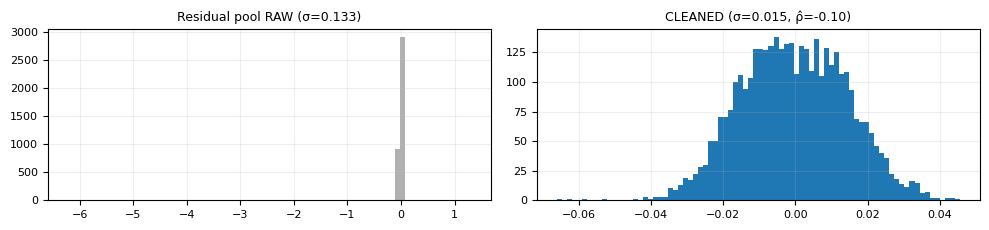

In [ ]:
# Summarise noise calibration and stationary validation.
# Distinguish the validation-fitted slow target from the compensated injection scale.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

nc = noise_calibration_summary
gv = generator_validation_summary

card3_table = pd.DataFrame([
    {"Item": "Residual pool (raw → cleaned)", "Value": f"{nc['pool_n_raw']} → {nc['pool_n_clean']}  ({nc['n_trimmed']} anomalous residuals removed)"},
    {"Item": "Residual σ (raw → cleaned)", "Value": f"{nc['sigma_raw']:.4f} → {nc['sigma_clean']:.4f}"},
    {"Item": "Residual persistence ρ (estimated)", "Value": f"{nc['ar1_rho_estimated']:+.3f}"},
    {"Item": "Two-timescale fit: σ_fast / σ_slow (level)", "Value": f"{nc.get('sigma_fast_level', float('nan')):.4f} / {nc.get('sigma_slow_level', float('nan')):.4f}"},
    {"Item": "Sound-check stationary: damping / injected σ", "Value": f"{nc.get('closed_loop_damping', float('nan')):.2f} / {nc.get('sigma_slow_injected', float('nan')):.4f}"},
    {"Item": "Slow-wander inertia φ (per cycle)", "Value": f"{nc.get('phi_slow', float('nan')):.4f}"},
    {"Item": "Δ clamp (q={:.3f} of clean pool)".format(DELTA_CLAMP_Q), "Value": f"{nc['delta_clamp_abs']:.4f}"},
    {"Item": "Simulated vs real σ (values)", "Value": f"{gv['mc_sigma']:.4f} vs {gv['test_sigma']:.4f}"},
    {"Item": "Simulated vs real σ (ΔC dynamics)", "Value": f"{gv['mc_dsigma']:.4f} vs {gv['test_dsigma']:.4f}"},
    {"Item": "Cohen's d (values / ΔC)", "Value": f"{gv['cohen_d_values']:+.3f} / {gv['cohen_d_deltas']:+.3f}"},
    {"Item": "KS D (values / ΔC)", "Value": f"{gv['ks_D_values']:.3f} / {gv['ks_D_deltas']:.3f}  (quantized 0.01 readings inflate KS)"},
    {"Item": "Envelope point-wise coverage", "Value": f"{gv['pointwise_envelope_coverage']*100:.1f}%  (target ≈ 90%)"},
])
print("SUMMARY 3 — Noise generator: calibration (validation residuals, robust-trimmed) & distributional validation")
display(card3_table)
card3_table.to_csv("summary_card3_noise_generator.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(10, 2.4), sharey=False)
ax[0].hist(residual_pool_raw, bins=80, color="#B0B0B0"); ax[0].set_title(f"Residual pool RAW (σ={nc['sigma_raw']:.3f})", fontsize=9)
ax[1].hist(residual_pool, bins=80, color="#1F77B4");     ax[1].set_title(f"CLEANED (σ={nc['sigma_clean']:.3f}, ρ̂={nc['ar1_rho_estimated']:+.2f})", fontsize=9)
for a in ax: a.grid(alpha=0.2); a.tick_params(labelsize=8)
plt.tight_layout(); plt.savefig("residual_pool_raw_vs_clean.png", dpi=600, bbox_inches="tight")
plt.show()


In [ ]:
# Summarise stationary capability against measured test-partition capability.
# Keep this aggregation scope separate from within-window conditional capability.

import numpy as np
import pandas as pd
import torch

req = [
    "compute_cp_cpk", "df_test_raw", "TARGET_COL", "LSL", "USL", "FEATURES", "SEQ_LEN",
    "x_scaler", "delta_scaler", "val_loader", "device", "feature_sigma",
    "N_SIMS", "SIM_CYCLES", "BURN_IN", "NOISE_SCALE", "USE_FEATURE_NOISE", "USE_RESIDUAL_NOISE",
    "USE_EMPIRICAL_RESID", "USE_AR1_RESIDUAL", "AR1_RHO", "USE_DELTA_CLAMP", "USE_CUSHION_CLAMP",
    "CUSH_MIN", "CUSH_MAX", "INIT_MODE", "df_train_raw", "RECIPE_REAL", "experiment_models"
]
missing = [r for r in req if r not in globals()]
if missing:
    raise RuntimeError(
        f"Missing objects {missing}. Run Phase 2-4 evaluation cells before this section."
    )

candidate_models = {name: info["model"] for name, info in experiment_models.items()}
if len(candidate_models) == 0:
    raise RuntimeError("No trained models found in experiment_models.")

cush_in_idx = FEATURES.index("Cushion_in")


def _pred_delta_scaled(model_in, xb):
    out = model_in(xb)
    if out.ndim == 2:
        out = out[:, 0]
    elif out.ndim > 2:
        out = out.reshape(out.shape[0], -1)[:, 0]
    return out


def _calibrate_residuals(model_in, loader):
    model_in.eval()
    p_all, t_all = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            preds = model_in(xb)

            if preds.ndim == 1:
                preds = preds.unsqueeze(1)
            if yb.ndim == 1:
                yb = yb.unsqueeze(1)

            p1 = preds[:, 0].detach().cpu().numpy().reshape(-1, 1)
            t1 = yb[:, 0].detach().cpu().numpy().reshape(-1, 1)

            p_all.append(p1)
            t_all.append(t1)

    p_s = np.vstack(p_all)
    t_s = np.vstack(t_all)
    p_r = delta_scaler.inverse_transform(p_s).ravel().astype(np.float32)
    t_r = delta_scaler.inverse_transform(t_s).ravel().astype(np.float32)
    resid_raw = (t_r - p_r).astype(np.float32)
    _thr = ROBUST_K * mad_sigma(resid_raw)
    resid = resid_raw[np.abs(resid_raw) <= _thr].astype(np.float32)
    sigma = float(np.std(resid, ddof=1))
    bias = float(np.mean(resid))
    clamp = float(np.quantile(np.abs(resid), 0.995)) if len(resid) > 0 else 0.0
    return resid, sigma, bias, clamp


if "scale_x_fast" not in globals() or "delta_scaled_to_real_fast" not in globals():
    _x_mean = getattr(x_scaler, "center_", getattr(x_scaler, "mean_", None))  # _x_scale = getattr(x_scaler, "scale_", None)

    def scale_x_fast(x_real: np.ndarray) -> np.ndarray:
        if _x_mean is not None and _x_scale is not None:
            return ((x_real - _x_mean) / _x_scale).astype(np.float32)
        import pandas as pd
        shp = x_real.shape
        x2 = x_real.reshape(-1, shp[-1])
        x2s = x_scaler.transform(pd.DataFrame(x2, columns=FEATURES)).astype(np.float32)
        return x2s.reshape(*shp)

    _d_mean = float(getattr(delta_scaler, "center_", getattr(delta_scaler, "mean_", [0.0]))[0])  # _d_scale = float(getattr(delta_scaler, "scale_", [1.0])[0])

    def delta_scaled_to_real_fast(d_scaled: np.ndarray) -> np.ndarray:
        return d_scaled * _d_scale + _d_mean


def _run_mc(model_in, sigma_res, bias_res, residual_pool, clamp_abs):
    n_runs = int(N_SIMS)
    steps = int(SIM_CYCLES)
    n_feat = len(FEATURES)

    if INIT_MODE == "test_mean":
        c0 = float(df_test_raw[TARGET_COL].astype(float).mean())
    elif INIT_MODE == "train_mean":
        c0 = float(df_train_raw[TARGET_COL].astype(float).mean())
    elif INIT_MODE == "last_train":
        c0 = float(df_train_raw[TARGET_COL].astype(float).iloc[-1])
    elif INIT_MODE == "custom":
        c0 = float(INIT_CUSHION_REAL)
    else:
        raise ValueError("INIT_MODE invalid")

    base_row = np.zeros((n_feat,), dtype=np.float32)
    for i, f in enumerate(FEATURES):
        if f == "Cushion_in":
            base_row[i] = c0
        elif f in RECIPE_REAL:
            base_row[i] = float(RECIPE_REAL[f])
        elif f in df_train_raw.columns:
            base_row[i] = float(df_train_raw[f].astype(float).mean())
        else:
            base_row[i] = 0.0

    sigma_vec = np.array([float(feature_sigma.get(f, 0.0)) for f in FEATURES], dtype=np.float32)
    sigma_vec[cush_in_idx] = 0.0
    sigma_vec *= float(NOISE_SCALE)

    seq_real = np.tile(base_row, (n_runs, SEQ_LEN, 1)).astype(np.float32)
    seq_real[:, :, cush_in_idx] = c0
    if USE_FEATURE_NOISE and np.any(sigma_vec > 0):
        seq_real += np.random.normal(0.0, sigma_vec, size=seq_real.shape).astype(np.float32)

    seq_scaled = scale_x_fast(seq_real)
    seq_t = torch.from_numpy(seq_scaled).to(device=device, dtype=torch.float32)

    c_prev = torch.full((n_runs,), float(c0), device=device, dtype=torch.float32)
    traj = np.empty((n_runs, steps), dtype=np.float32)
    base_row_batch = np.tile(base_row, (n_runs, 1)).astype(np.float32)
    e_prev = np.zeros((n_runs,), dtype=np.float32)
    if 'USE_SLOW_NOISE' in globals() and USE_SLOW_NOISE:
        s_prev = np.random.normal(0.0, SLOW_SIGMA, size=(n_runs,)).astype(np.float32)
    else:
        s_prev = np.zeros((n_runs,), dtype=np.float32)

    model_in.eval()
    with torch.no_grad():
        for k in range(steps):
            d_s = _pred_delta_scaled(model_in, seq_t).detach().cpu().numpy().astype(np.float32)
            d_r = delta_scaled_to_real_fast(d_s)
            d_r += float(bias_res)

            if USE_RESIDUAL_NOISE and sigma_res > 0:
                if USE_EMPIRICAL_RESID and residual_pool is not None and len(residual_pool) > 100:
                    e = np.random.choice(residual_pool, size=n_runs, replace=True).astype(np.float32)
                else:
                    e = np.random.normal(0.0, float(sigma_res), size=(n_runs,)).astype(np.float32)
                e *= float(NOISE_SCALE)

                if USE_AR1_RESIDUAL:
                    rho = float(AR1_RHO)
                    e = rho * e_prev + np.sqrt(max(1e-8, 1.0 - rho * rho)) * e
                    e_prev = e

                d_r += e

            if 'USE_SLOW_NOISE' in globals() and USE_SLOW_NOISE:
                s_new = SLOW_PHI * s_prev + SLOW_SIGMA * np.sqrt(1.0 - SLOW_PHI**2) * \
                        np.random.normal(0.0, 1.0, size=(n_runs,)).astype(np.float32)
                d_r += (s_new - s_prev)
                s_prev = s_new

            if USE_DELTA_CLAMP:
                cabs = float(clamp_abs) * float(NOISE_SCALE)
                d_r = np.clip(d_r, -cabs, cabs)

            d_t = torch.from_numpy(d_r).to(device=device, dtype=torch.float32)
            c_next = c_prev + d_t
            if USE_CUSHION_CLAMP:
                c_next = torch.clamp(c_next, float(CUSH_MIN), float(CUSH_MAX))

            traj[:, k] = c_next.detach().cpu().numpy()

            next_row = base_row_batch.copy()
            if USE_FEATURE_NOISE and np.any(sigma_vec > 0):
                next_row += np.random.normal(0.0, sigma_vec, size=(n_runs, n_feat)).astype(np.float32)
            next_row[:, cush_in_idx] = traj[:, k]

            next_scaled = scale_x_fast(next_row)
            next_t = torch.from_numpy(next_scaled).to(device=device, dtype=torch.float32)
            seq_t[:, :-1, :] = seq_t[:, 1:, :]
            seq_t[:, -1, :] = next_t
            c_prev = c_next

    return traj[:, BURN_IN:] if BURN_IN > 0 else traj


real_samples = df_test_raw[TARGET_COL].astype(float).dropna().values
real_stats = compute_cp_cpk(real_samples, LSL, USL)

rows = [{
    "Source": "REAL_TEST",
    "Mean": float(real_stats["mu"]),
    "Sigma": float(real_stats["sigma"]),
    "Cp": float(real_stats["Cp"]),
    "Cpk": float(real_stats["Cpk"]),
    "Out_of_Spec_%": float(real_stats["P_out"] * 100.0),
}]

for name, mdl in candidate_models.items():
    resid, sigma, bias, clamp = _calibrate_residuals(mdl, val_loader)  # validation, not test (leakage)
    runs_local = _run_mc(mdl, sigma, bias, resid, clamp)
    st = compute_cp_cpk(runs_local.reshape(-1), LSL, USL)
    rows.append({
        "Source": f"MC_{name}",
        "Mean": float(st["mu"]),
        "Sigma": float(st["sigma"]),
        "Cp": float(st["Cp"]),
        "Cpk": float(st["Cpk"]),
        "Out_of_Spec_%": float(st["P_out"] * 100.0),
    })

table_capability = pd.DataFrame(rows)
print("SUMMARY 4 — Stationary virtual SPC vs real test process (Table B; residuals VAL-calibrated, robust-trimmed)")
display(table_capability)


SUMMARY 4 — Stationary virtual SPC vs real test process (Table B; residuals VAL-calibrated, robust-trimmed)


,Source,Mean,Sigma,Cp,Cpk,Out_of_Spec_%
0,REAL_TEST,10.335669,0.023551,4.246037,4.165808,0.0
1,MC_TCN,10.333534,0.020659,4.840608,4.783582,0.0
2,MC_GRU,10.335854,0.020831,4.800488,4.706816,0.0
3,MC_LSTM,10.335619,0.020832,4.800340,4.710426,0.0


SUMMARY 5 — Digital-twin validation (walk-forward cycle-by-cycle coverage)


,Metric,Value
0,Anchors x sims,100 x 1000
1,Horizon (cycles),50
2,Cycle-by-cycle coverage (nominal 90%),87.4%
3,Coverage Wilson 95% CI,"[86.4%, 88.3%]"
4,Mean |mu error|,0.0095
5,Within-window sigma bias,+0.0032 (+21.5%)


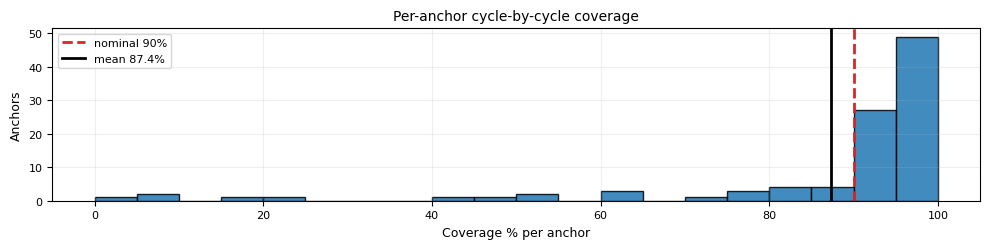

In [ ]:
# Summarise the final cycle-level audit.
# The Wilson interval is descriptive under overlapping origins.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "validation_summary" not in globals():
    raise RuntimeError("Run Phase 4 (walk-forward cycle coverage) first.")
vs = validation_summary
card5_table = pd.DataFrame([
    {"Metric": "Anchors x sims", "Value": f"{vs['n_anchors']} x {vs['n_sims']}"},
    {"Metric": "Horizon (cycles)", "Value": f"{OD_SIM_CYCLES}"},
    {"Metric": "Cycle-by-cycle coverage (nominal 90%)", "Value": f"{vs['cycle_coverage']*100:.1f}%"},
    {"Metric": "Coverage Wilson 95% CI", "Value": f"[{vs['coverage_ci'][0]*100:.1f}%, {vs['coverage_ci'][1]*100:.1f}%]"},
    {"Metric": "Mean |mu error|", "Value": f"{vs['mu_mae']:.4f}"},
    {"Metric": "Within-window sigma bias", "Value": f"{vs['sigma_bias']:+.4f} ({vs['sigma_rel_pct']:+.1f}%)"},
])
print("SUMMARY 5 — Digital-twin validation (walk-forward cycle-by-cycle coverage)")
display(card5_table)
card5_table.to_csv("summary_card5_validation.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 2.6))
ax.hist(wf["cycle_coverage"] * 100, bins=20, color="#1F77B4", edgecolor="black", alpha=0.85)
ax.axvline(90, color="#D62728", ls="--", lw=2, label="nominal 90%")
ax.axvline(vs["cycle_coverage"]*100, color="black", lw=2, label=f"mean {vs['cycle_coverage']*100:.1f}%")
ax.set_title("Per-anchor cycle-by-cycle coverage", fontsize=10)
ax.set_xlabel("Coverage % per anchor", fontsize=9); ax.set_ylabel("Anchors", fontsize=9)
ax.legend(fontsize=8); ax.grid(alpha=0.2); ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()


In [ ]:
# Summarise the input-sensitivity scenario and selected study results.

import numpy as np
import pandas as pd

ws = whatif_summary
card6_whatif = pd.DataFrame([
    {"Item": "Scenario", "Value": f"{ws['feature']} {ws['pct']*100:+.1f}%  ({ws['value_from']:.1f} → {ws['value_to']:.1f}) from real state t0={ws['anchor_t0']}"},
    {"Item": "Baseline Cpk (median, 90% PI)", "Value": f"{ws['baseline_cpk_median']:.3f}  [{ws['baseline_cpk_pi'][0]:.2f}, {ws['baseline_cpk_pi'][1]:.2f}]"},
    {"Item": "Modified Cpk (median, 90% PI)", "Value": f"{ws['modified_cpk_median']:.3f}  [{ws['modified_cpk_pi'][0]:.2f}, {ws['modified_cpk_pi'][1]:.2f}]"},
    {"Item": "Predicted median Cpk shift", "Value": f"{ws['median_shift']:+.3f}"},
    {"Item": "Extrapolation warnings", "Value": "; ".join(ws['extrapolation_warnings']) if ws['extrapolation_warnings'] else "none (recipe inside training domain)"},
])
print("SUMMARY 6a — What-if scenario (on-demand mode)")
display(card6_whatif)

best_row = table_model_perf.iloc[0]
best_model = str(best_row["Model"])
summary_rows = [
    {"Item": "Best temporal engine", "Value": best_model},
    {"Item": "Rollout RMSE (test)", "Value": f"{float(best_row['Rollout_RMSE']):.5f}"},
    {"Item": "Uncertainty method", "Value": str(best_row["Selected_Uncertainty"])},
    {"Item": "Residual pool cleaning", "Value": f"{noise_calibration_summary['n_trimmed']} anomalous residuals removed (generic {ROBUST_K:.0f}×MAD rule)"},
    {"Item": "Residual persistence ρ (estimated)", "Value": f"{noise_calibration_summary['ar1_rho_estimated']:+.3f}"},
    {"Item": "Slow wander: σ target / φ (variogram fit)", "Value": f"{noise_calibration_summary.get('sigma_slow_target', float('nan')):.4f} / {noise_calibration_summary.get('phi_slow', float('nan')):.4f}"},
    {"Item": "Stationary: damping / injected σ_slow", "Value": f"{noise_calibration_summary.get('closed_loop_damping', float('nan')):.2f} / {noise_calibration_summary.get('sigma_slow_injected', float('nan')):.4f}"},
]
cap_row = table_capability.loc[table_capability["Source"] == f"MC_{best_model}"]
real_row = table_capability.loc[table_capability["Source"] == "REAL_TEST"]
if len(cap_row) == 1 and len(real_row) == 1:
    r, rr = cap_row.iloc[0], real_row.iloc[0]
    summary_rows += [
        {"Item": "Stationary σ: simulated vs real", "Value": f"{float(r['Sigma']):.4f} vs {float(rr['Sigma']):.4f}"},
        {"Item": "Stationary Cpk: simulated vs real", "Value": f"{float(r['Cpk']):.3f} vs {float(rr['Cpk']):.3f}"},
    ]
if "validation_summary" in globals():
    vs = validation_summary
    summary_rows.append({"Item": "Validation anchors x sims", "Value": f"{vs['n_anchors']} x {vs['n_sims']}"})
    summary_rows.append({"Item": "Cycle-by-cycle coverage (nominal 90%)", "Value": f"{vs['cycle_coverage']*100:.1f}%"})
    summary_rows.append({"Item": "Within-window sigma bias", "Value": f"{vs['sigma_rel_pct']:+.1f}%"})
    summary_rows.append({"Item": "Mean |mu error|", "Value": f"{vs['mu_mae']:.4f}"})

summary_table = pd.DataFrame(summary_rows)
print("\nCARD 6b — Executive summary (Table C, article-ready)")
display(summary_table)
summary_table.to_csv("summary_card6_executive.csv", index=False)


SUMMARY 6a — What-if scenario (on-demand mode)


,Item,Value
0,Scenario,Maximum_Injection_Pressure +2.0% (1603.3 → 16...
1,"Baseline Cpk (median, 90% PI)","4.785 [4.08, 5.61]"
2,"Modified Cpk (median, 90% PI)","4.734 [4.05, 5.55]"
3,Predicted median Cpk shift,-0.051
4,Extrapolation warnings,none (recipe inside training domain)



CARD 6b — Executive summary (Table C, article-ready)


,Item,Value
0,Best temporal engine,TCN
1,Rollout RMSE (test),0.01383
2,Uncertainty method,conformal
3,Residual pool cleaning,24 anomalous residuals removed (generic 5×MAD ...
4,Residual persistence ρ (estimated),-0.099
5,Slow wander: σ target / φ (variogram fit),0.0159 / 0.9269
6,Stationary: damping / injected σ_slow,0.32 / 0.0495
7,Stationary σ: simulated vs real,0.0207 vs 0.0236
8,Stationary Cpk: simulated vs real,4.784 vs 4.166
9,Validation anchors x sims,100 x 1000


### Results export

Collect available result objects into JSON. Objects from unexecuted producer cells are marked as absent.


In [ ]:
# Export available result objects to JSON and print a compact summary.
# Missing producer objects are recorded as absent rather than recomputed.

import json
import numpy as np
import pandas as pd

def _g(name, default="NOT RUN"):
    return globals().get(name, default)

def _num(x, nd=4):
    try:
        return round(float(x), nd)
    except Exception:
        return x

A = {}

A["dataset"] = {
    "cycles_total": int(len(df_train_raw) + len(df_val_raw) + len(df_test_raw)),
    "split_train_val_test": [len(df_train_raw), len(df_val_raw), len(df_test_raw)],
    "features": list(FEATURES),
    "target": TARGET_COL,
    "seq_len": int(SEQ_LEN),
    "LSL": _num(LSL), "USL": _num(USL),
}

for _n in ["table_to_export", "model_comparison_df", "score_df"]:
    if _n in globals() and isinstance(globals()[_n], pd.DataFrame):
        A["benchmark_table"] = globals()[_n].to_dict(orient="records")
        break
else:
    A["benchmark_table"] = "NOT RUN"
A["best_model"] = str(_g("best_model_name"))
A["model_selection"] = _g("model_selection_summary")
A["architecture_paired_tests"] = _g("architecture_paired_df")
if isinstance(A["architecture_paired_tests"], pd.DataFrame):
    A["architecture_paired_tests"] = A["architecture_paired_tests"].to_dict(orient="records")
A["uncertainty_methods"] = _g("uncertainty_table_df")
if isinstance(A["uncertainty_methods"], pd.DataFrame):
    A["uncertainty_methods"] = A["uncertainty_methods"].to_dict(orient="records")
A["feature_importance"] = _g("perm_df")
if isinstance(A["feature_importance"], pd.DataFrame):
    A["feature_importance"] = A["feature_importance"].to_dict(orient="records")
A["rmse_vs_horizon"] = _g("horizon_df")
if isinstance(A["rmse_vs_horizon"], pd.DataFrame):
    A["rmse_vs_horizon"] = A["rmse_vs_horizon"].round(5).to_dict()
A["hyperparameter_sensitivity"] = _g("sensitivity_df")
if isinstance(A["hyperparameter_sensitivity"], pd.DataFrame):
    A["hyperparameter_sensitivity"] = A["hyperparameter_sensitivity"].to_dict(orient="records")
A["capability_bootstrap_CIs"] = _g("capability_ci_df")
if isinstance(A["capability_bootstrap_CIs"], pd.DataFrame):
    A["capability_bootstrap_CIs"] = A["capability_bootstrap_CIs"].to_dict(orient="records")
A["effect_size_overlap"] = _g("effect_df")
if isinstance(A["effect_size_overlap"], pd.DataFrame):
    A["effect_size_overlap"] = A["effect_size_overlap"].to_dict(orient="records")
A["overlap_diagnostics"] = _g("overlap_summary")
A["stationary_capability_table"] = _g("table_capability")
if isinstance(A["stationary_capability_table"], pd.DataFrame):
    A["stationary_capability_table"] = A["stationary_capability_table"].to_dict(orient="records")

A["baselines"] = _g("baseline_results")
if isinstance(A["baselines"], pd.DataFrame):
    A["baselines"] = A["baselines"].to_dict(orient="records")
A["diebold_mariano"] = _g("baseline_comparison_df")
if isinstance(A["diebold_mariano"], pd.DataFrame):
    A["diebold_mariano"] = A["diebold_mariano"].to_dict(orient="records")

A["two_timescale_noise"] = _g("noise_calibration_summary")
A["noise_calibration"] = {
    "residual_pool_n": int(len(residual_pool)) if "residual_pool" in globals() else "NOT RUN",
    "sigma_res": _num(_g("sigma_res"), 6),
    "bias_res": _num(_g("bias_res"), 6),
    "AR1_RHO": _num(_g("AR1_RHO"), 3),
    "delta_clamp_abs": _num(_g("delta_clamp_abs"), 6),
    "sigma_fast_level": _num(_g("SIGMA_FAST_LEVEL", _g("sigma_fast")), 4),
    "sigma_slow_target": _num(_g("SLOW_SIGMA_TARGET"), 4),
    "phi_slow": _num(_g("SLOW_PHI"), 4),
    "sigma_slow_injected_stationary": _num(_g("SLOW_SIGMA"), 4),
    "closed_loop_damping": _num(_g("ATTENUATION"), 3),
    "calibrated_on": "validation loader (no test leakage)",
}
A["two_rho"] = _g("acf_summary")

for _n in ["generator_validation_summary", "compat_summary", "mc_summary"]:
    if _n in globals():
        A["stationary_validation"] = globals()[_n]
        break
else:
    A["stationary_validation"] = "NOT RUN"

A["calibration_diagnostic"] = _g("diag_summary")
A["walk_forward_final"] = _g("validation_summary")

A["single_anchor_demo"] = _g("demo_summary", _g("button_demo_summary"))
A["whatif_single"] = _g("whatif_summary")
A["whatif_sweep"] = _g("whatif_sweep_summary")

A["ablation"] = _g("ablation_df")
if isinstance(A["ablation"], pd.DataFrame):
    A["ablation"] = A["ablation"].to_dict(orient="records")
A["latency_gpu_or_host"] = _g("latency_df")
if isinstance(A["latency_gpu_or_host"], pd.DataFrame):
    A["latency_gpu_or_host"] = A["latency_gpu_or_host"].to_dict(orient="records")
A["latency_cpu"] = _g("cpu_latency_summary")
A["reproducibility"] = _g("repro")

def _default(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, (np.ndarray,)):
        return o.tolist()
    if isinstance(o, pd.DataFrame):
        return o.to_dict(orient="records")
    return str(o)

with open("article_numbers_V4.json", "w") as fh:
    json.dump(A, fh, indent=2, default=_default)

print("=" * 66)
print("ARTICLE NUMBERS —  EXPORT  ->  article_numbers_V4.json")
print("=" * 66)

_missing = [k for k, v in A.items() if v == "NOT RUN"]
print(f"\nSections captured : {len(A) - len(_missing)}/{len(A)}")
if _missing:
    print("Not available in this run: " + ", ".join(_missing))
else:
    print("All sections captured.")

print("\n--- HEADLINE NUMBERS FOR THE ABSTRACT ---")
_vs = A["walk_forward_final"]
if isinstance(_vs, dict):
    print(f"  anchors x sims           : {_vs.get('n_anchors')} x {_vs.get('n_sims')}")
    print(f"  cycle-by-cycle coverage  : {float(_vs['cycle_coverage'])*100:.1f}%  "
          f"CI [{float(_vs['coverage_ci'][0])*100:.1f}%, {float(_vs['coverage_ci'][1])*100:.1f}%]"
          f"  (nominal 90%)")
    print(f"  within-window sigma bias : {float(_vs['sigma_rel_pct']):+.1f}%")
    print(f"  mean |mu error|          : {float(_vs['mu_mae']):.4f}")
    _b = _vs.get("before_recalibration")
    if isinstance(_b, dict):
        print(f"  before recalibration     : {float(_b['coverage'])*100:.1f}% coverage, "
              f"{float(_b['sigma_rel_pct']):+.1f}% sigma  -> report both")
if isinstance(A["calibration_diagnostic"], dict):
    print(f"  diagnosed cause          : {A['calibration_diagnostic']['verdict']}")
if isinstance(A["latency_cpu"], dict):
    print(f"  CPU full forecast        : {A['latency_cpu']['full_forecast_s']:.2f} s "
          f"({A['latency_cpu']['margin_x']:.1f}x margin on a 15 s cycle)")
print("\nWrite the article from this file. Every claim should trace to a key here.")

ARTICLE NUMBERS —  EXPORT  ->  article_numbers_V4.json

Sections captured : 28/28
All sections captured.

--- HEADLINE NUMBERS FOR THE ABSTRACT ---
  anchors x sims           : 100 x 1000
  cycle-by-cycle coverage  : 87.4%  CI [86.4%, 88.3%]  (nominal 90%)
  within-window sigma bias : +21.5%
  mean |mu error|          : 0.0095
  before recalibration     : 87.2% coverage, +21.4% sigma  -> report both
  diagnosed cause          : LOCATION
  CPU full forecast        : 2.09 s (7.2x margin on a 15 s cycle)

Write the article from this file. Every claim should trace to a key here.


### Analysis archive

Bundle available figures, tables and summaries. The admissibility diagnostic is placed after this export and is not automatically added to the archive.


In [ ]:
# Bundle the available figures, tables, summaries and manifest into an archive.
# The final cell below adds a separate admissibility diagnostic after this export.

import os, json, shutil, zipfile
from pathlib import Path
import numpy as np
import pandas as pd

ASSETS     = Path("ARTICLE_ASSETS")
ASSETS_FIG = ASSETS / "figures"
ASSETS_TAB = ASSETS / "tables"
for _d in (ASSETS_FIG, ASSETS_TAB):
    _d.mkdir(parents=True, exist_ok=True)

TABLE_SPEC = [
    ("T01_descriptive_statistics",      ["desc_stats_df", "stats_df", "table_descriptive"]),
    ("T02_architecture_benchmark",      ["score_df", "model_comparison_df", "table_to_export"]),
    ("T03_architecture_paired_tests",   ["architecture_paired_df"]),
    ("T04_seed_replication",            ["seed_replication_df"]),
    ("T05_seed_replication_runs",       ["seed_runs_df"]),
    ("T06_naive_baselines",             ["baseline_results"]),
    ("T07_diebold_mariano",             ["baseline_comparison_df"]),
    ("T08_rmse_vs_horizon",             ["horizon_df"]),
    ("T09_hyperparameter_sensitivity",  ["sensitivity_df"]),
    ("T10_feature_importance",          ["perm_df"]),
    ("T11_uncertainty_methods",         ["uncertainty_table_df"]),
    ("T12_capability_real_vs_simulated",["table_capability"]),
    ("T13_capability_bootstrap_ci",     ["capability_ci_df"]),
    ("T14_effect_size_overlap",         ["effect_df"]),
    ("T15_framework_ablation",          ["ablation_df"]),
    ("T16_mc_convergence",              ["mc_convergence_df"]),
    ("T17_whatif_sweep",                ["whatif_sweep_df", "sweep_df"]),
    ("T18_inference_latency",           ["latency_df"]),
]

_written, _absent = [], []
for _label, _candidates in TABLE_SPEC:
    _obj = None
    for _nm in _candidates:
        _c = globals().get(_nm)
        if isinstance(_c, pd.DataFrame) and len(_c):
            _obj, _src = _c, _nm
            break
    if _obj is None:
        _absent.append(_label)
        continue
    _obj.to_csv(ASSETS_TAB / f"{_label}.csv", index=False)
    try:
        with open(ASSETS_TAB / f"{_label}.tex", "w") as _fh:
            _fh.write(_obj.to_latex(index=False, escape=True, float_format="%.4f"))
    except Exception as _e:
        print(f"[assets] LaTeX export skipped for {_label}: {_e}")
    _written.append({"table": _label, "source_variable": _src,
                     "rows": len(_obj), "cols": len(_obj.columns)})

table_manifest_df = pd.DataFrame(_written)
table_manifest_df.to_csv(ASSETS / "TABLE_MANIFEST.csv", index=False)

SUMMARY_NAMES = [
    "model_selection_summary", "noise_calibration_summary", "acf_summary",
    "overlap_summary", "diag_summary", "validation_summary", "demo_summary",
    "whatif_summary", "whatif_sweep_summary", "cpu_latency_summary",
    "seed_summary", "mc_convergence_summary", "operator_dashboard_summary",
    "repro",
]

def _json_safe(o):
    if isinstance(o, (np.integer,)):   return int(o)
    if isinstance(o, (np.floating,)):  return float(o)
    if isinstance(o, (np.bool_,)):     return bool(o)
    if isinstance(o, np.ndarray):      return o.tolist()
    if isinstance(o, pd.DataFrame):    return o.to_dict(orient="records")
    return str(o)

_summaries = {n: globals()[n] for n in SUMMARY_NAMES if n in globals()}
with open(ASSETS / "SUMMARIES.json", "w") as _fh:
    json.dump(_summaries, _fh, indent=2, default=_json_safe)

for _f in ["article_numbers_V4.json"]:
    if os.path.exists(_f):
        shutil.copy(_f, ASSETS / _f)

FIG_SLOTS = {
    "data_quality_overview": ("Process characterisation",
        "Cushion series over the full record with automatically detected anomalies; "
        "the detection threshold is derived from the training set's own robust scale."),
    "residual_pool_raw_vs_clean": ("Noise generator",
        "Residual distribution before and after anomaly removal, with the resulting "
        "robust scale and estimated lag-one autocorrelation."),
    "TCN_loss": ("Temporal engine", "Training and validation loss of the TCN."),
    "GRU_loss": ("Temporal engine", "Training and validation loss of the GRU."),
    "LSTM_loss": ("Temporal engine", "Training and validation loss of the LSTM."),
    "feature_importance_permutation": ("Temporal engine",
        "Permutation importance of the input features on the selected model."),
    "feature_correlation_heatmap": ("Process characterisation",
        "Pearson correlation among inputs and target on the training set."),
    "rmse_vs_horizon": ("Temporal engine",
        "Closed-loop forecast error against horizon for all architectures and baselines."),
    "hyperparameter_sensitivity": ("Temporal engine",
        "Validation loss across sequence length, hidden size and depth."),
    "seed_replication": ("Temporal engine",
        "Selection metric and closed-loop error across independent training seeds, "
        "with per-seed values shown over the mean."),
    "acf_process_vs_generator": ("Noise generator",
        "Autocorrelation of real cushion increments compared with model residuals, "
        "separating the process property from the generator property."),
    "virtual_spc_histogram": ("Generator validation",
        "Distribution of simulated cushion against specification limits."),
    "virtual_spc_time_series": ("Generator validation",
        "Representative simulated trajectories with specification limits."),
    "real_spc_test_histogram": ("Generator validation",
        "Distribution of measured cushion on the held-out set."),
    "real_spc_test_time_series": ("Generator validation",
        "Measured cushion on the held-out set with specification limits."),
    "dt_validation_distribution_values": ("Generator validation",
        "Measured and simulated cushion distributions compared at the acquisition "
        "resolution of the machine."),
    "dt_validation_distribution_deltas": ("Generator validation",
        "Measured and simulated increment distributions."),
    "dt_validation_envelope": ("Generator validation",
        "Simulated envelope against the measured series."),
    "single_anchor_demo": ("Conditional forecasting",
        "Conditional forecast issued from the real machine state at a single anchor."),
    "single_anchor_demo_final": ("Conditional forecasting",
        "Conditional forecast from the real machine state: forecast band against the "
        "unseen realisation, and the predicted capability distribution against the "
        "realised value."),
    "walk_forward_cycle_coverage": ("Calibration audit",
        "Cycle-by-cycle coverage against horizon and its distribution across anchors."),
    "walk_forward_final": ("Calibration audit",
        "Multi-anchor coverage of the conditional forecast band."),
    "calibration_diagnostic": ("Calibration audit",
        "Decomposition of the coverage shortfall into a level component and a "
        "dispersion component, with the identified mechanism."),
    "mc_convergence": ("Conditional forecasting",
        "Stability of the forecast interval against the number of simulated runs."),
    "operator_dashboard": ("Deployment",
        "Machine-side presentation of the forecast: recent production, forecast band, "
        "predicted capability against the acceptance threshold, and recommended action."),
    "whatif_cpk_shift": ("What-if analysis",
        "Predicted capability under a modified setpoint applied from the request "
        "moment onward, compared with the unmodified recipe."),
    "whatif_sweep_and_cpk_geometry": ("What-if analysis",
        "Response of predicted mean and capability across a setpoint sweep, with the "
        "geometry of the capability index near its maximum."),
}

_fm = []
for _rec in globals().get("FIGURE_MANIFEST", []):
    _stem = _rec["source_name"]
    _slot, _cap = FIG_SLOTS.get(_stem, ("(unassigned)", ""))
    _fm.append({
        "figure_file_pdf": Path(_rec["pdf"]).name,
        "figure_file_png": Path(_rec["png"]).name,
        "source_name": _stem,
        "suggested_section": _slot,
        "caption_stub": _cap,
        "width_in": _rec["size_in"][0],
        "height_in": _rec["size_in"][1],
    })

figure_manifest_df = pd.DataFrame(_fm)
if len(figure_manifest_df):
    figure_manifest_df.to_csv(ASSETS / "FIGURE_MANIFEST.csv", index=False)
    with open(ASSETS / "FIGURE_MANIFEST.md", "w") as _fh:
        _fh.write("# Figure inventory\n\n")
        for _sec in figure_manifest_df["suggested_section"].unique():
            _fh.write(f"\n## {_sec}\n\n")
            _sub = figure_manifest_df[figure_manifest_df["suggested_section"] == _sec]
            for _, _r in _sub.iterrows():
                _fh.write(f"- **{_r['figure_file_pdf']}** "
                          f"({_r['width_in']:.1f} x {_r['height_in']:.1f} in)  \n")
                if _r["caption_stub"]:
                    _fh.write(f"  {_r['caption_stub']}\n")

_zip_name = "ARTICLE_ASSETS.zip"
with zipfile.ZipFile(_zip_name, "w", zipfile.ZIP_DEFLATED) as _z:
    for _root, _dirs, _files in os.walk(ASSETS):
        for _f in _files:
            _p = Path(_root) / _f
            _z.write(_p, _p.relative_to(ASSETS.parent))

_n_pdf = len(list(ASSETS_FIG.glob("*.pdf")))
_n_png = len(list(ASSETS_FIG.glob("*.png")))
_n_csv = len(list(ASSETS_TAB.glob("*.csv")))

print("=" * 72)
print("PUBLICATION ASSET BUNDLE")
print("=" * 72)
print(f"figures : {_n_pdf} vector PDF + {_n_png} PNG at 600 dpi")
print(f"tables  : {_n_csv} CSV (each with a LaTeX twin)")
print(f"scalars : SUMMARIES.json ({len(_summaries)} summary blocks)"
      f" + article_numbers_V4.json")
print(f"archive : {_zip_name} "
      f"({os.path.getsize(_zip_name) / 1e6:.1f} MB)")
if _absent:
    print(f"\nTables with no data in this run (cell not executed): {', '.join(_absent)}")
if len(figure_manifest_df):
    _un = figure_manifest_df[figure_manifest_df['suggested_section'] == '(unassigned)']
    if len(_un):
        print(f"Figures without an assigned section: "
              f"{', '.join(_un['source_name'].tolist())}")
    print("\nFigures by section:")
    for _sec, _cnt in figure_manifest_df["suggested_section"].value_counts().items():
        print(f"  {_sec:<28s} {_cnt}")

_drive_targets = ["/content/drive/MyDrive"]
for _t in _drive_targets:
    if os.path.isdir(_t):
        try:
            shutil.copy(_zip_name, os.path.join(_t, _zip_name))
            print(f"\nCopied to Drive: {os.path.join(_t, _zip_name)}")
        except Exception as _e:
            print(f"\nDrive copy failed ({_e}) — use the download below instead.")
        break

try:
    from google.colab import files
    files.download(_zip_name)
except Exception as _e:
    print(f"(direct download unavailable: {_e})")


PUBLICATION ASSET BUNDLE
figures : 28 vector PDF + 28 PNG at 600 dpi
tables  : 15 CSV (each with a LaTeX twin)
scalars : SUMMARIES.json (14 summary blocks) + article_numbers_V4.json
archive : ARTICLE_ASSETS.zip (11.9 MB)

Tables with no data in this run (cell not executed): T01_descriptive_statistics, T06_naive_baselines, T17_whatif_sweep
Figures without an assigned section: delta_rollout_segment_17_t0_127

Figures by section:
  Temporal engine              7
  Generator validation         7
  Calibration audit            3
  Conditional forecasting      3
  Process characterisation     2
  What-if analysis             2
  Noise generator              2
  (unassigned)                 1
  Deployment                   1

Copied to Drive: /content/drive/MyDrive/ARTICLE_ASSETS.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Check admissibility under increment, level and combined anomaly screens.
# Use the combined-screen results when comparing with the corrected manuscript.
# The affine variogram is an approximation; no universal R-squared > 0.9
# acceptance rule is established. Some saved print labels refer to earlier drafts.

import numpy as np
import pandas as pd

Q_STEP, Q_FLOOR = 0.01, 0.01 / np.sqrt(12)
MIN_SEG_SD, MIN_SEG_VARIO, MIN_SEG_ACF, H_MAX = 500, 800, 400, 40

d = pd.concat([df_train_raw.assign(_split="train"),
               df_val_raw.assign(_split="val"),
               df_test_raw.assign(_split="test")], ignore_index=True)

C_all   = d[TARGET_COL].astype(float).values
DC_all  = d["Delta_Cushion"].astype(float).values
SEG_all = d["segment"].values

rule_A = np.abs(DC_all) > DC_ANOM_THR

med = np.median(C_all)
rsd = 1.4826 * np.median(np.abs(C_all - med))
rule_B = np.abs(C_all - med) > 5.0 * max(rsd, Q_STEP)

print("=" * 72)
print(f"rows {len(d)} | segments {pd.Series(SEG_all).nunique()} | "
      f"splits {len(df_train_raw)}/{len(df_val_raw)}/{len(df_test_raw)}")
print(f"rule A (on dC, notebook)  removes {int(rule_A.sum())} cycles")
print(f"rule B (on C, standalone) removes {int(rule_B.sum())} cycles")


def analyse(mask_bad, label):
    keep = ~mask_bad
    C   = pd.Series(C_all[keep])
    SEG = SEG_all[keep]

    u = np.sort(C.round(4).unique())
    sigma_bulk = float(C.std(ddof=1))
    ws = [g.std(ddof=1) for _, g in C.groupby(SEG) if len(g) >= MIN_SEG_SD]
    sigma_seg = float(np.median(ws)) if ws else float("nan")

    dl = np.concatenate([np.diff(g.values) for _, g in C.groupby(SEG) if len(g) >= 2])
    frac_zero = float((np.abs(dl) < 1e-6).mean())
    acf1 = float(pd.Series(dl).autocorr(1))

    segs = [g.values for _, g in C.groupby(SEG) if len(g) >= MIN_SEG_VARIO]
    hs = np.arange(1, H_MAX + 1)
    V  = np.array([np.concatenate([s[h:] - s[:-h] for s in segs]).var(ddof=1) for h in hs])
    A  = np.vstack([hs, np.ones_like(hs)]).T
    slope, intercept = np.linalg.lstsq(A, V, rcond=None)[0]
    sigma_s = float(np.sqrt(max(slope, 0.0)))
    sigma_w = float(np.sqrt(max(intercept, 0.0) / 2.0))
    r2 = 1.0 - ((V - A @ np.array([slope, intercept]))**2).sum() / ((V - V.mean())**2).sum()

    R = sigma_w / Q_FLOOR
    share = 1.0 / R**2
    floor_pred = -sigma_w**2 / (sigma_s**2 + 2*sigma_w**2)
    per_seg = [pd.Series(np.diff(g.values)).autocorr(1)
               for _, g in C.groupby(SEG) if len(g) >= MIN_SEG_ACF]
    below = sum(1 for a in per_seg if a < -0.50)

    print("\n" + "=" * 72)
    print(f"{label}   ({int(keep.sum())} cycles retained)")
    print("=" * 72)
    print(f"  attainable values    : {len(u)}    range {u.min():.2f} to {u.max():.2f} mm")
    print(f"  sigma_bulk           : {sigma_bulk:.5f}     (draft 0.02516)")
    print(f"  sigma_seg            : {sigma_seg:.5f}     (draft 0.01606, {len(ws)} segments)")
    print(f"  fraction zero dC     : {frac_zero:.3f}       (draft 0.254)")
    print(f"  pooled lag-1 ACF     : {acf1:.3f}       (draft -0.571)")
    print(f"  ---- variogram on {len(segs)} segments ----")
    print(f"  FIT R2               : {r2:.4f}      <-- must be > 0.9 to be usable")
    print(f"  sigma_s              : {sigma_s:.5f}     (draft 0.00169)")
    print(f"  sigma_w              : {sigma_w:.5f}     (draft 0.01485)")
    print(f"  ---- criterion ----")
    print(f"  R = sigma_w/floor    : {R:.2f}        (draft 5.14)")
    print(f"  artefact share       : {100*share:.1f}%        (draft 3.8%)")
    print(f"  ---- ACF floor ----")
    print(f"  implied artefact ACF : {floor_pred:.3f}       (draft -0.497)")
    print(f"  observed             : {acf1:.3f}")
    print(f"  margin below floor   : {floor_pred - acf1:+.3f}   (want clearly negative)")
    print(f"  segments below -0.50 : {below}/{len(per_seg)}         (draft 8/9)")

    for name in ("train", "val", "test"):
        m = (d["_split"].values[keep] == name)
        sub = C[m]; sg = SEG[m]
        ds = np.concatenate([np.diff(g.values) for _, g in sub.groupby(sg) if len(g) >= 2])
        print(f"    {name:<5}: sd(dC) = {ds.std(ddof=1):.4f}   ACF1 = {pd.Series(ds).autocorr(1):.3f}")


analyse(rule_A, "RULE A - notebook rule, anomalies on dC")
analyse(rule_B, "RULE B - standalone rule, anomalies on cushion value")
analyse(rule_A | rule_B, "RULE A OR B - both rules combined")

print("\n" + "=" * 72)
print("Send the whole output back. The rule whose R2 is high and whose")
print("sigma_bulk / sigma_w reproduce 0.02516 / 0.01485 is the one section 3")
print("must describe.")

rows 25767 | segments 17 | splits 18033/3867/3867
rule A (on dC, notebook)  removes 104 cycles
rule B (on C, standalone) removes 70 cycles

RULE A - notebook rule, anomalies on dC   (25663 cycles retained)
  attainable values    : 42    range 10.23 to 10.92 mm
  sigma_bulk           : 0.02615     (draft 0.02516)
  sigma_seg            : 0.01604     (draft 0.01606, 9 segments)
  fraction zero dC     : 0.254       (draft 0.254)
  pooled lag-1 ACF     : -0.555       (draft -0.571)
  ---- variogram on 8 segments ----
  FIT R2               : 0.8336      <-- must be > 0.9 to be usable
  sigma_s              : 0.00170     (draft 0.00169)
  sigma_w              : 0.01602     (draft 0.01485)
  ---- criterion ----
  R = sigma_w/floor    : 5.55        (draft 5.14)
  artefact share       : 3.2%        (draft 3.8%)
  ---- ACF floor ----
  implied artefact ACF : -0.497       (draft -0.497)
  observed             : -0.555
  margin below floor   : +0.058   (want clearly negative)
  segments below -0.